# Вероятность победы в матче League of Legends по ходу игры

**Тема 32.** Предсказание победителя киберспортивного матча: feature engineering из игровой статистики (KDA, gold, objectives), сравнение классических моделей и MLP, анализ того, какие признаки наиболее предсказательны на разных стадиях матча.

## Бизнес-задача

Трансляции киберспорта и аналитические сервисы показывают зрителю **шанс победы каждой команды в прямом эфире**: на любой минуте матча нужна оценка «кто сейчас ближе к победе и насколько». Та же оценка нужна тренерским штабам при разборе игр: в какой момент матч был проигран и что на это повлияло.

Отсюда требования к модели:

1. **Работать на любой минуте матча**, а не только на заранее выбранных срезах.
2. **Выдавать честную вероятность.** Если модель говорит «70%», команда должна побеждать примерно в 70% таких случаев. Поэтому кроме ROC-AUC смотрим log-loss и калибровку.
3. **Использовать только то, что уже произошло** к данной минуте. Любая информация из будущего (итоговый счёт, длительность матча) в эфире недоступна.
4. **Быть объяснимой:** из чего складывается шанс и какие показатели важны в начале, середине и конце игры.

## Задача ML

Бинарная классификация: по состоянию матча на минуте `T` предсказать, победит ли **синяя** команда (`blue_win`). Одна строка обучающей таблицы — это один матч на одной минуте.

**Точка отсчёта:** правило «победит тот, у кого сейчас больше золота». Модель полезна, только если она точнее этого правила.

## План

1. Загрузка и описание данных
2. Проверка данных и сборка признаков по минутам
3. EDA
4. Feature engineering
5. Классические модели
6. Нейронная сеть MLP
7. Stacking и Blending
8. Сравнение моделей
9. Разные стадии матча
10. Важность признаков по стадиям
11. Продуктовая часть: калибровка и график шанса победы
12. Дополнительные исследования
13. Выводы

In [1]:
import ast
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

RANDOM_STATE = 42
NOTEBOOK_START = time.time()
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Цвета: синяя и красная команды, нейтральный серый, оттенки одного цвета для минут
C_BLUE, C_RED, C_GRAY = '#2a78d6', '#e34948', '#898781'
C_MINUTES = {10: '#86b6ef', 20: '#2a78d6', 30: '#104281'}
MODEL_COLORS = {'Logistic Regression': '#2a78d6', 'Decision Tree': '#eb6834', 'Random Forest': '#1baf7a',
                'Gradient Boosting': '#eda100', 'MLP (PyTorch)': '#e87ba4'}

os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

print('numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| torch', torch.__version__.split('+')[0])

numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | torch 2.15.0


## 1. Загрузка и описание данных

Датасет [League of Legends](https://www.kaggle.com/datasets/chuckephron/leagueoflegends) (Kaggle, лицензия CC0): профессиональные матчи 2014–2018 годов. Используем основной файл `LeagueofLegends.csv`: одна строка — один матч.

In [2]:
df = pd.read_csv('data/LeagueofLegends.csv')
print('Размер:', df.shape)
df[['League', 'Year', 'Season', 'Type', 'blueTeamTag', 'redTeamTag', 'bResult', 'rResult', 'gamelength']].head()

Размер: (7620, 57)


,League,Year,Season,Type,blueTeamTag,redTeamTag,bResult,rResult,gamelength
0,NALCS,2015,Spring,Season,TSM,C9,1,0,40
1,NALCS,2015,Spring,Season,CST,DIG,0,1,38
2,NALCS,2015,Spring,Season,WFX,GV,1,0,40
3,NALCS,2015,Spring,Season,TIP,TL,0,1,41
4,NALCS,2015,Spring,Season,CLG,T8,1,0,35


In [3]:
print('Типы столбцов:')
print(df.dtypes.astype(str).value_counts().to_string())
print()
print('Все столбцы:', df.columns.tolist())

Типы столбцов:
str      53
int64     4

Все столбцы: ['League', 'Year', 'Season', 'Type', 'blueTeamTag', 'bResult', 'rResult', 'redTeamTag', 'gamelength', 'golddiff', 'goldblue', 'bKills', 'bTowers', 'bInhibs', 'bDragons', 'bBarons', 'bHeralds', 'goldred', 'rKills', 'rTowers', 'rInhibs', 'rDragons', 'rBarons', 'rHeralds', 'blueTop', 'blueTopChamp', 'goldblueTop', 'blueJungle', 'blueJungleChamp', 'goldblueJungle', 'blueMiddle', 'blueMiddleChamp', 'goldblueMiddle', 'blueADC', 'blueADCChamp', 'goldblueADC', 'blueSupport', 'blueSupportChamp', 'goldblueSupport', 'blueBans', 'redTop', 'redTopChamp', 'goldredTop', 'redJungle', 'redJungleChamp', 'goldredJungle', 'redMiddle', 'redMiddleChamp', 'goldredMiddle', 'redADC', 'redADCChamp', 'goldredADC', 'redSupport', 'redSupportChamp', 'goldredSupport', 'redBans', 'Address']


Числовых столбцов всего четыре (`Year`, `bResult`, `rResult`, `gamelength`). Остальные — текст, причём большая часть из них на самом деле **списки, записанные строкой**: золото по минутам и события с временем. Посмотрим на одну строку.

In [4]:
row = df.iloc[0]
for col in ['golddiff', 'goldblue', 'goldblueADC', 'bKills', 'bTowers', 'bDragons', 'bBarons', 'blueBans']:
    print(f'{col:12s}', str(row[col])[:150])

golddiff     [0, 0, -14, -65, -268, -431, -488, -789, -494, -625, -1044, -313, -760, -697, -790, -611, 240, 845, 797, 1422, 987, 169, 432, 491, 1205, 1527, 1647, 1
goldblue     [2415, 2415, 2711, 3887, 5068, 6171, 7412, 8661, 10154, 11361, 12677, 14558, 15548, 16980, 18324, 19952, 22874, 25274, 27215, 29519, 30690, 31881, 333
goldblueADC  [475, 475, 532, 797, 1127, 1453, 1766, 2044, 2343, 2495, 2851, 3229, 3363, 3667, 4051, 4312, 4879, 5512, 5906, 6359, 6604, 6972, 7379, 7631, 8034, 824
bKills       [[10.82, 'C9 Hai', 'TSM Bjergsen', [], 9229, 8469], [16.286, 'C9 LemonNation', 'TSM WildTurtle', ['TSM Santorin', 'TSM Bjergsen', 'TSM Lustboy'], 1390
bTowers      [[27.542, 'MID_LANE', 'BASE_TURRET'], [39.269, 'MID_LANE', 'NEXUS_TURRET'], [33.583, 'BOT_LANE', 'INNER_TURRET'], [23.038, 'TOP_LANE', 'INNER_TURRET']
bDragons     [[37.267, None]]
bBarons      []
blueBans     ['Rumble', 'Kassadin', 'Lissandra']


| Группа | Столбцы | Что внутри |
|---|---|---|
| Исход | `bResult`, `rResult` | 1, если победила синяя (красная) команда |
| Золото | `goldblue`, `goldred`, `golddiff`, а также `goldblueTop` … `goldredSupport` | Список: значение на каждую минуту матча. Индекс `t` — состояние на минуте `t` |
| Убийства | `bKills`, `rKills` | Список убийств команды: время, жертва, убийца, помощники (assists), координаты |
| Объекты | `bTowers`, `bInhibs`, `bDragons`, `bBarons`, `bHeralds` и то же для красных | Список событий: время, для башен ещё линия и тип |
| Драфт | `blueTopChamp` … `redSupportChamp`, `blueBans`, `redBans` | Выбранные и забаненные чемпионы |
| Контекст | `League`, `Year`, `Season`, `Type`, `gamelength`, команды, игроки, `Address` | Лига, год, сплит, тип матча, длительность в минутах |

Превратим строки в настоящие списки Python.

In [5]:
event_cols = ['bKills', 'bTowers', 'bInhibs', 'bDragons', 'bBarons', 'bHeralds',
              'rKills', 'rTowers', 'rInhibs', 'rDragons', 'rBarons', 'rHeralds']
gold_cols = [c for c in df.columns if c.startswith('gold')]

for col in event_cols + gold_cols + ['blueBans', 'redBans']:
    df[col] = df[col].apply(ast.literal_eval)

print('Пример: золото синих на 10-й минуте в первом матче =', df['goldblue'][0][10])
print('Пример: первое убийство синих в первом матче =', df['bKills'][0][0])

Пример: золото синих на 10-й минуте в первом матче = 12677
Пример: первое убийство синих в первом матче = [10.82, 'C9 Hai', 'TSM Bjergsen', [], 9229, 8469]


In [6]:
df['blue_win'] = df['bResult']

print('Матчей:', len(df))
print(f"Доля побед синей команды: {df['blue_win'].mean():.3f}")
print()
print('Матчей по годам:', df['Year'].value_counts().sort_index().to_dict())
print('Матчей по типам:', df['Type'].value_counts().to_dict())
print('Лиг:', df['League'].nunique(), '| команд:', pd.concat([df['blueTeamTag'], df['redTeamTag']]).nunique(),
      '| чемпионов:', pd.concat([df[c] for c in df.columns if c.endswith('Champ')]).nunique())
print()
print('Длительность матча, минут:')
print(df['gamelength'].describe().round(1).to_string())

Матчей: 7620
Доля побед синей команды: 0.544

Матчей по годам: {2014: 78, 2015: 1496, 2016: 2494, 2017: 3311, 2018: 241}
Матчей по типам: {'Season': 5653, 'Playoffs': 775, 'International': 658, 'Promotion': 391, 'Regional': 143}
Лиг: 15 | команд: 246 | чемпионов: 140

Длительность матча, минут:
count    7620.0
mean       37.0
std         8.0
min        17.0
25%        31.0
50%        36.0
75%        41.0
max        95.0


**Описание датасета.**

- 7 620 профессиональных матчей 2014–2018 годов: 15 лиг и турниров, 246 команд, 140 чемпионов.
- 57 столбцов: 4 числовых и 53 текстовых. Из текстовых 27 — это списки: 13 столбцов с золотом по минутам, 12 столбцов с событиями и 2 столбца с банами.
- **Целевая переменная** `blue_win`: победила ли синяя команда. Синие побеждают в 54,4% матчей: классы почти сбалансированы, но у синей стороны есть небольшое преимущество. Поэтому «всегда ставить на синих» даёт 54% точности, а не 50%.
- Матч длится от 17 до 95 минут, медиана 36 минут. До 20-й минуты доживают почти все матчи, а к 40-й остаётся меньше трети.

## 2. Проверка данных и сборка признаков по минутам

### 2.1 Пропуски

In [7]:
missing = df.isnull().sum()
print('Столбцы с пропусками:')
print(missing[missing > 0].to_string())
print()
print('Дубликатов матчей по адресу:', df['Address'].duplicated().sum())

# Пропуски внутри событий: тип дракона
dragons = [e for col in ['bDragons', 'rDragons'] for events in df[col] for e in events]
no_type = sum(1 for e in dragons if e[1] is None)
print(f'Драконов без указанного типа: {no_type} из {len(dragons)} ({no_type / len(dragons):.1%})')

# Убийства без известного убийцы
kills = [e for col in ['bKills', 'rKills'] for events in df[col] for e in events]
no_killer = sum(1 for e in kills if e[2] in (None, 'None', 'TooEarly'))
print(f'Убийств без известного убийцы: {no_killer} из {len(kills)} ({no_killer / len(kills):.2%})')

Столбцы с пропусками:
blueTeamTag    38
redTeamTag     37
blueTop        37
blueJungle     28
blueMiddle     37
blueADC        37
blueSupport    37
redTop         37
redJungle      24
redMiddle      37
redADC         37
redSupport     37

Дубликатов матчей по адресу: 0
Драконов без указанного типа: 11130 из 28785 (38.7%)
Убийств без известного убийцы: 981 из 190956 (0.51%)


### 2.2 Согласованность данных

Перед сборкой признаков проверяем, что списки можно читать так, как мы предполагаем.

In [8]:
# 1. Длина списка золота равна длительности матча
len_ok = (df['golddiff'].apply(len) == df['gamelength']).mean()

# 2. Разница по золоту = золото синих - золото красных
diff_ok = np.mean([(np.array(b) - np.array(r) == np.array(d)).all()
                   for b, r, d in zip(df['goldblue'], df['goldred'], df['golddiff'])])

# 3. Сумма золота пяти ролей = золото команды
roles_ok = np.mean([(np.sum([row['goldblue' + role] for role in ['Top', 'Jungle', 'Middle', 'ADC', 'Support']], axis=0)
                     == np.array(row['goldblue'])).all() for _, row in df.iterrows()])

# 4. Золото команды не убывает со временем
mono_ok = np.mean([(np.diff(g) >= 0).all() for g in df['goldblue']])

# 5. Время событий не выходит за длительность матча
late = sum(1 for col in event_cols for events, length in zip(df[col], df['gamelength'])
           for e in events if e[0] > length + 1)

print(f'Длина списка золота совпадает с длительностью матча: {len_ok:.1%} матчей')
print(f'golddiff = goldblue - goldred:                        {diff_ok:.1%} матчей')
print(f'Сумма золота по ролям = золото команды:               {roles_ok:.1%} матчей')
print(f'Золото команды не убывает:                            {mono_ok:.1%} матчей')
print(f'Событий позже конца матча:                            {late}')

Длина списка золота совпадает с длительностью матча: 100.0% матчей
golddiff = goldblue - goldred:                        100.0% матчей
Сумма золота по ролям = золото команды:               100.0% матчей
Золото команды не убывает:                            100.0% матчей
Событий позже конца матча:                            0


**Что показали проверки.**

- **Пропуски** есть только в названиях команд и никах игроков (не больше 38 матчей). В модель эти столбцы не идут, строки не удаляем.
- **Тип дракона не указан у 38,7% драконов**, поэтому считаем драконов без учёта типа.
- **У 0,51% убийств не записан убийца.** Время и команда известны, в счётчики такие убийства входят.
- **Списки согласованы во всех 7 620 матчах:** длина списка золота равна длительности матча, разница по золоту равна золоту синих минус золото красных, золото пяти ролей в сумме даёт золото команды, событий после конца матча нет.

### 2.3 Сборка таблицы «матч × минута»

Берём срезы каждые 5 минут: 5, 10, …, 40. Матч даёт строку для минуты `T`, только если на этой минуте он ещё идёт (`gamelength > T`). Это соответствует работе в эфире: прогноз нужен, пока игра не закончилась.

**Главное правило: в признаки идут только события с временем не позже `T`.** Золото берём из списка по индексу `T`, события фильтруем по времени.

Признаки на минуте `T`:

- **экономика:** перевес по золоту (общий и по пяти ролям), относительный перевес, изменение перевеса за последние 5 минут;
- **убийства (KDA):** разница убийств и помощи, KDA команд, общее число убийств, разница убийств за последние 5 минут. Смерти команды — это убийства соперника;
- **объекты:** разница по башням, ингибиторам, драконам, баронам, герольдам, общее число снесённых башен;
- **«кто первый»:** кто сделал первое убийство, снёс первую башню, убил первого дракона (категории `blue` / `red` / `none`, если события ещё не было).

In [9]:
MINUTES = [5, 10, 15, 20, 25, 30, 35, 40]
ROLES = ['Top', 'Jungle', 'Middle', 'ADC', 'Support']


def count_before(events, T):
    """Сколько событий произошло к минуте T (время события — первый элемент)."""
    return sum(1 for e in events if e[0] <= T)


def who_first(blue_events, red_events, T):
    """Какая команда первой сделала событие к минуте T: 'blue', 'red' или 'none'."""
    blue_times = [e[0] for e in blue_events if e[0] <= T]
    red_times = [e[0] for e in red_events if e[0] <= T]
    if not blue_times and not red_times:
        return 'none'
    if not red_times:
        return 'blue'
    if not blue_times:
        return 'red'
    return 'blue' if min(blue_times) < min(red_times) else 'red'


def make_snapshot(m, T):
    """Признаки матча m на минуте T. Используются только данные до минуты T включительно."""
    s = {'minute': T}

    # --- экономика ---
    gold_b, gold_r = m.goldblue[T], m.goldred[T]
    s['gold_diff'] = gold_b - gold_r
    s['gold_diff_rel'] = 100 * (gold_b - gold_r) / (gold_b + gold_r)          # перевес в % от всего золота
    s['gold_diff_5min'] = (gold_b - gold_r) - (m.goldblue[T - 5] - m.goldred[T - 5])
    for role in ROLES:
        s['gold_diff_' + role.lower()] = getattr(m, 'goldblue' + role)[T] - getattr(m, 'goldred' + role)[T]

    # --- убийства, смерти, помощь ---
    kills_b, kills_r = count_before(m.bKills, T), count_before(m.rKills, T)
    assists_b = sum(len(e[3]) for e in m.bKills if e[0] <= T)
    assists_r = sum(len(e[3]) for e in m.rKills if e[0] <= T)
    s['kills_diff'] = kills_b - kills_r
    s['kills_total'] = kills_b + kills_r
    s['assists_diff'] = assists_b - assists_r
    # KDA команды = (убийства + помощь) / смерти; смерти синих = убийства красных
    s['kda_diff'] = (kills_b + assists_b) / max(kills_r, 1) - (kills_r + assists_r) / max(kills_b, 1)
    s['kills_diff_5min'] = (kills_b - kills_r) - (count_before(m.bKills, T - 5) - count_before(m.rKills, T - 5))

    # --- объекты ---
    s['towers_diff'] = count_before(m.bTowers, T) - count_before(m.rTowers, T)
    s['towers_total'] = count_before(m.bTowers, T) + count_before(m.rTowers, T)
    s['inhibs_diff'] = count_before(m.bInhibs, T) - count_before(m.rInhibs, T)
    s['dragons_diff'] = count_before(m.bDragons, T) - count_before(m.rDragons, T)
    s['barons_diff'] = count_before(m.bBarons, T) - count_before(m.rBarons, T)
    s['heralds_diff'] = count_before(m.bHeralds, T) - count_before(m.rHeralds, T)

    # --- кто первый ---
    s['first_blood'] = who_first(m.bKills, m.rKills, T)
    s['first_tower'] = who_first(m.bTowers, m.rTowers, T)
    s['first_dragon'] = who_first(m.bDragons, m.rDragons, T)
    return s


t0 = time.time()
rows = []
for match_id, m in enumerate(df.itertuples(index=False)):
    for T in MINUTES:
        if m.gamelength <= T:          # матч уже закончился
            break
        s = make_snapshot(m, T)
        s['match_id'] = match_id
        s['blue_win'] = m.blue_win
        rows.append(s)

snap = pd.DataFrame(rows)
print(f'Таблица собрана за {time.time() - t0:.1f} с. Размер: {snap.shape}')
print('Строк по минутам:', snap['minute'].value_counts().sort_index().to_dict())
snap.head()

Таблица собрана за 1.3 с. Размер: (49994, 25)
Строк по минутам: {5: 7620, 10: 7620, 15: 7620, 20: 7609, 25: 7336, 30: 6008, 35: 3989, 40: 2192}


,minute,gold_diff,gold_diff_rel,gold_diff_5min,gold_diff_top,gold_diff_jungle,gold_diff_middle,gold_diff_adc,gold_diff_support,kills_diff,kills_total,assists_diff,kda_diff,kills_diff_5min,towers_diff,towers_total,inhibs_diff,dragons_diff,barons_diff,heralds_diff,first_blood,first_tower,first_dragon,match_id,blue_win
0,5,-431,-3.374305,-431,-226,-153,-71,-16,35,0,0,0,0.000000,0,0,0,0,0,0,0,none,none,none,0,1
1,10,-1044,-3.954845,-613,-762,-324,161,-125,6,0,0,0,0.000000,0,0,0,0,0,0,0,none,none,none,0,1
2,15,-611,-1.508083,433,-790,-461,795,-147,-8,1,1,0,1.000000,1,0,0,0,0,0,0,blue,none,none,0,1
3,20,987,1.634295,1598,-517,-379,1701,-396,578,1,7,2,1.916667,0,2,6,0,-1,0,0,blue,blue,red,0,1
4,25,1527,2.061981,540,-300,-376,1992,-436,647,1,7,2,1.916667,0,2,8,0,-2,0,0,blue,blue,red,0,1


**Проверка сборки.** Две проверки, что таблица собрана правильно и без утечки:

1. Перевес по золоту в таблице должен совпасть со столбцом `golddiff` из исходных данных (мы считали его сами из `goldblue` и `goldred`).
2. **Тест на утечку.** Обрежем у каждого матча всё, что произошло после минуты `T` (золото и события), и соберём признаки заново. Если признаки не изменились, значит, будущее в них не участвует.

In [10]:
# 1. Сверка с исходным столбцом golddiff
check = [df['golddiff'][mid][T] for mid, T in zip(snap['match_id'], snap['minute'])]
print('gold_diff совпадает с golddiff из исходных данных:', (snap['gold_diff'].values == np.array(check)).all())


# 2. Тест на утечку: обрезаем будущее и сравниваем признаки
def cut_future(m, T):
    """Копия матча, в которой нет ничего после минуты T."""
    cut = m._asdict()
    for col in gold_cols:
        cut[col] = cut[col][:T + 1]
    for col in event_cols:
        cut[col] = [e for e in cut[col] if e[0] <= T]
    return pd.Series(cut)


all_matches = list(df.itertuples(index=False))
n_checked, n_equal = 0, 0
for m in all_matches:                      # все матчи и все срезы
    for T in MINUTES:
        if m.gamelength <= T:
            break
        n_checked += 1
        n_equal += make_snapshot(m, T) == make_snapshot(cut_future(m, T), T)
print(f'Тест на утечку: проверено срезов {n_checked}, признаки не изменились после обрезки будущего в {n_equal}')

gold_diff совпадает с golddiff из исходных данных: True


Тест на утечку: проверено срезов 49994, признаки не изменились после обрезки будущего в 49994


### 2.4 Разбиение на train и test

Строки одного матча на разных минутах сильно связаны между собой. Если разбивать **строки** случайно, один и тот же матч попадёт и в обучение, и в тест, и оценка качества будет завышена. Поэтому делим **матчи**: 80% в train, 20% в test, со стратификацией по победителю.

То же самое в кросс-валидации: используем `StratifiedGroupKFold` на 5 фолдов, где группа — это матч. Разбиение на фолды считаем один раз и используем для всех моделей, чтобы сравнение было честным.

Разбиение делаем **до EDA**: все графики и статистики ниже считаются только по обучающей части.

In [11]:
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

target = 'blue_win'
matches = snap[['match_id', target]].drop_duplicates()
train_ids, test_ids = train_test_split(matches['match_id'], test_size=0.2, random_state=RANDOM_STATE,
                                       stratify=matches[target])

train = snap[snap['match_id'].isin(train_ids)].reset_index(drop=True)
test = snap[snap['match_id'].isin(test_ids)].reset_index(drop=True)

print(f'Train: {train["match_id"].nunique()} матчей, {len(train)} строк, доля побед синих {train[target].mean():.3f}')
print(f'Test:  {test["match_id"].nunique()} матчей, {len(test)} строк, доля побед синих {test[target].mean():.3f}')
print('Матчей, попавших и в train, и в test:', len(set(train['match_id']) & set(test['match_id'])))

# Фолды по матчам: один и тот же набор для всех моделей
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(train, train[target], groups=train['match_id']))
shared = [len(set(train['match_id'].iloc[tr_idx]) & set(train['match_id'].iloc[val_idx])) for tr_idx, val_idx in cv_splits]
print('Размеры валидационных фолдов:', [len(val_idx) for _, val_idx in cv_splits])
print('Общих матчей между обучающей и валидационной частью фолда:', shared)

Train: 6096 матчей, 39912 строк, доля побед синих 0.539
Test:  1524 матчей, 10082 строк, доля побед синих 0.541
Матчей, попавших и в train, и в test: 0


Размеры валидационных фолдов: [7982, 7982, 7982, 7984, 7982]
Общих матчей между обучающей и валидационной частью фолда: [0, 0, 0, 0, 0]


## 3. EDA

Все графики построены по обучающей части. Когда нужен один срез, берём 20-ю минуту — середину игры.

### 3.1 Целевая переменная и преимущество стороны

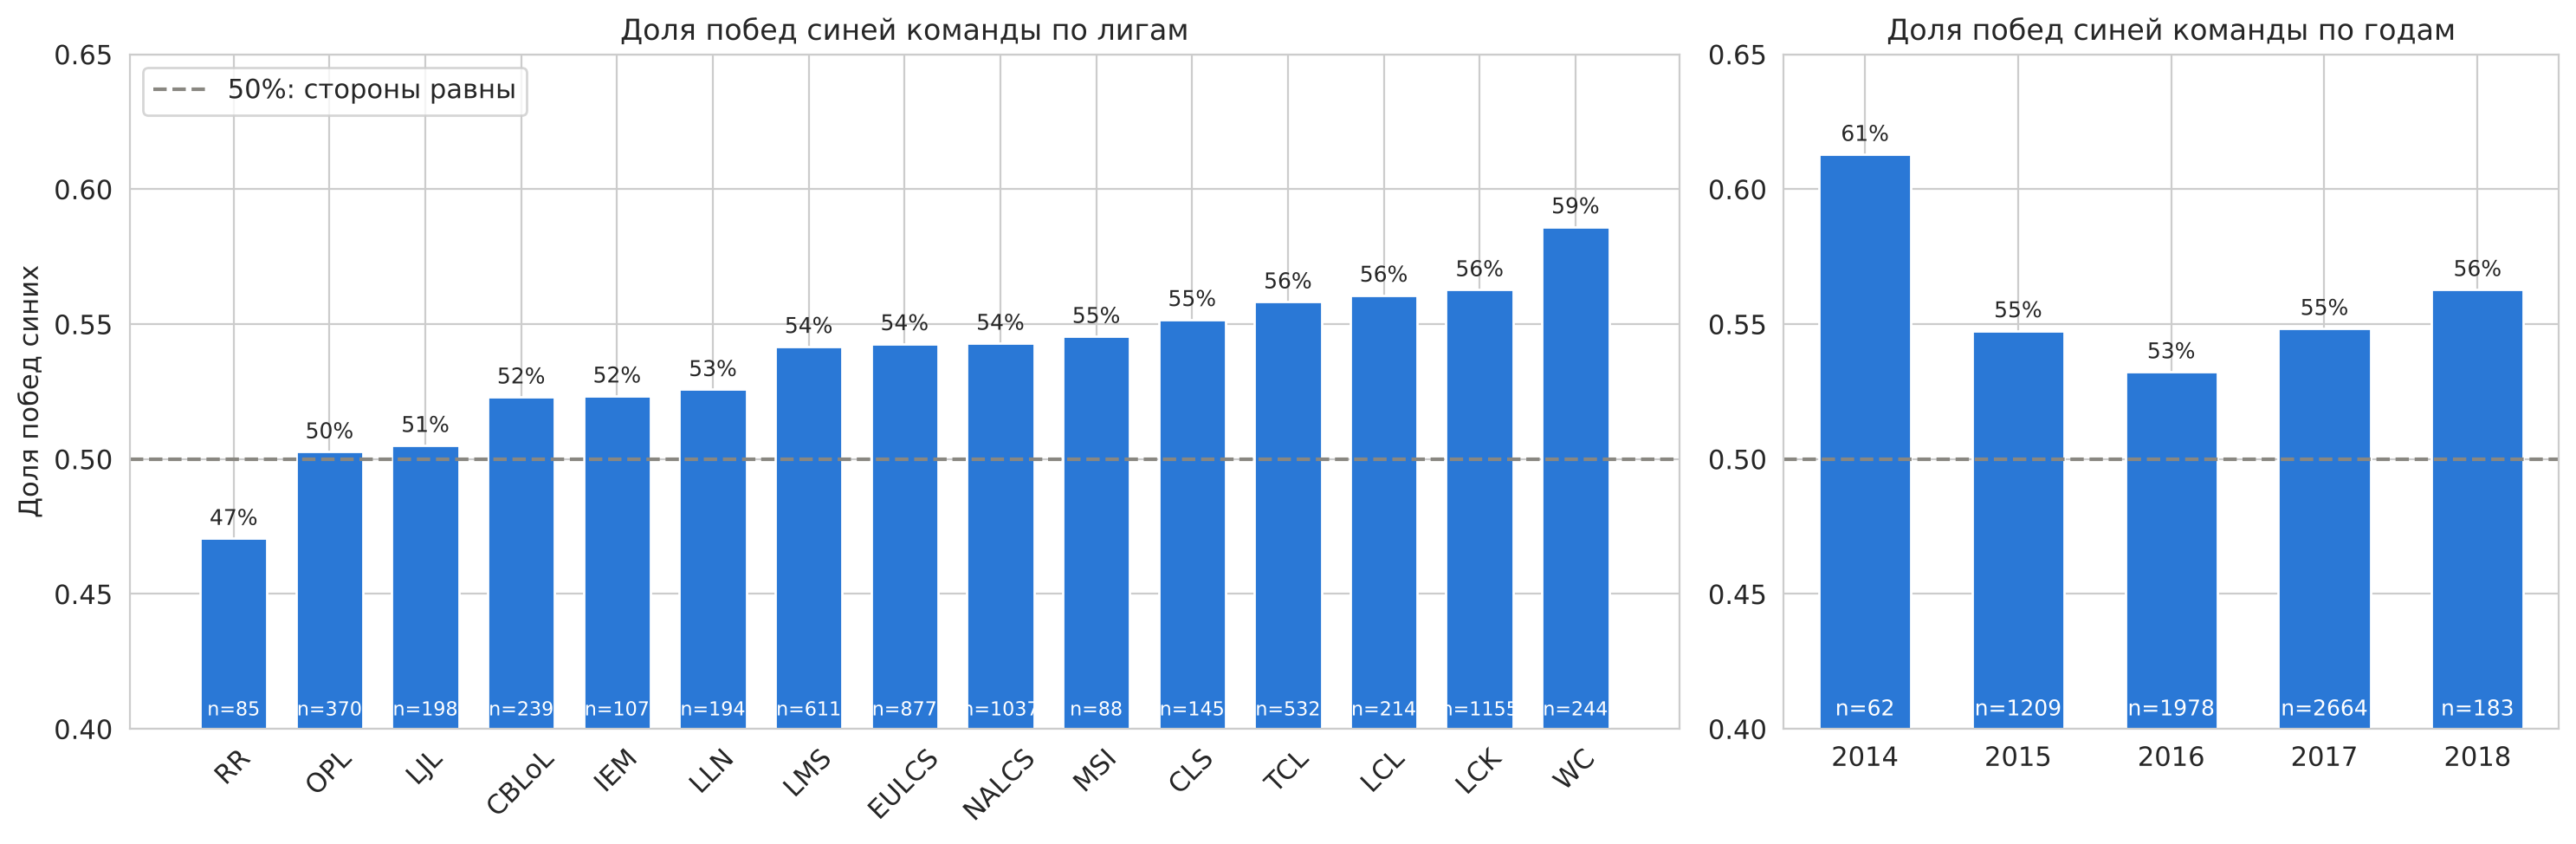

Доля побед синей команды в train: 0.544


In [12]:
train_matches = df.loc[train_ids]

by_league = train_matches.groupby('League')['blue_win'].agg(['mean', 'size']).sort_values('mean')
by_year = train_matches.groupby('Year')['blue_win'].agg(['mean', 'size'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})
axes[0].bar(by_league.index, by_league['mean'], color=C_BLUE, width=0.7)
axes[0].axhline(0.5, color=C_GRAY, linestyle='--', label='50%: стороны равны')
for i, (share, n) in enumerate(zip(by_league['mean'], by_league['size'])):
    axes[0].text(i, share + 0.005, f'{share:.0%}', ha='center', fontsize=9)
    axes[0].text(i, 0.405, f'n={n}', ha='center', fontsize=8, color='white')
axes[0].set_ylim(0.4, 0.65)
axes[0].set_title('Доля побед синей команды по лигам')
axes[0].set_ylabel('Доля побед синих')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(loc='upper left')

axes[1].bar(by_year.index.astype(str), by_year['mean'], color=C_BLUE, width=0.6)
axes[1].axhline(0.5, color=C_GRAY, linestyle='--')
for i, (share, n) in enumerate(zip(by_year['mean'], by_year['size'])):
    axes[1].text(i, share + 0.005, f'{share:.0%}', ha='center', fontsize=9)
    axes[1].text(i, 0.405, f'n={n}', ha='center', fontsize=9, color='white')
axes[1].set_ylim(0.4, 0.65)
axes[1].set_title('Доля побед синей команды по годам')
plt.tight_layout()
plt.savefig('figures/blue_side.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Доля побед синей команды в train: {train_matches['blue_win'].mean():.3f}")

### 3.2 Длительность матчей

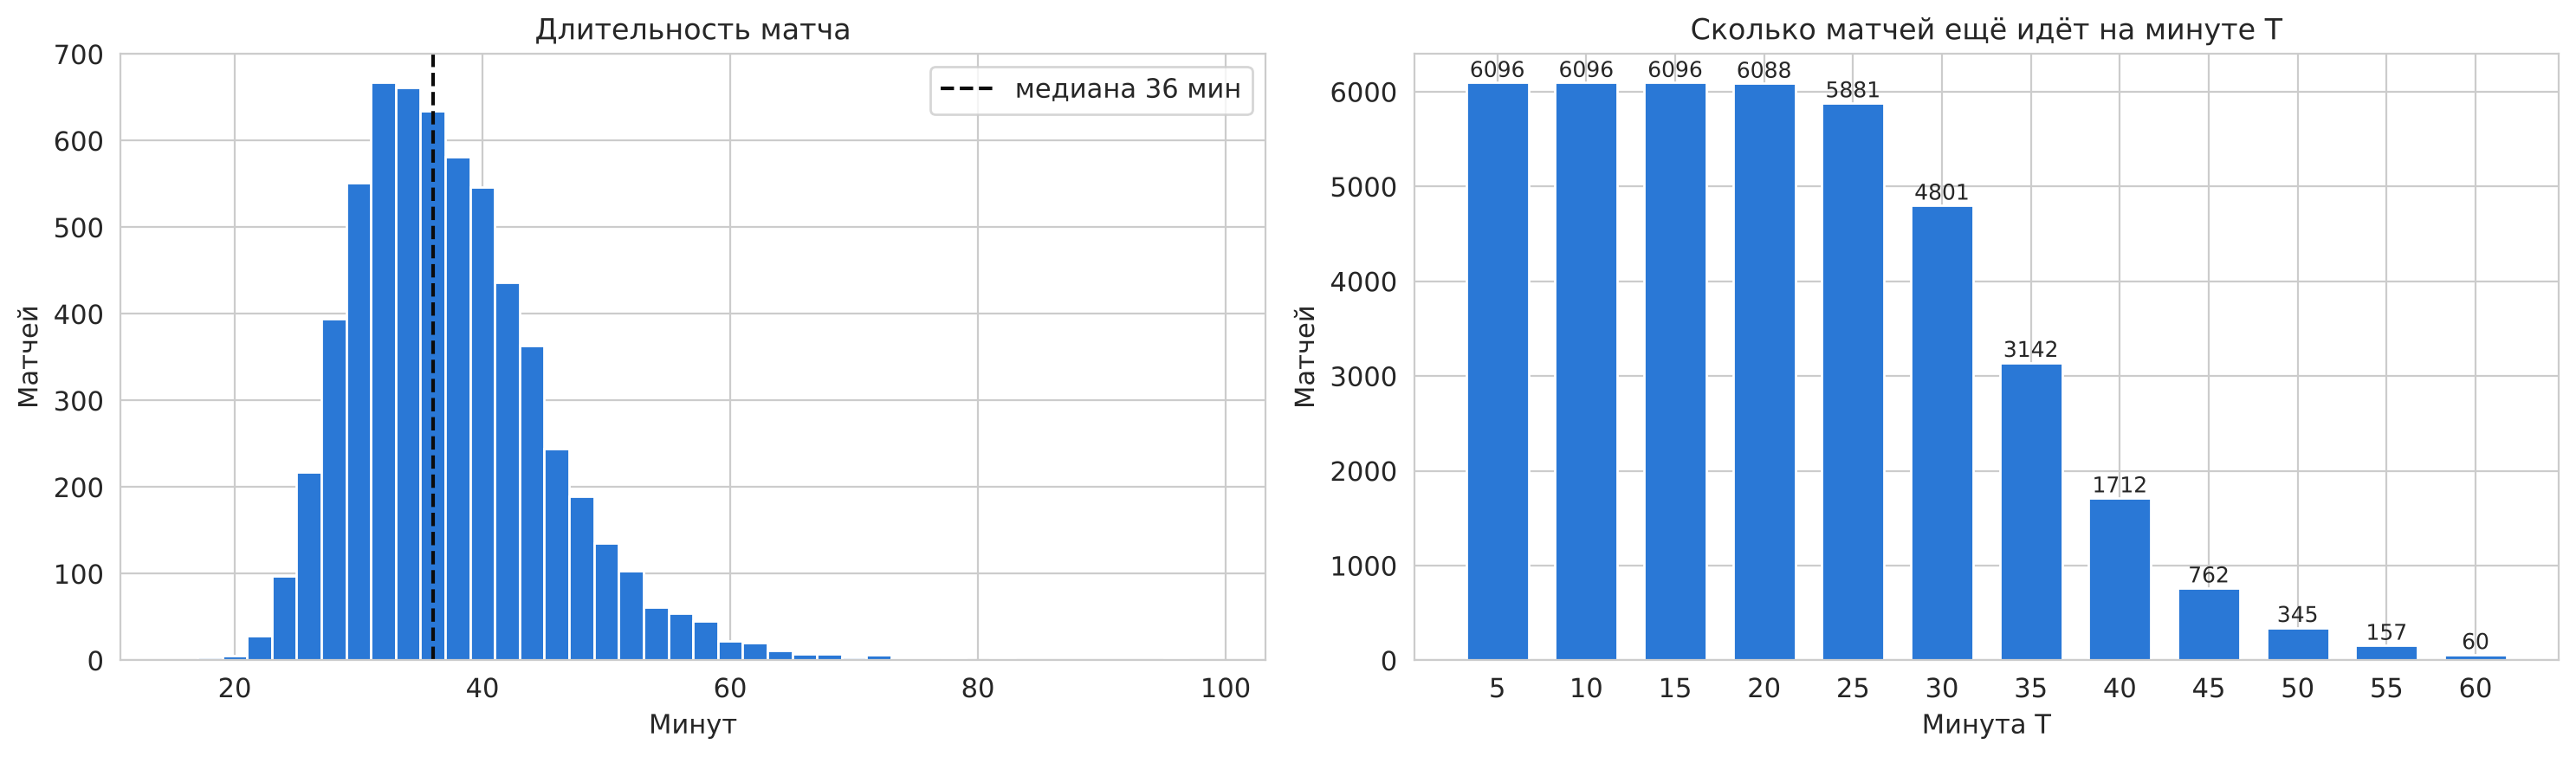

In [13]:
alive = pd.Series({T: (train_matches['gamelength'] > T).sum() for T in range(5, 61, 5)})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(train_matches['gamelength'], bins=range(15, 100, 2), color=C_BLUE, edgecolor='white')
axes[0].axvline(train_matches['gamelength'].median(), color='#0b0b0b', linestyle='--',
                label=f"медиана {train_matches['gamelength'].median():.0f} мин")
axes[0].set_title('Длительность матча')
axes[0].set_xlabel('Минут')
axes[0].set_ylabel('Матчей')
axes[0].legend()

axes[1].bar(alive.index, alive.values, width=3.5, color=C_BLUE)
for T, n in alive.items():
    axes[1].text(T, n + 60, str(n), ha='center', fontsize=9)
axes[1].set_title('Сколько матчей ещё идёт на минуте T')
axes[1].set_xlabel('Минута T')
axes[1].set_ylabel('Матчей')
axes[1].set_xticks(alive.index)
plt.tight_layout()
plt.savefig('figures/duration.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.3 Распределения признаков (20-я минута)

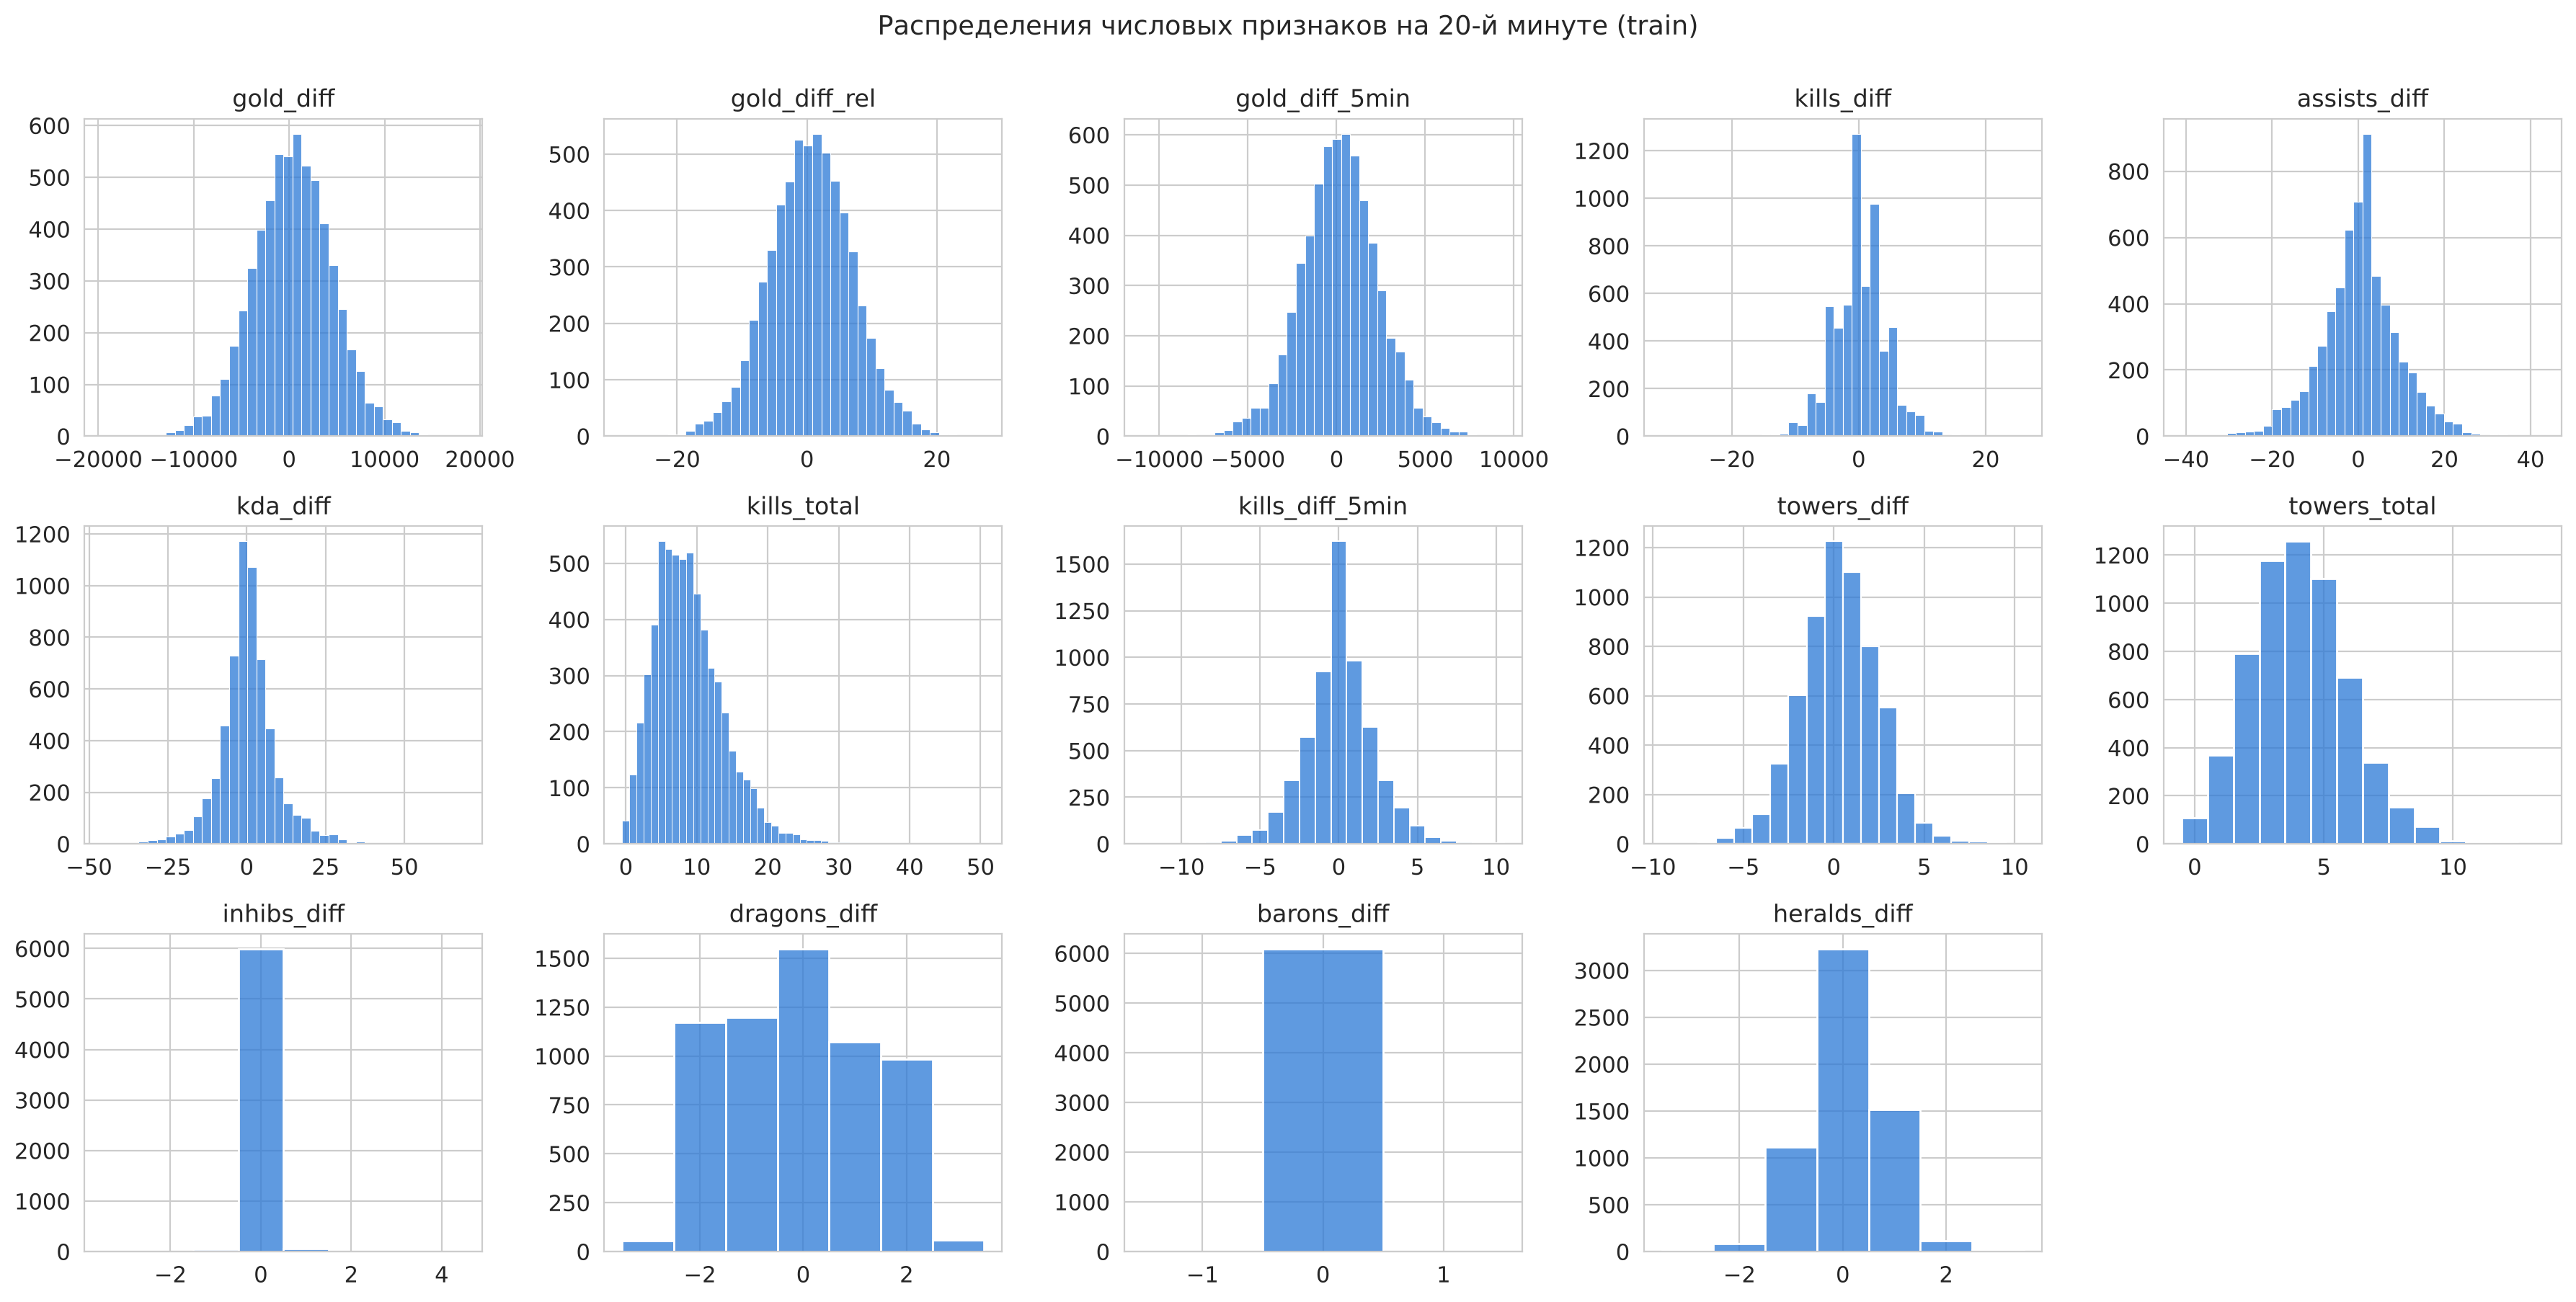

,mean,std,min,50%,max
gold_diff,396.32,4169.01,-19558.00,410.00,18361.00
gold_diff_rel,0.62,6.43,-28.44,0.64,27.28
gold_diff_5min,170.75,2181.32,-10970.00,174.00,9435.00
kills_diff,0.19,4.18,-31.00,0.00,26.00
assists_diff,0.35,8.96,-41.00,0.00,43.00
kda_diff,0.44,9.06,-45.71,0.10,69.00
kills_total,8.90,4.90,0.00,8.00,50.00
kills_diff_5min,0.05,2.22,-12.00,0.00,10.00
towers_diff,0.31,2.13,-9.00,0.00,10.00
towers_total,4.06,1.89,0.00,4.00,13.00


In [14]:
num_all = ['gold_diff', 'gold_diff_rel', 'gold_diff_5min', 'kills_diff', 'assists_diff', 'kda_diff', 'kills_total',
           'kills_diff_5min', 'towers_diff', 'towers_total', 'inhibs_diff', 'dragons_diff', 'barons_diff', 'heralds_diff']
train20 = train[train['minute'] == 20]

fig, axes = plt.subplots(3, 5, figsize=(18, 9))
axes = axes.flatten()
for i, col in enumerate(num_all):
    discrete = train20[col].nunique() < 40
    sns.histplot(train20[col], ax=axes[i], color=C_BLUE, discrete=discrete, bins=None if discrete else 40,
                 edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
axes[-1].axis('off')
plt.suptitle('Распределения числовых признаков на 20-й минуте (train)', y=1.0)
plt.tight_layout()
plt.savefig('figures/histograms.png', dpi=150, bbox_inches='tight')
plt.show()

train20[num_all].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

### 3.4 Box-plot признаков по победителю

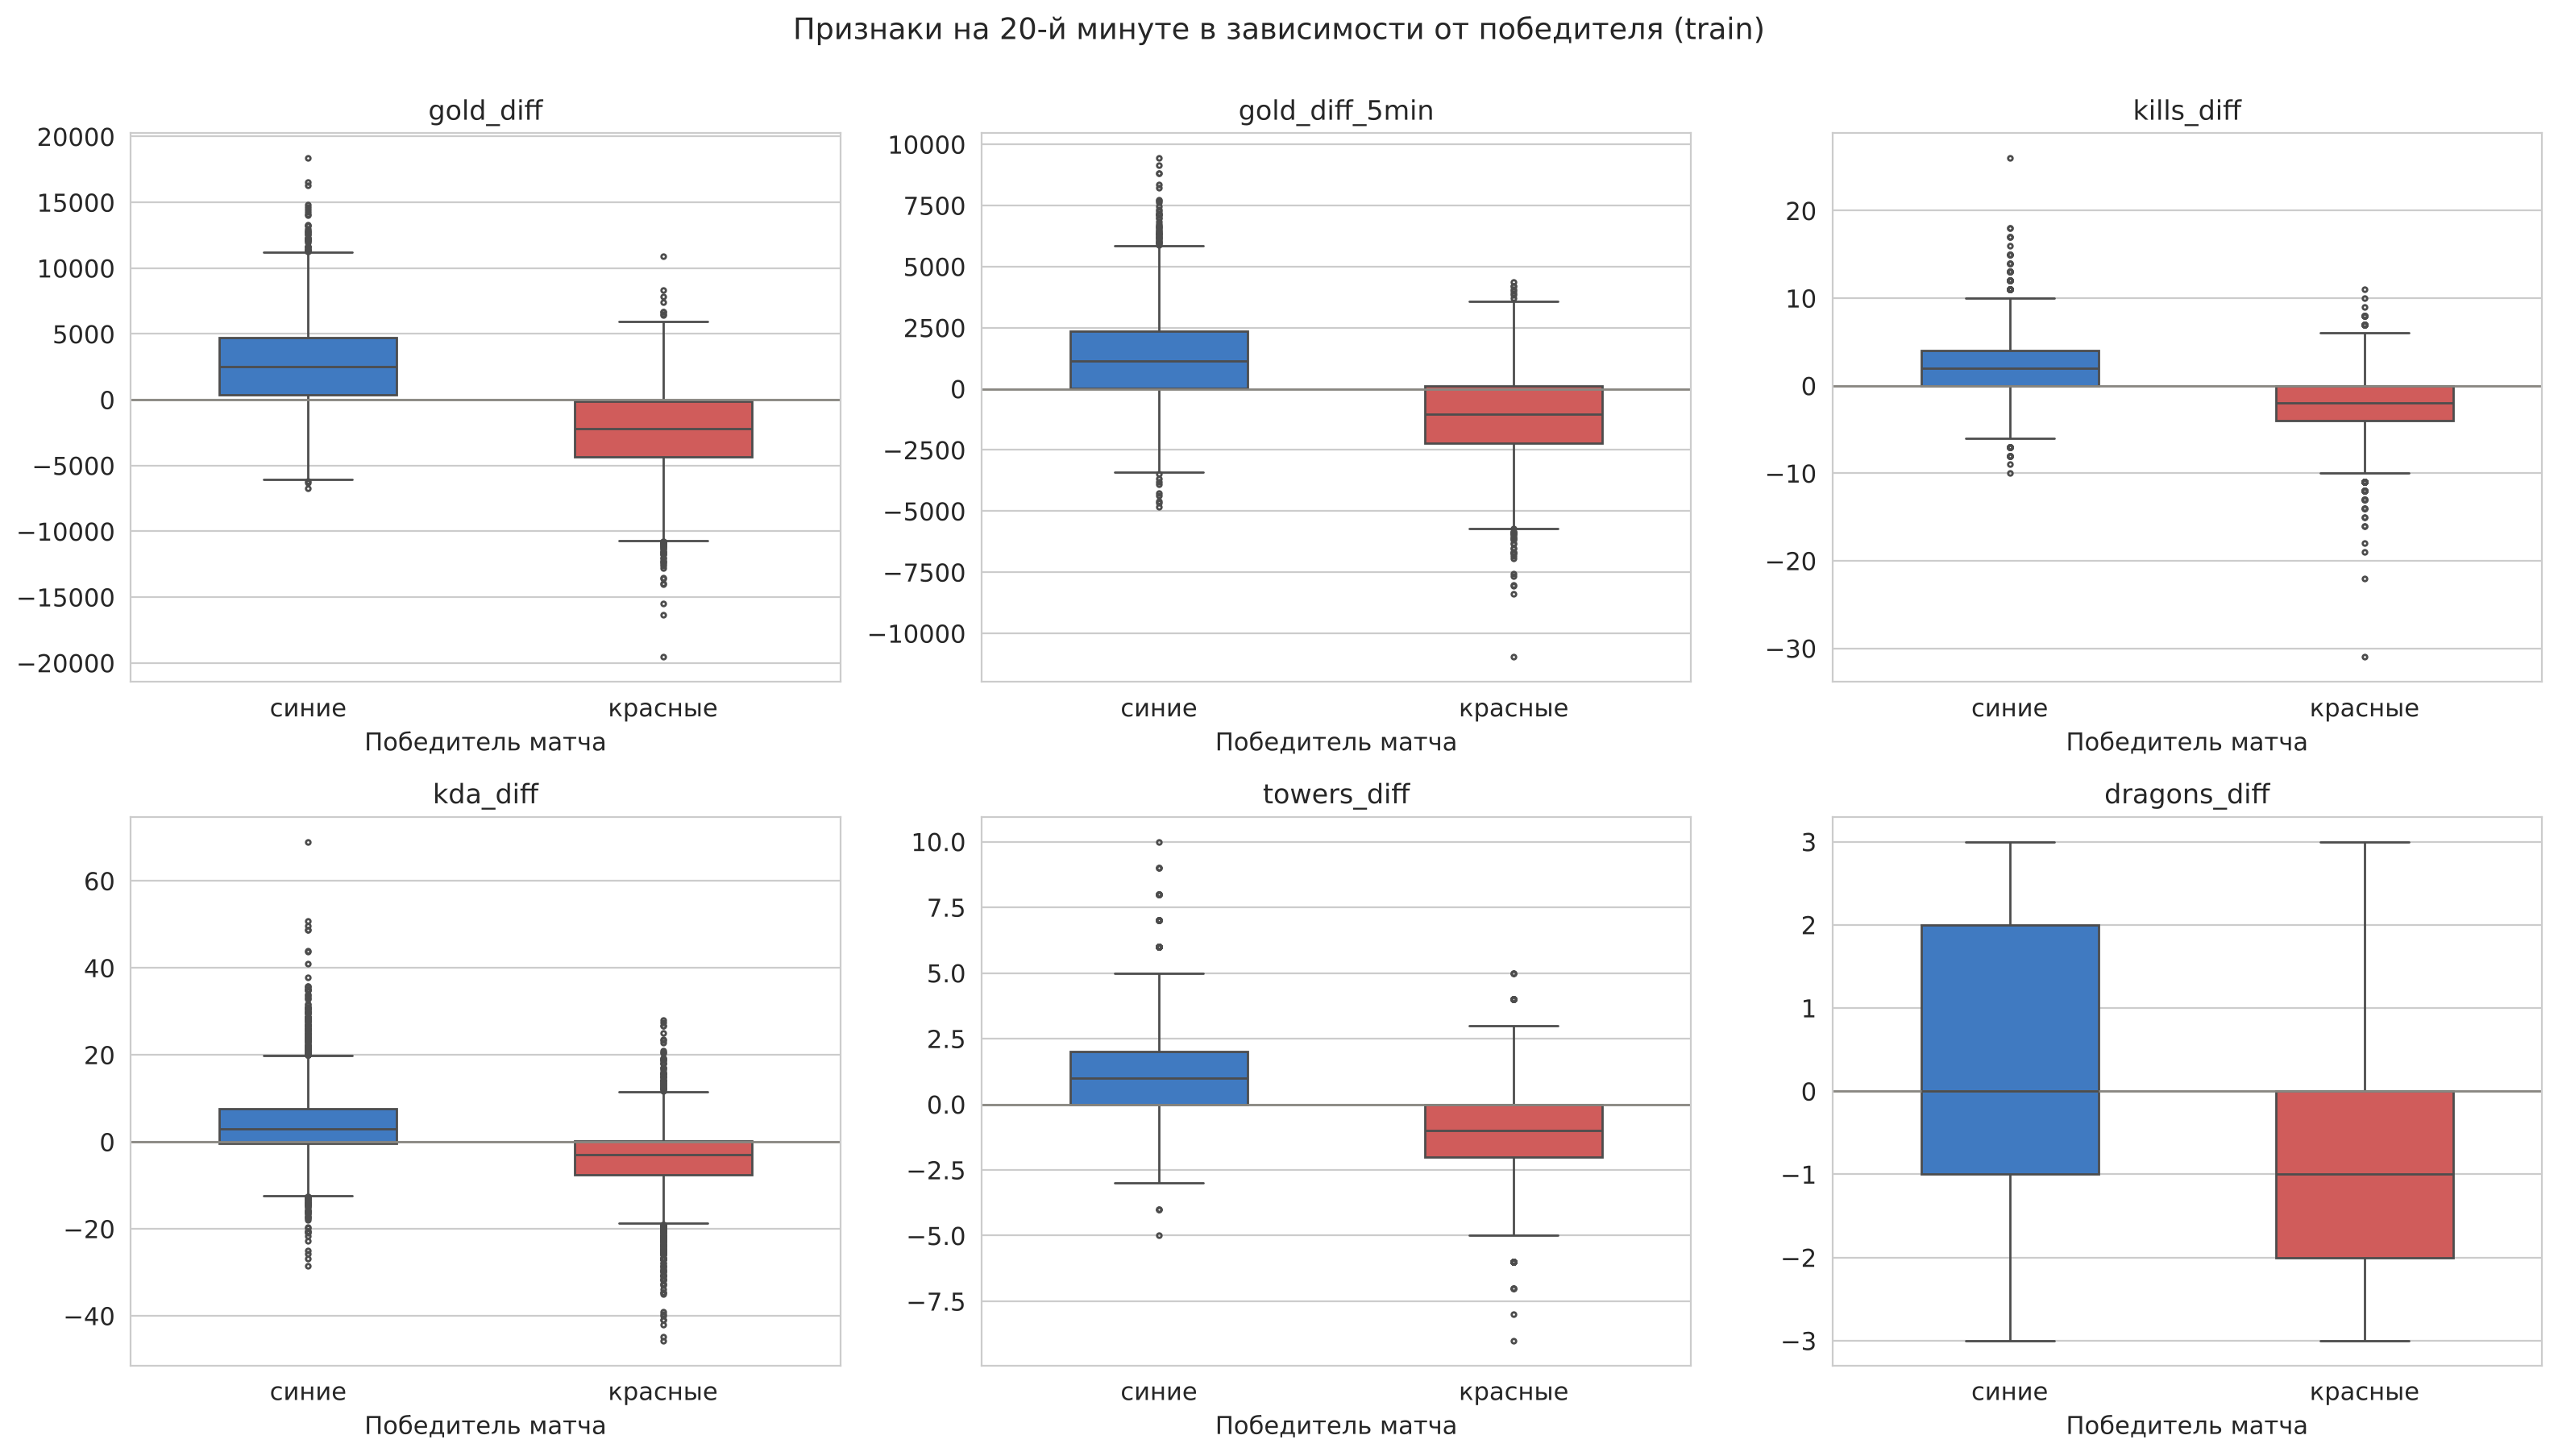

In [15]:
box_features = ['gold_diff', 'gold_diff_5min', 'kills_diff', 'kda_diff', 'towers_diff', 'dragons_diff']
plot20 = train20.assign(winner=train20[target].map({1: 'синие', 0: 'красные'}))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), box_features):
    sns.boxplot(data=plot20, x='winner', y=col, order=['синие', 'красные'], ax=ax,
                palette={'синие': C_BLUE, 'красные': C_RED}, width=0.5, fliersize=2)
    ax.axhline(0, color=C_GRAY, linewidth=1)
    ax.set_title(col)
    ax.set_xlabel('Победитель матча')
    ax.set_ylabel('')
plt.suptitle('Признаки на 20-й минуте в зависимости от победителя (train)', y=1.0)
plt.tight_layout()
plt.savefig('figures/boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.5 Перевес по золоту на разных минутах

Один и тот же перевес в золоте значит разное в начале и в конце игры. Слева — доля побед синих в зависимости от **абсолютного** перевеса на 10-й, 20-й и 30-й минуте, справа — в зависимости от **относительного** (в процентах от всего золота на карте).

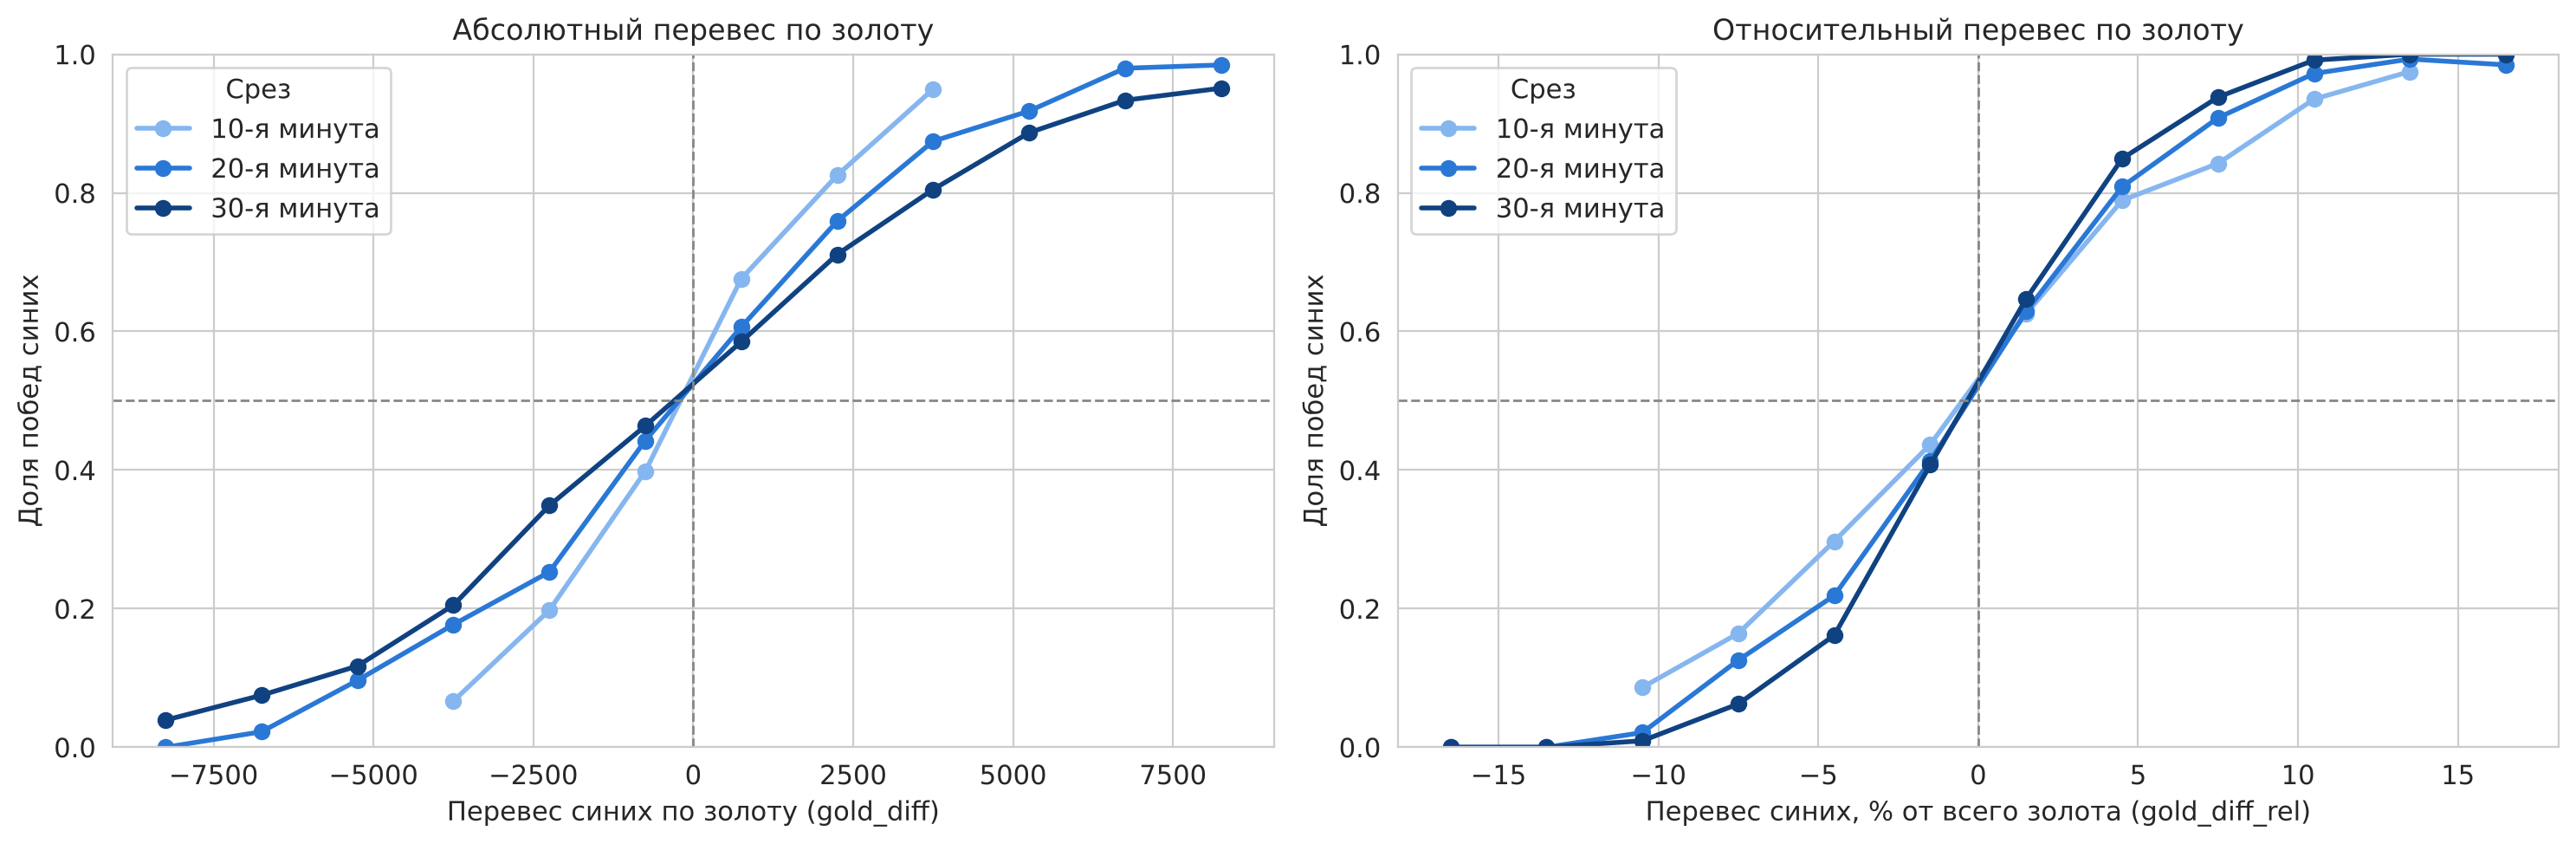

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for T in [10, 20, 30]:
    part = train[train['minute'] == T]

    bins_abs = np.arange(-9000, 9001, 1500)
    grouped = part.groupby(pd.cut(part['gold_diff'], bins_abs), observed=True)[target].agg(['mean', 'size'])
    grouped = grouped[grouped['size'] >= 30]
    axes[0].plot([iv.mid for iv in grouped.index], grouped['mean'], marker='o', color=C_MINUTES[T],
                 linewidth=2, label=f'{T}-я минута')

    bins_rel = np.arange(-18, 18.1, 3)
    grouped = part.groupby(pd.cut(part['gold_diff_rel'], bins_rel), observed=True)[target].agg(['mean', 'size'])
    grouped = grouped[grouped['size'] >= 30]
    axes[1].plot([iv.mid for iv in grouped.index], grouped['mean'], marker='o', color=C_MINUTES[T],
                 linewidth=2, label=f'{T}-я минута')

axes[0].set_title('Абсолютный перевес по золоту')
axes[0].set_xlabel('Перевес синих по золоту (gold_diff)')
axes[1].set_title('Относительный перевес по золоту')
axes[1].set_xlabel('Перевес синих, % от всего золота (gold_diff_rel)')
for ax in axes:
    ax.axhline(0.5, color=C_GRAY, linestyle='--', linewidth=1)
    ax.axvline(0, color=C_GRAY, linestyle='--', linewidth=1)
    ax.set_ylabel('Доля побед синих')
    ax.set_ylim(0, 1)
    ax.legend(title='Срез')
plt.tight_layout()
plt.savefig('figures/winrate_vs_gold.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.6 Корреляционная матрица и мультиколлинеарность

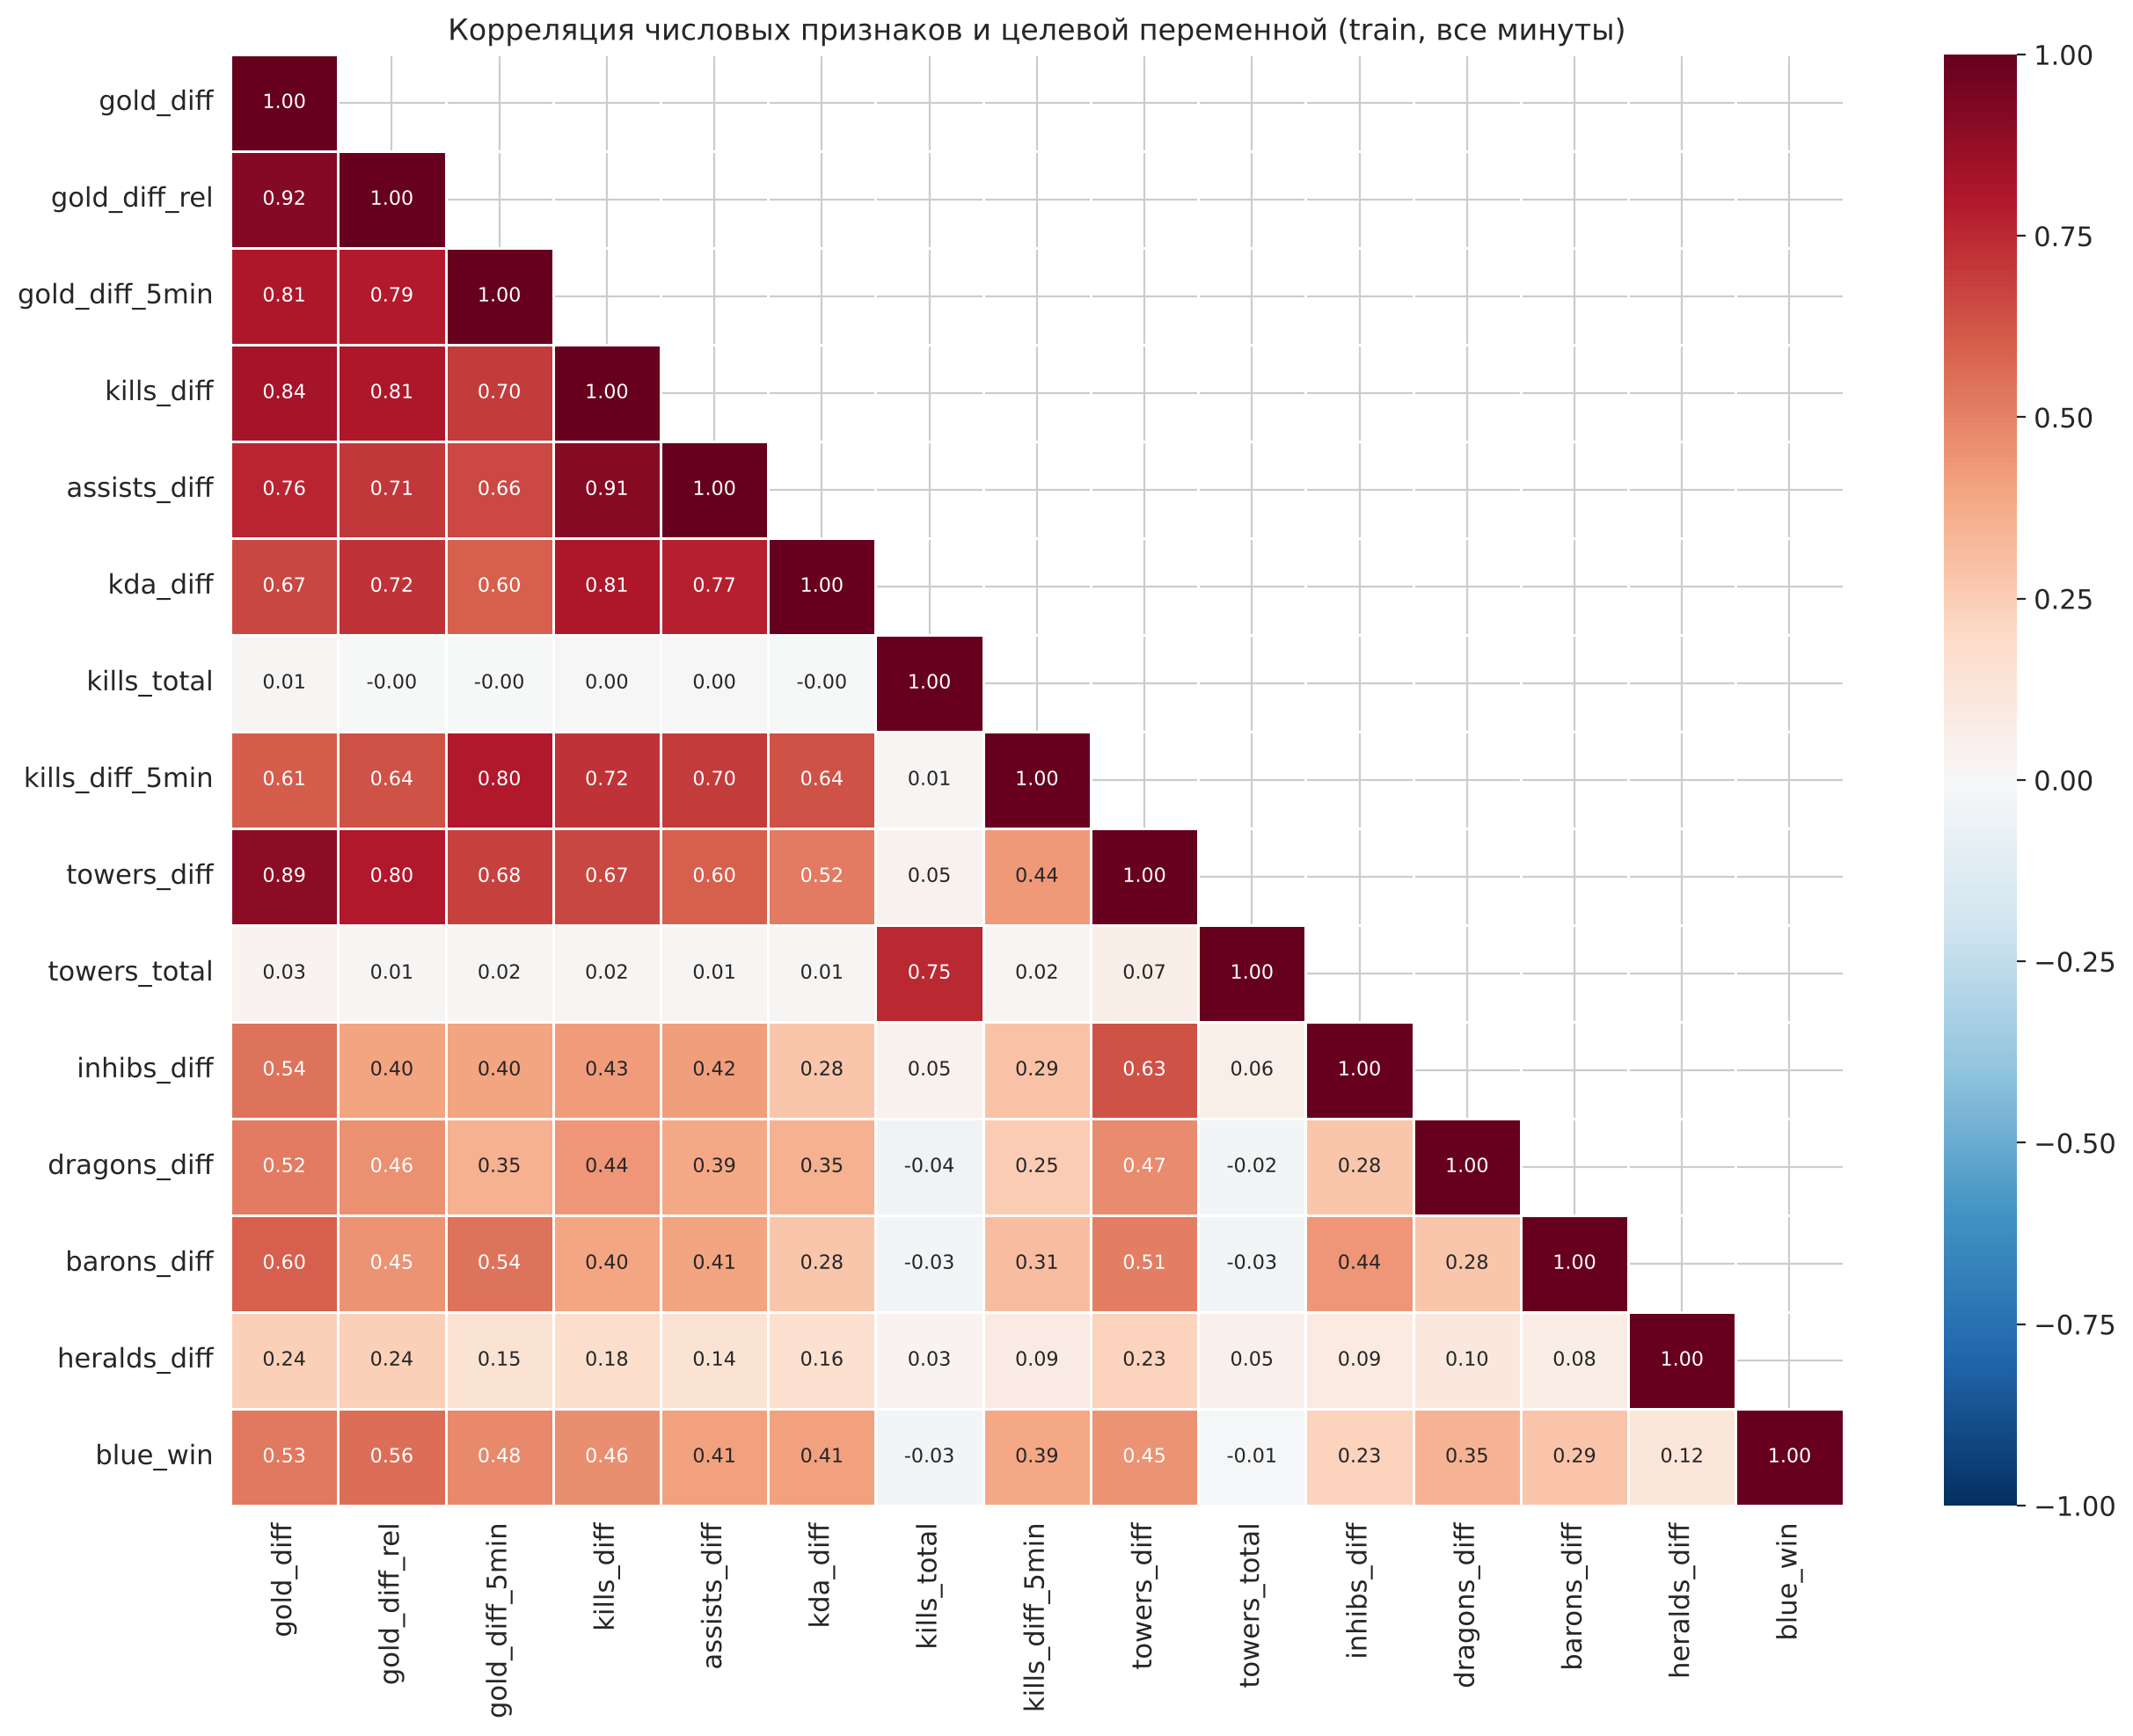

Корреляция с победой синих (blue_win):
gold_diff_rel      0.559
gold_diff          0.528
gold_diff_5min     0.478
kills_diff         0.464
towers_diff        0.449
assists_diff       0.412
kda_diff           0.406
kills_diff_5min    0.388
dragons_diff       0.350
barons_diff        0.285
inhibs_diff        0.232
heralds_diff       0.122
towers_total      -0.015
kills_total       -0.028


In [17]:
corr = train[num_all + [target]].corr()

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Корреляция числовых признаков и целевой переменной (train, все минуты)')
plt.tight_layout()
plt.savefig('figures/corr_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('Корреляция с победой синих (blue_win):')
print(corr[target].drop(target).sort_values(ascending=False).round(3).to_string())

In [18]:
from sklearn.linear_model import LinearRegression


def vif_table(data):
    """VIF признака = 1 / (1 - R^2), где R^2 — насколько хорошо признак предсказывается остальными."""
    values = {}
    for col in data.columns:
        others = data.drop(columns=col)
        r2 = LinearRegression().fit(others, data[col]).score(others, data[col])
        values[col] = 1 / (1 - r2)
    return pd.Series(values)


vif = pd.DataFrame({
    'VIF: все признаки': vif_table(train[num_all]),
    'VIF: без gold_diff': vif_table(train[[c for c in num_all if c != 'gold_diff']]),
}).round(1)
print(f"Корреляция gold_diff и gold_diff_rel: {corr.loc['gold_diff', 'gold_diff_rel']:.3f}")
print('Корреляция gold_diff_5min и gold_diff_rel по минутам:',
      {T: round(train.loc[train['minute'] == T, ['gold_diff_5min', 'gold_diff_rel']].corr().iloc[0, 1], 3) for T in [5, 10, 20, 30]})
print('Доля побед синих по минутам (train):', train.groupby('minute')[target].mean().round(3).to_dict())
vif

Корреляция gold_diff и gold_diff_rel: 0.922
Корреляция gold_diff_5min и gold_diff_rel по минутам: {5: np.float64(0.999), 10: np.float64(0.91), 20: np.float64(0.857), 30: np.float64(0.814)}
Доля побед синих по минутам (train): {5: 0.544, 10: 0.544, 15: 0.544, 20: 0.544, 25: 0.542, 30: 0.529, 35: 0.519, 40: 0.519}


,VIF: все признаки,VIF: без gold_diff
assists_diff,6.9,6.9
barons_diff,2.1,1.7
dragons_diff,1.4,1.4
gold_diff,25.1,NaN
gold_diff_5min,6.6,6.2
gold_diff_rel,9.9,6.7
heralds_diff,1.1,1.1
inhibs_diff,1.9,1.9
kda_diff,3.4,3.3
kills_diff,11.8,10.4


### 3.7 Выбросы

In [19]:
outlier_rows = []
for col in num_all:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({'Признак': col, 'Мин': train[col].min(), 'Нижняя граница': low, 'Верхняя граница': high,
                         'Макс': train[col].max(), 'Доля за границами, %': 100 * ((train[col] < low) | (train[col] > high)).mean()})
outliers = pd.DataFrame(outlier_rows).set_index('Признак').round(2)
outliers

,Мин,Нижняя граница,Верхняя граница,Макс,"Доля за границами, %"
Признак,,,,,
gold_diff,-21546.00,-7205.00,7867.00,23180.00,12.69
gold_diff_rel,-28.44,-14.29,15.16,27.28,1.68
gold_diff_5min,-12988.00,-4136.50,4387.50,13191.00,9.57
kills_diff,-31.00,-8.00,8.00,31.00,6.56
assists_diff,-73.00,-13.50,14.50,61.00,14.76
kda_diff,-71.83,-12.16,12.27,69.00,8.76
kills_total,0.00,-16.00,32.00,101.00,1.40
kills_diff_5min,-13.00,-4.00,4.00,14.00,5.41
towers_diff,-11.00,-4.00,4.00,11.00,8.42


In [20]:
# Что стоит за крайними значениями: самые большие перевесы по золоту
extreme = train.loc[train['gold_diff'].abs().sort_values(ascending=False).index[:5],
                    ['match_id', 'minute', 'gold_diff', 'kills_diff', 'towers_diff', 'inhibs_diff', 'barons_diff', target]]
extreme = extreme.merge(df[['League', 'Year', 'blueTeamTag', 'redTeamTag', 'gamelength']], left_on='match_id', right_index=True)
extreme

,match_id,minute,gold_diff,kills_diff,towers_diff,inhibs_diff,barons_diff,blue_win,League,Year,blueTeamTag,redTeamTag,gamelength
33737,6415,40,23180,8,9,3,2,1,WC,2014,EDG,AHQ,41
11805,2210,30,21621,25,9,2,1,1,LCK,2015,kt,CJE,31
11501,2155,35,-21546,-17,-10,-2,-1,0,LCK,2015,kt,CJE,36
7107,1319,40,-21412,-17,-4,-1,-2,0,EULCS,2015,UOL,FNC,43
13793,2570,30,20887,14,10,2,1,1,LCK,2016,SKT,JAG,31


### 3.8 Категориальные признаки: «кто первый»

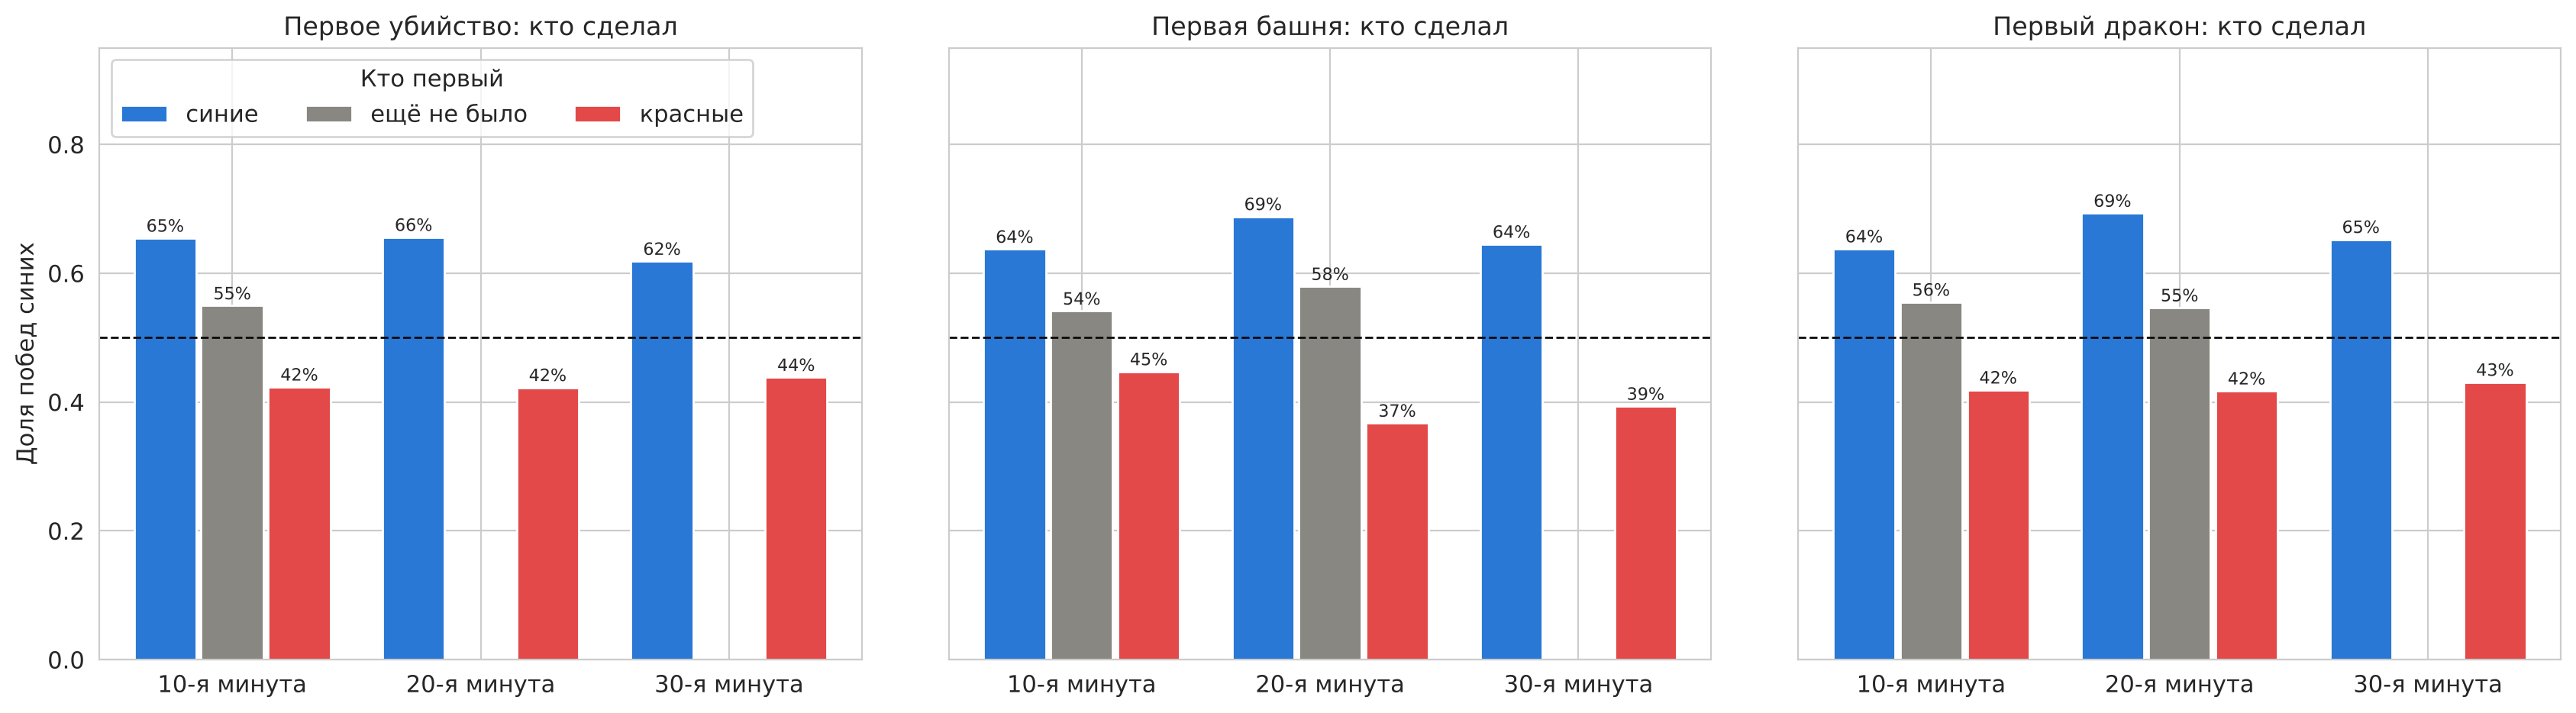

Доля побед синих                 Строк                
Минута                              10     20     30      10      20      30
Признак      Значение                                                       
first_blood  blue                0.654  0.656  0.618  2674.0  3111.0  2432.0
             none                0.549    NaN    NaN   941.0    42.0     0.0
             red                 0.423  0.422  0.438  2481.0  2935.0  2369.0
first_dragon blue                0.638  0.693  0.652   754.0  2695.0  2141.0
             none                0.555  0.546    NaN  4396.0   205.0    13.0
             red                 0.419  0.417  0.431   946.0  3188.0  2647.0
first_tower  blue                0.637  0.688  0.645  1020.0  3279.0  2597.0
             none                0.541  0.579    NaN  4224.0   107.0     0.0
             red                 0.447  0.367  0.393   852.0  2702.0  2204.0

In [21]:
cat_features = ['first_blood', 'first_tower', 'first_dragon']
cat_titles = {'first_blood': 'Первое убийство', 'first_tower': 'Первая башня', 'first_dragon': 'Первый дракон'}
value_names = {'blue': 'синие', 'none': 'ещё не было', 'red': 'красные'}
value_colors = {'blue': C_BLUE, 'none': C_GRAY, 'red': C_RED}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
cat_rows = []
for ax, col in zip(axes, cat_features):
    for j, value in enumerate(['blue', 'none', 'red']):
        shares = []
        for T in [10, 20, 30]:
            part = train[(train['minute'] == T) & (train[col] == value)]
            share = part[target].mean() if len(part) >= 100 else np.nan      # маленькие группы не показываем
            shares.append(share)
            cat_rows.append({'Признак': col, 'Значение': value, 'Минута': T, 'Строк': len(part), 'Доля побед синих': share})
        positions = np.arange(3) + (j - 1) * 0.27
        ax.bar(positions, shares, width=0.25, color=value_colors[value], label=value_names[value])
        for x, share in zip(positions, shares):
            if not np.isnan(share):
                ax.text(x, share + 0.01, f'{share:.0%}', ha='center', fontsize=8)
    ax.axhline(0.5, color='#0b0b0b', linestyle='--', linewidth=1)
    ax.set_xticks(np.arange(3))
    ax.set_xticklabels(['10-я минута', '20-я минута', '30-я минута'])
    ax.set_title(cat_titles[col] + ': кто сделал')
    ax.set_ylim(0, 0.95)
axes[0].set_ylabel('Доля побед синих')
axes[0].legend(title='Кто первый', loc='upper left', ncol=3)
plt.tight_layout()
plt.savefig('figures/firsts.png', dpi=150, bbox_inches='tight')
plt.show()

cat_table = pd.DataFrame(cat_rows).pivot_table(index=['Признак', 'Значение'], columns='Минута', values=['Строк', 'Доля побед синих'])
cat_table.round(3)

**Выводы из EDA.**

1. **У синей стороны устойчивое преимущество.** Синие побеждают в 54% матчей train, и это видно почти во всех лигах (от 47% до 59%) и во все годы (53–61%).
2. **Поздние срезы описывают только затянувшиеся матчи.** На 20-й минуте идут 6 088 из 6 096 матчей train, на 30-й — 4 801, на 40-й — 1 712.
3. **Главный сигнал — экономика.** Корреляция с победой синих: `gold_diff_rel` 0,56, `gold_diff` 0,53, `gold_diff_5min` 0,48, дальше разница убийств (0,46) и башен (0,45). На box-plot распределения у победителей и проигравших сдвинуты, но сильно перекрываются: перевес на 20-й минуте победу не гарантирует.
4. **Один и тот же перевес в золоте значит разное на разных минутах.** Перевес в 3 000–4 500 золота на 10-й минуте — это 95% побед, на 20-й — 87%, на 30-й — 80%. В относительных единицах кривые трёх стадий заметно ближе друг к другу.
5. **Признаки дублируют друг друга.** `gold_diff` и `gold_diff_rel` коррелируют на 0,92, VIF у `gold_diff` равен 25. Оставляем в модели только `gold_diff_rel`. У `kills_diff` VIF около 10 из-за `assists_diff` и `kda_diff`: все три считаются из одних и тех же убийств, поэтому коэффициенты линейной модели внутри этой группы ненадёжны.
6. **Выбросы — это настоящие разгромы, а не ошибки данных.** Самые большие перевесы по золоту (до 23 тыс.) — поздние минуты односторонних матчей, и все пять лидировавших команд победили. Для счётчиков вроде `barons_diff` правило 1,5 IQR не подходит: больше половины значений равны нулю. Строки не удаляем; проверка в разделе 5.2 показывает, что обрезка крайних значений качество не меняет.
7. **«Кто первый» работает, но слабо.** Если первое убийство, первую башню или первого дракона взяли синие, они побеждают в 62–69% случаев; если красные — красные побеждают в 55–63%.

## 4. Feature engineering

Исходные данные — списки по минутам и события. Все признаки ниже построены из них в разделе 2.3. Часть признаков — простые счётчики (разница убийств, башен), часть придумана под задачу:

| Признак | Как считается | Зачем |
|---|---|---|
| `gold_diff_rel` | перевес по золоту в % от всего золота обеих команд | 3 000 золота на 10-й минуте — разгром, на 35-й — почти равенство. Относительный перевес сравним на любой минуте, а модель у нас одна на все минуты |
| `gold_diff_5min` | изменение перевеса за последние 5 минут | Темп: кто набирает преимущество прямо сейчас. Команда может вести по золоту, но проигрывать последние минуты |
| `kda_diff` | (убийства + помощь) / смерти, разница между командами | KDA из темы задания, пересчитанный на команду |
| `kills_diff_5min` | разница убийств за последние 5 минут | Кто выиграл последние драки |
| `kills_total`, `towers_total` | сумма по обеим командам | «Темп» матча: кровавая игра или спокойная, сколько карты уже открыто. Сами по себе на победителя не указывают, но могут менять смысл остальных признаков |
| `first_blood`, `first_tower`, `first_dragon` | кто первым сделал событие | Ранние цели дают золото и контроль карты |

Проверим, насколько каждый признак сам по себе разделяет победы и поражения: ROC-AUC одного признака на трёх стадиях. 0,5 — признак бесполезен, 1 — идеально разделяет.

In [22]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, log_loss, brier_score_loss, roc_curve

single_rows = {}
for col in num_all:
    single_rows[col] = {f'{T}-я минута': roc_auc_score(train.loc[train['minute'] == T, target],
                                                         train.loc[train['minute'] == T, col]) for T in [10, 20, 30]}
    single_rows[col]['все минуты'] = roc_auc_score(train[target], train[col])
single_auc = pd.DataFrame(single_rows).T.sort_values('20-я минута', ascending=False)
single_auc.to_csv('results/single_feature_auc.csv')
single_auc.round(4)

,10-я минута,20-я минута,30-я минута,все минуты
gold_diff_rel,0.7436,0.8605,0.9207,0.8329
gold_diff,0.7430,0.8602,0.9205,0.8319
gold_diff_5min,0.7159,0.8218,0.8680,0.7931
kills_diff,0.6874,0.8097,0.8710,0.7814
towers_diff,0.5565,0.8054,0.8807,0.7597
kda_diff,0.6782,0.7937,0.8579,0.7688
assists_diff,0.6575,0.7728,0.8454,0.7513
kills_diff_5min,0.6593,0.7308,0.7999,0.7206
dragons_diff,0.5543,0.7194,0.7900,0.6943
heralds_diff,0.5034,0.6064,0.5731,0.5558


**Что видно по таблице.**

- **Лучший одиночный признак на любой стадии — перевес по золоту:** ROC-AUC 0,74 на 10-й минуте, 0,86 на 20-й, 0,92 на 30-й. На всех минутах вместе относительный перевес чуть лучше абсолютного (0,8329 против 0,8319), в модель идёт он.
- **Новые признаки информативны:** `gold_diff_5min` даёт 0,72 → 0,82 → 0,87, `kda_diff` — 0,68 → 0,79 → 0,86.
- **Объекты зависят от стадии.** Башни на 10-й минуте почти ничего не говорят (0,56), а к 20-й догоняют убийства (0,81). Бароны и ингибиторы появляются только к 30-й минуте (0,79 и 0,70).
- **Суммарные признаки** (`kills_total`, `towers_total`) сами по себе бесполезны (около 0,5), как и ожидалось.

Одиночный ROC-AUC показывает, насколько признак информативен сам по себе. Добавляет ли он что-то к золоту, показывают разделы 10 и 12.1.

In [23]:
# Итоговые наборы признаков
num_features = ['minute', 'gold_diff_rel', 'gold_diff_5min', 'kills_diff', 'assists_diff', 'kda_diff', 'kills_total',
                'kills_diff_5min', 'towers_diff', 'towers_total', 'inhibs_diff', 'dragons_diff', 'barons_diff',
                'heralds_diff']
features = num_features + cat_features

# Группы признаков (для анализа важности и ablation)
feature_groups = {
    'Экономика': ['gold_diff_rel', 'gold_diff_5min'],
    'Убийства (KDA)': ['kills_diff', 'assists_diff', 'kda_diff', 'kills_total', 'kills_diff_5min'],
    'Объекты': ['towers_diff', 'towers_total', 'inhibs_diff', 'dragons_diff', 'barons_diff', 'heralds_diff'],
    'Кто первый': ['first_blood', 'first_tower', 'first_dragon'],
    'Минута': ['minute'],
}

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print('Числовых признаков:', len(num_features), '| категориальных:', len(cat_features))
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

Числовых признаков: 14 | категориальных: 3
X_train: (39912, 17) | X_test: (10082, 17)


## 5. Классические модели

Предобработка лежит **внутри `Pipeline`**: `StandardScaler` для числовых признаков и `OneHotEncoder` для категориальных. На кросс-валидации она обучается только на обучающей части каждого фолда, поэтому утечки из валидации нет.

Метрика для подбора и сравнения — **ROC-AUC**; дополнительно считаем accuracy, F1 и log-loss. Кросс-валидация — 5 фолдов по матчам (раздел 2.4).

In [24]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier


def make_prep(num=None, cat=None):
    """Предобработка: масштабирование числовых признаков и one-hot для категориальных."""
    num = num_features if num is None else num
    cat = cat_features if cat is None else cat
    steps = [('num', StandardScaler(), num)]
    if cat:
        steps.append(('cat', OneHotEncoder(handle_unknown='ignore'), cat))
    return ColumnTransformer(steps)


def make_pipe(model, num=None, cat=None):
    return Pipeline([('prep', make_prep(num, cat)), ('model', model)])


def cv_auc(pipe, X=None, y=None, splits=None):
    """ROC-AUC на кросс-валидации по матчам: среднее и стандартное отклонение по фолдам."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    splits = cv_splits if splits is None else splits
    scores = cross_val_score(pipe, X, y, cv=splits, scoring='roc_auc')
    return scores.mean(), scores.std()

### 5.1 Точки отсчёта (baseline)

1. Всегда предсказывать победу синих (самый частый класс).
2. Правило «победит тот, у кого больше золота».
3. Логистическая регрессия на одном признаке `gold_diff_rel`.

In [25]:
base_rows = []

# 1. Всегда синие (обучать нечего, считаем на всём train)
base_rows.append({'Baseline': 'Всегда синие', 'Как посчитано': 'весь train', 'ROC-AUC': 0.5, 'Accuracy': y_train.mean()})

# 2. Правило по золоту (обучать нечего, считаем на всём train)
gold_rule = (train['gold_diff'] > 0).astype(int)
base_rows.append({'Baseline': 'У кого больше золота', 'Как посчитано': 'весь train',
                  'ROC-AUC': roc_auc_score(y_train, train['gold_diff_rel']), 'Accuracy': accuracy_score(y_train, gold_rule)})

# 3. Логистическая регрессия на одном признаке (5-fold CV по матчам)
pipe_gold = make_pipe(LogisticRegression(max_iter=2000), num=['gold_diff_rel'], cat=[])
baseline_cv_mean, baseline_cv_std = cv_auc(pipe_gold)
acc = cross_val_score(pipe_gold, X_train, y_train, cv=cv_splits, scoring='accuracy').mean()
base_rows.append({'Baseline': 'LogReg: только gold_diff_rel', 'Как посчитано': '5-fold CV',
                  'ROC-AUC': baseline_cv_mean, 'Accuracy': acc})

baselines = pd.DataFrame(base_rows).set_index('Baseline')
baselines.round(4)

,Как посчитано,ROC-AUC,Accuracy
Baseline,,,
Всегда синие,весь train,0.5000,0.5390
У кого больше золота,весь train,0.8329,0.7486
LogReg: только gold_diff_rel,5-fold CV,0.8329,0.7495


### 5.2 Логистическая регрессия (linear) — GridSearchCV

Подбираем силу регуляризации `C` и её тип: `l1_ratio=0` — это L2 (сжимает коэффициенты), `l1_ratio=1` — L1 (обнуляет лишние).

In [26]:
grid_lr = GridSearchCV(
    make_pipe(LogisticRegression(solver='saga', max_iter=5000, random_state=RANDOM_STATE)),
    param_grid={'model__C': [0.001, 0.01, 0.1, 1, 10], 'model__l1_ratio': [0, 1]},
    scoring='roc_auc', cv=cv_splits, n_jobs=-1, return_train_score=True)
grid_lr.fit(X_train, y_train)

res_lr = pd.DataFrame(grid_lr.cv_results_)[['param_model__C', 'param_model__l1_ratio', 'mean_train_score',
                                             'mean_test_score', 'std_test_score']]
res_lr.columns = ['C', 'l1_ratio', 'train ROC-AUC', 'CV ROC-AUC', 'std']
print('Лучшие параметры:', grid_lr.best_params_, f'| CV ROC-AUC {grid_lr.best_score_:.4f}')
res_lr.sort_values('CV ROC-AUC', ascending=False).round(4)

Лучшие параметры: {'model__C': 0.01, 'model__l1_ratio': 1} | CV ROC-AUC 0.8421


,C,l1_ratio,train ROC-AUC,CV ROC-AUC,std
3,0.010,1,0.8428,0.8421,0.0030
5,0.100,1,0.8433,0.8421,0.0030
7,1.000,1,0.8433,0.8420,0.0030
9,10.000,1,0.8433,0.8420,0.0030
8,10.000,0,0.8433,0.8420,0.0030
6,1.000,0,0.8433,0.8420,0.0030
4,0.100,0,0.8433,0.8420,0.0030
2,0.010,0,0.8430,0.8418,0.0030
1,0.001,1,0.8413,0.8411,0.0033
0,0.001,0,0.8400,0.8392,0.0033


In [27]:
# Проверка решения по выбросам: меняется ли качество, если обрезать крайние значения (1-й и 99-й перцентили train)
best_lr_params = {k.replace('model__', ''): v for k, v in grid_lr.best_params_.items()}
clip_cols = [c for c in num_features if c != 'minute']
low, high = train[clip_cols].quantile(0.01), train[clip_cols].quantile(0.99)
X_train_clipped = X_train.copy()
X_train_clipped[clip_cols] = X_train[clip_cols].clip(low, high, axis=1)

lr_for_check = make_pipe(LogisticRegression(solver='saga', max_iter=5000, random_state=RANDOM_STATE, **best_lr_params))
auc_raw = cv_auc(lr_for_check)
auc_clip = cv_auc(lr_for_check, X=X_train_clipped)
print(f'LogReg без обрезки выбросов: CV ROC-AUC {auc_raw[0]:.4f} ± {auc_raw[1]:.4f}')
print(f'LogReg с обрезкой выбросов:  CV ROC-AUC {auc_clip[0]:.4f} ± {auc_clip[1]:.4f}')

LogReg без обрезки выбросов: CV ROC-AUC 0.8421 ± 0.0030
LogReg с обрезкой выбросов:  CV ROC-AUC 0.8421 ± 0.0030


In [28]:
# Что оставила L1-регуляризация в лучшей модели
best_lr = grid_lr.best_estimator_
lr_coefs = pd.Series(best_lr['model'].coef_[0],
                     index=[n.split('__')[1] for n in best_lr['prep'].get_feature_names_out()])
nonzero = lr_coefs[lr_coefs.abs() > 1e-6]
print(f'Ненулевых коэффициентов: {len(nonzero)} из {len(lr_coefs)}')
print(nonzero.loc[nonzero.abs().sort_values(ascending=False).index].round(3).to_string())

Ненулевых коэффициентов: 11 из 23
gold_diff_rel       1.185
gold_diff_5min      0.404
dragons_diff        0.391
kills_diff          0.155
first_blood_blue   -0.079
inhibs_diff         0.060
barons_diff         0.039
towers_diff         0.020
first_blood_red     0.017
kills_diff_5min     0.013
kills_total        -0.012


### 5.3 Дерево решений (tree-based) — GridSearchCV

Лучшие параметры: {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 300} | CV ROC-AUC 0.8370


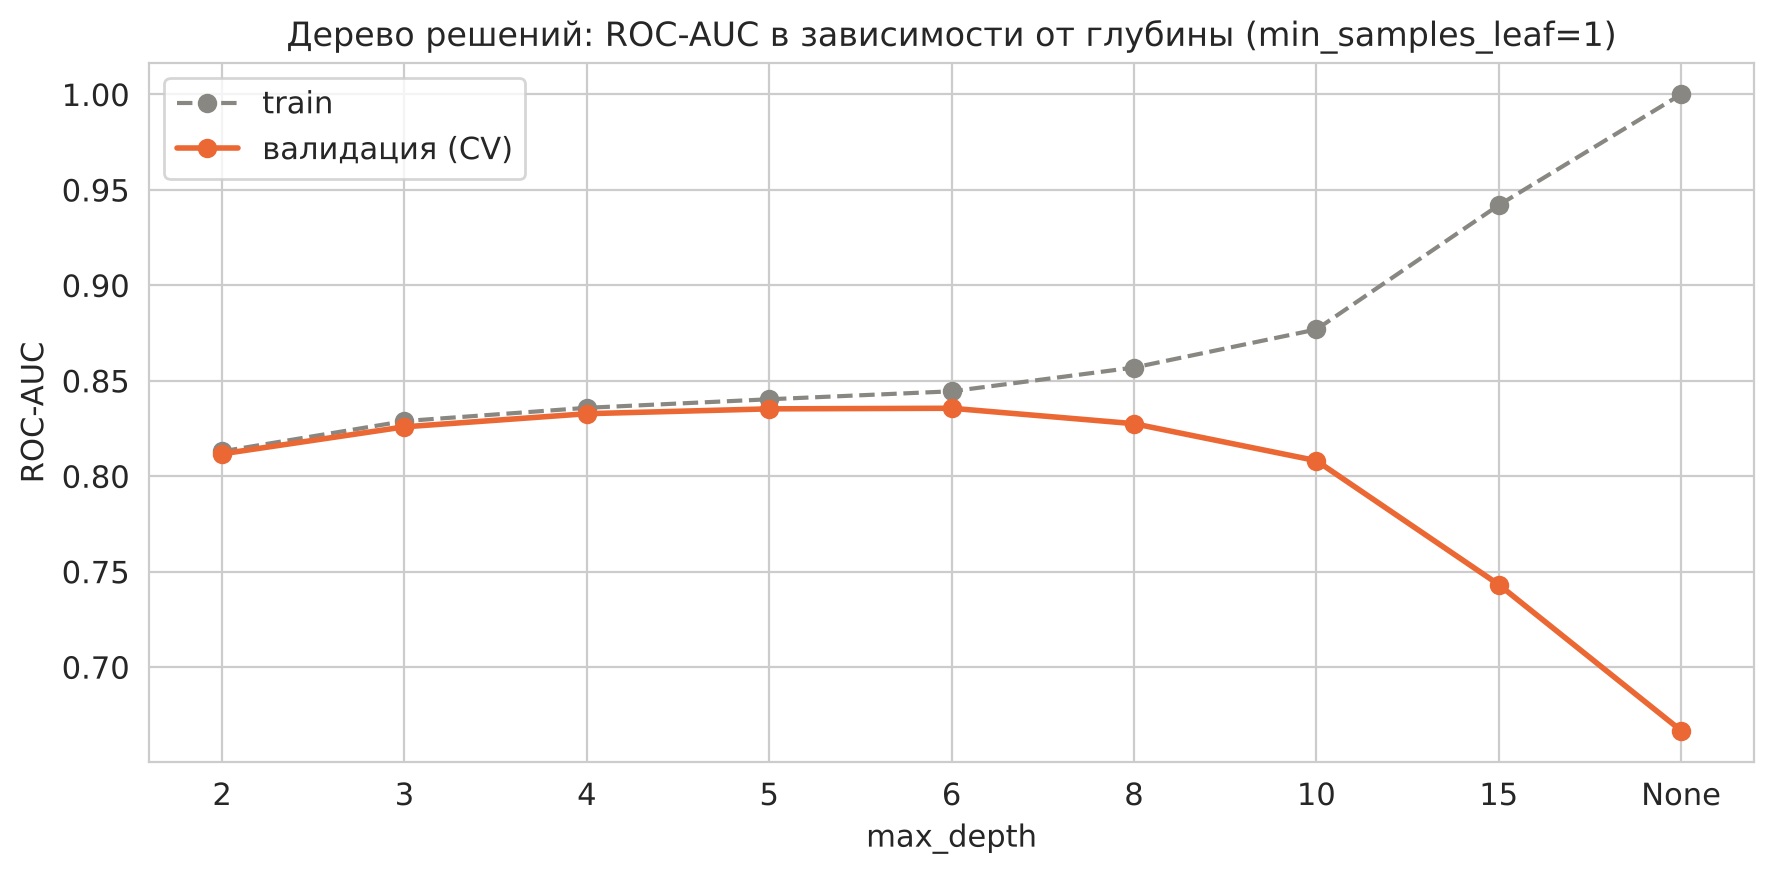

In [29]:
grid_dt = GridSearchCV(
    make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid={'model__max_depth': [2, 3, 4, 5, 6, 8, 10, 15, None],
                'model__min_samples_leaf': [1, 20, 100, 300],
                'model__criterion': ['gini', 'entropy']},
    scoring='roc_auc', cv=cv_splits, n_jobs=-1, return_train_score=True)
grid_dt.fit(X_train, y_train)
print('Лучшие параметры:', grid_dt.best_params_, f'| CV ROC-AUC {grid_dt.best_score_:.4f}')

# Переобучение дерева: качество на train и на валидации в зависимости от глубины (min_samples_leaf=1, gini)
res_dt = pd.DataFrame(grid_dt.cv_results_)
depth_curve = res_dt[(res_dt['param_model__min_samples_leaf'] == 1) & (res_dt['param_model__criterion'] == 'gini')].copy()
depth_curve['depth'] = depth_curve['param_model__max_depth'].apply(lambda d: 'None' if d is None else str(d))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depth_curve['depth'], depth_curve['mean_train_score'], marker='o', color=C_GRAY, linestyle='--', label='train')
ax.plot(depth_curve['depth'], depth_curve['mean_test_score'], marker='o', color=MODEL_COLORS['Decision Tree'],
        linewidth=2, label='валидация (CV)')
ax.set_title('Дерево решений: ROC-AUC в зависимости от глубины (min_samples_leaf=1)')
ax.set_xlabel('max_depth')
ax.set_ylabel('ROC-AUC')
ax.legend()
plt.tight_layout()
plt.savefig('figures/tree_depth.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.4 Random Forest (ensemble, bagging) — RandomizedSearchCV

In [30]:
rand_rf = RandomizedSearchCV(
    make_pipe(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={'model__max_depth': [6, 8, 10, 14, None],
                         'model__min_samples_leaf': [5, 20, 50, 100],
                         'model__max_features': ['sqrt', 0.3, 0.5]},
    n_iter=12, scoring='roc_auc', cv=cv_splits, random_state=RANDOM_STATE, n_jobs=1)
t0 = time.time()
rand_rf.fit(X_train, y_train)
print(f'Поиск занял {time.time() - t0:.0f} с')
print('Лучшие параметры:', rand_rf.best_params_, f'| CV ROC-AUC {rand_rf.best_score_:.4f}')

res_rf = pd.DataFrame(rand_rf.cv_results_)[['param_model__max_depth', 'param_model__min_samples_leaf',
                                             'param_model__max_features', 'mean_test_score', 'std_test_score']]
res_rf.columns = ['max_depth', 'min_samples_leaf', 'max_features', 'CV ROC-AUC', 'std']
res_rf.sort_values('CV ROC-AUC', ascending=False).round(4)

Поиск занял 216 с
Лучшие параметры: {'model__min_samples_leaf': 50, 'model__max_features': 0.3, 'model__max_depth': None} | CV ROC-AUC 0.8411


,max_depth,min_samples_leaf,max_features,CV ROC-AUC,std
5,None,50,0.3,0.8411,0.0043
10,14,50,0.5,0.8411,0.0041
6,10,20,0.5,0.8410,0.0041
11,None,50,sqrt,0.8402,0.0045
8,8,5,sqrt,0.8400,0.0048
4,8,20,sqrt,0.8400,0.0049
3,14,20,0.5,0.8399,0.0040
1,6,20,0.3,0.8399,0.0048
2,14,5,sqrt,0.8399,0.0045
9,None,20,0.5,0.8391,0.0039


### 5.5 Градиентный бустинг (ensemble, boosting) — RandomizedSearchCV

In [31]:
rand_gb = RandomizedSearchCV(
    make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    param_distributions={'model__learning_rate': [0.02, 0.05, 0.1, 0.2],
                         'model__max_iter': [100, 200, 300],
                         'model__max_depth': [2, 3, 4, 6],
                         'model__min_samples_leaf': [20, 50, 100, 200],
                         'model__l2_regularization': [0, 1, 10]},
    n_iter=20, scoring='roc_auc', cv=cv_splits, random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
rand_gb.fit(X_train, y_train)
print(f'Поиск занял {time.time() - t0:.0f} с')
print('Лучшие параметры:', rand_gb.best_params_, f'| CV ROC-AUC {rand_gb.best_score_:.4f}')

res_gb = pd.DataFrame(rand_gb.cv_results_)[['param_model__learning_rate', 'param_model__max_iter', 'param_model__max_depth',
                                             'param_model__min_samples_leaf', 'param_model__l2_regularization',
                                             'mean_test_score', 'std_test_score']]
res_gb.columns = ['learning_rate', 'max_iter', 'max_depth', 'min_samples_leaf', 'l2', 'CV ROC-AUC', 'std']
res_gb.sort_values('CV ROC-AUC', ascending=False).head(8).round(4)

Поиск занял 37 с
Лучшие параметры: {'model__min_samples_leaf': 200, 'model__max_iter': 200, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__l2_regularization': 0} | CV ROC-AUC 0.8417


,learning_rate,max_iter,max_depth,min_samples_leaf,l2,CV ROC-AUC,std
17,0.05,200,2,200,0,0.8417,0.0035
6,0.05,200,3,200,1,0.8416,0.0036
2,0.20,300,2,100,1,0.8416,0.0034
3,0.10,200,3,100,10,0.8416,0.0035
14,0.20,200,2,100,10,0.8416,0.0033
16,0.05,100,4,50,1,0.8415,0.0035
7,0.02,200,4,50,0,0.8415,0.0036
19,0.20,300,2,50,0,0.8414,0.0033


In [32]:
# У HistGradientBoostingClassifier ранняя остановка по умолчанию включается сама, если строк больше 10 000
gb_model = rand_gb.best_estimator_['model']
print('Ранняя остановка включена:', gb_model.do_early_stopping_, '| доля строк, отложенных для неё:', gb_model.validation_fraction)
print('Итераций сделано:', gb_model.n_iter_, 'из', gb_model.max_iter)

Ранняя остановка включена: True | доля строк, отложенных для неё: 0.1
Итераций сделано: 200 из 200


In [33]:
# Итог по классическим моделям: лучшие конфигурации и их качество на кросс-валидации
searches = {'Logistic Regression': grid_lr, 'Decision Tree': grid_dt, 'Random Forest': rand_rf, 'Gradient Boosting': rand_gb}
classic_rows = []
for name, search in searches.items():
    i = search.best_index_
    classic_rows.append({'Модель': name,
                         'Лучшие гиперпараметры': ', '.join(f"{k.replace('model__', '')}={v}" for k, v in search.best_params_.items()),
                         'CV ROC-AUC': search.cv_results_['mean_test_score'][i],
                         'std по фолдам': search.cv_results_['std_test_score'][i]})
classic_table = pd.DataFrame(classic_rows).set_index('Модель')
pd.set_option('display.max_colwidth', 120)
classic_table.round(4)

,Лучшие гиперпараметры,CV ROC-AUC,std по фолдам
Модель,,,
Logistic Regression,"C=0.01, l1_ratio=1",0.8421,0.0030
Decision Tree,"criterion=entropy, max_depth=10, min_samples_leaf=300",0.8370,0.0031
Random Forest,"min_samples_leaf=50, max_features=0.3, max_depth=None",0.8411,0.0043
Gradient Boosting,"min_samples_leaf=200, max_iter=200, max_depth=2, learning_rate=0.05, l2_regularization=0",0.8417,0.0035


### 5.6 Проверка: что будет, если делить на фолды строки, а не матчи

В разделе 2.4 мы решили делить на фолды матчи. Проверим, насколько это важно: посчитаем ту же кросс-валидацию с обычным `StratifiedKFold` по строкам, когда минуты одного матча попадают и в обучение, и в валидацию.

In [34]:
from sklearn.model_selection import StratifiedKFold

row_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
deep_forest = make_pipe(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))   # без ограничений глубины

split_rows = []
for name, pipe in [('Logistic Regression', grid_lr.best_estimator_), ('Gradient Boosting', rand_gb.best_estimator_),
                   ('Random Forest (подобранный)', rand_rf.best_estimator_), ('Random Forest без ограничений', deep_forest)]:
    by_rows = cv_auc(pipe, splits=row_splits)[0]
    by_matches = cv_auc(pipe)[0]
    split_rows.append({'Модель': name, 'Фолды по строкам': by_rows, 'Фолды по матчам': by_matches,
                       'Завышение': by_rows - by_matches})
split_check = pd.DataFrame(split_rows).set_index('Модель')
split_check.to_csv('results/split_check.csv')
split_check.round(4)

,Фолды по строкам,Фолды по матчам,Завышение
Модель,,,
Logistic Regression,0.8425,0.8421,0.0004
Gradient Boosting,0.8424,0.8417,0.0006
Random Forest (подобранный),0.8423,0.8411,0.0012
Random Forest без ограничений,0.8225,0.8167,0.0059


**Итоги по классическим моделям.**

- **Все подобранные модели дают CV ROC-AUC от 0,837 до 0,842.** Логистическая регрессия (0,8421), бустинг (0,8417) и случайный лес (0,8411) отличаются меньше, чем на одно стандартное отклонение по фолдам (0,003–0,004). Дерево хуже (0,8370). Точка отсчёта на одном золоте — 0,8329.
- **Логистическая регрессия почти не зависит от силы регуляризации:** при `C` от 0,01 до 10 качество 0,8418–0,8421. Лучшей вышла L1 с `C = 0,01`: она обнулила 12 из 23 коэффициентов без потери качества. Обнулились дубли (`assists_diff`, `kda_diff`), первая башня, первый дракон, герольды, `towers_total` и `minute`.
- **Почему обнулилась минута.** В линейной модели она может только сдвигать шанс синих на одну и ту же величину при любом перевесе, а доля побед синих от минуты зависит слабо: 54,4% на 5–20-й минутах и 51,9% на 40-й (раздел 3.6).
- **Дерево без ограничений переобучается полностью:** ROC-AUC 1,0 на train и около 0,67 на валидации. Лучший вариант — глубина 10 при `min_samples_leaf = 300`.
- **Бустинг выбрал деревья глубины 2:** сложные взаимодействия признаков ему не понадобились. У него по умолчанию включена ранняя остановка, которая сама откладывает 10% строк (по строкам, а не по матчам). На оценки CV и test это не влияет, а в итоговой модели остановка не сработала: сделаны все 200 итераций.
- **Фолды по матчам.** Если делить на фолды строки, качество завышается на 0,0004–0,0012 у подобранных моделей и на 0,006 у случайного леса без ограничений.

## 6. Нейронная сеть MLP (PyTorch)

Сеть получает те же признаки после той же предобработки (`StandardScaler` + one-hot). Для подбора архитектуры и числа эпох отделяем от train валидационную часть — тоже **по матчам** (20% матчей). Тестовая выборка в подборе не участвует.

Обучение: функция потерь `BCEWithLogitsLoss` (бинарная кросс-энтропия), оптимизатор Adam, mini-batch 256, активация ReLU. Регуляризация: Dropout и weight decay.

In [35]:
import torch.nn as nn

train_match_table = train[['match_id', target]].drop_duplicates()
main_ids, val_ids = train_test_split(train_match_table['match_id'], test_size=0.2, random_state=RANDOM_STATE,
                                     stratify=train_match_table[target])
is_val = train['match_id'].isin(val_ids).values
X_main, y_main = X_train[~is_val], y_train[~is_val]
X_val, y_val = X_train[is_val], y_train[is_val]

prep_mlp = make_prep()
X_main_p = prep_mlp.fit_transform(X_main)      # fit только на обучающей части
X_val_p = prep_mlp.transform(X_val)
print('Размер входа сети:', X_main_p.shape[1], '| train:', X_main_p.shape[0], '| val:', X_val_p.shape[0])

Размер входа сети: 23 | train: 31969 | val: 7943


In [36]:
def make_mlp(input_dim, hidden=(64,), dropout=0.5):
    """Полносвязная сеть: [Linear -> ReLU -> Dropout] для каждого скрытого слоя и один выходной нейрон."""
    layers = []
    prev = input_dim
    for h in hidden:
        layers.append(nn.Linear(prev, h))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)


def mlp_proba(model, X):
    """Вероятность победы синих."""
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(np.asarray(X), dtype=torch.float32))
    return torch.sigmoid(logits).numpy().ravel()


def train_mlp(X_tr, y_tr, X_va=None, y_va=None, hidden=(64,), dropout=0.5, weight_decay=1e-3,
              lr=1e-3, epochs=30, batch_size=256):
    """Обучение MLP. Если передана валидация, после каждой эпохи пишем loss и ROC-AUC на train и val."""
    torch.manual_seed(RANDOM_STATE)
    X_t = torch.tensor(np.asarray(X_tr), dtype=torch.float32)
    y_t = torch.tensor(np.asarray(y_tr), dtype=torch.float32).reshape(-1, 1)

    model = make_mlp(X_t.shape[1], hidden, dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()
    history = {'train_loss': [], 'val_loss': [], 'train_auc': [], 'val_auc': []}

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X_t))               # перемешиваем объекты каждую эпоху
        for start in range(0, len(X_t), batch_size):
            idx = order[start:start + batch_size]
            optimizer.zero_grad()                      # обнуляем градиенты
            loss = criterion(model(X_t[idx]), y_t[idx])
            loss.backward()                            # backpropagation
            optimizer.step()                           # шаг оптимизатора

        if X_va is not None:
            model.eval()
            with torch.no_grad():
                X_v = torch.tensor(np.asarray(X_va), dtype=torch.float32)
                y_v = torch.tensor(np.asarray(y_va), dtype=torch.float32).reshape(-1, 1)
                history['train_loss'].append(criterion(model(X_t), y_t).item())
                history['val_loss'].append(criterion(model(X_v), y_v).item())
            history['train_auc'].append(roc_auc_score(y_tr, mlp_proba(model, X_tr)))
            history['val_auc'].append(roc_auc_score(y_va, mlp_proba(model, X_va)))
    return model, history

### 6.1 Выбор архитектуры

На входе 23 числа: 14 числовых признаков и 9 столбцов one-hot. Задача табличная и небольшая, поэтому сравниваем сети от маленькой до заведомо избыточной: если большая сеть не лучше маленькой, усложнять нет смысла. Активация ReLU: она не насыщается и не даёт затухающих градиентов, для скрытых слоёв это стандартный выбор.

In [37]:
MLP_DROPOUT = 0.5      # доля отключаемых нейронов
MLP_WD = 1e-3          # weight decay (L2-штраф на веса)
ARCH_EPOCHS = 40

architectures = {'1 слой: 16': (16,), '1 слой: 64': (64,), '2 слоя: 64-32': (64, 32), '3 слоя: 128-64-32': (128, 64, 32)}
arch_rows = []
for name, hidden in architectures.items():
    t0 = time.time()
    model, hist = train_mlp(X_main_p, y_main, X_val_p, y_val, hidden=hidden, dropout=MLP_DROPOUT,
                            weight_decay=MLP_WD, epochs=ARCH_EPOCHS)
    best = int(np.argmin(hist['val_loss']))
    arch_rows.append({'Архитектура': name, 'Параметров': sum(p.numel() for p in model.parameters()),
                      'Лучшая эпоха': best + 1, 'Лучший val loss': hist['val_loss'][best],
                      'Val ROC-AUC на лучшей эпохе': hist['val_auc'][best],
                      f'Val loss на {ARCH_EPOCHS}-й эпохе': hist['val_loss'][-1],
                      'Время, с': time.time() - t0})
arch_table = pd.DataFrame(arch_rows).set_index('Архитектура')
arch_table.to_csv('results/mlp_architectures.csv')
arch_table.round(4)

,Параметров,Лучшая эпоха,Лучший val loss,Val ROC-AUC на лучшей эпохе,Val loss на 40-й эпохе,"Время, с"
Архитектура,,,,,,
1 слой: 16,401,35,0.4815,0.8436,0.4816,4.6972
1 слой: 64,1601,29,0.4805,0.8442,0.4807,5.5706
2 слоя: 64-32,3649,36,0.4806,0.8442,0.4814,7.4656
3 слоя: 128-64-32,13441,17,0.4810,0.8442,0.4816,16.5810


**Выбор архитектуры.** Все четыре сети выходят на один уровень: лучший val loss 0,4805–0,4815, val ROC-AUC 0,8436–0,8442. Сеть на 401 параметр работает так же, как сеть на 13 441 параметр.

Дальше берём сеть **64-32**. Сеть из одного слоя на 64 нейрона дала бы то же самое (val ROC-AUC 0,8442 у обеих), на выводы проекта этот выбор не влияет. На сети 64-32 нагляднее видно действие регуляризации (раздел 6.2).

### 6.2 Регуляризация и графики обучения

Обучаем выбранную архитектуру двумя способами: без регуляризации и с Dropout + weight decay. Смотрим loss и ROC-AUC на train и val по эпохам.

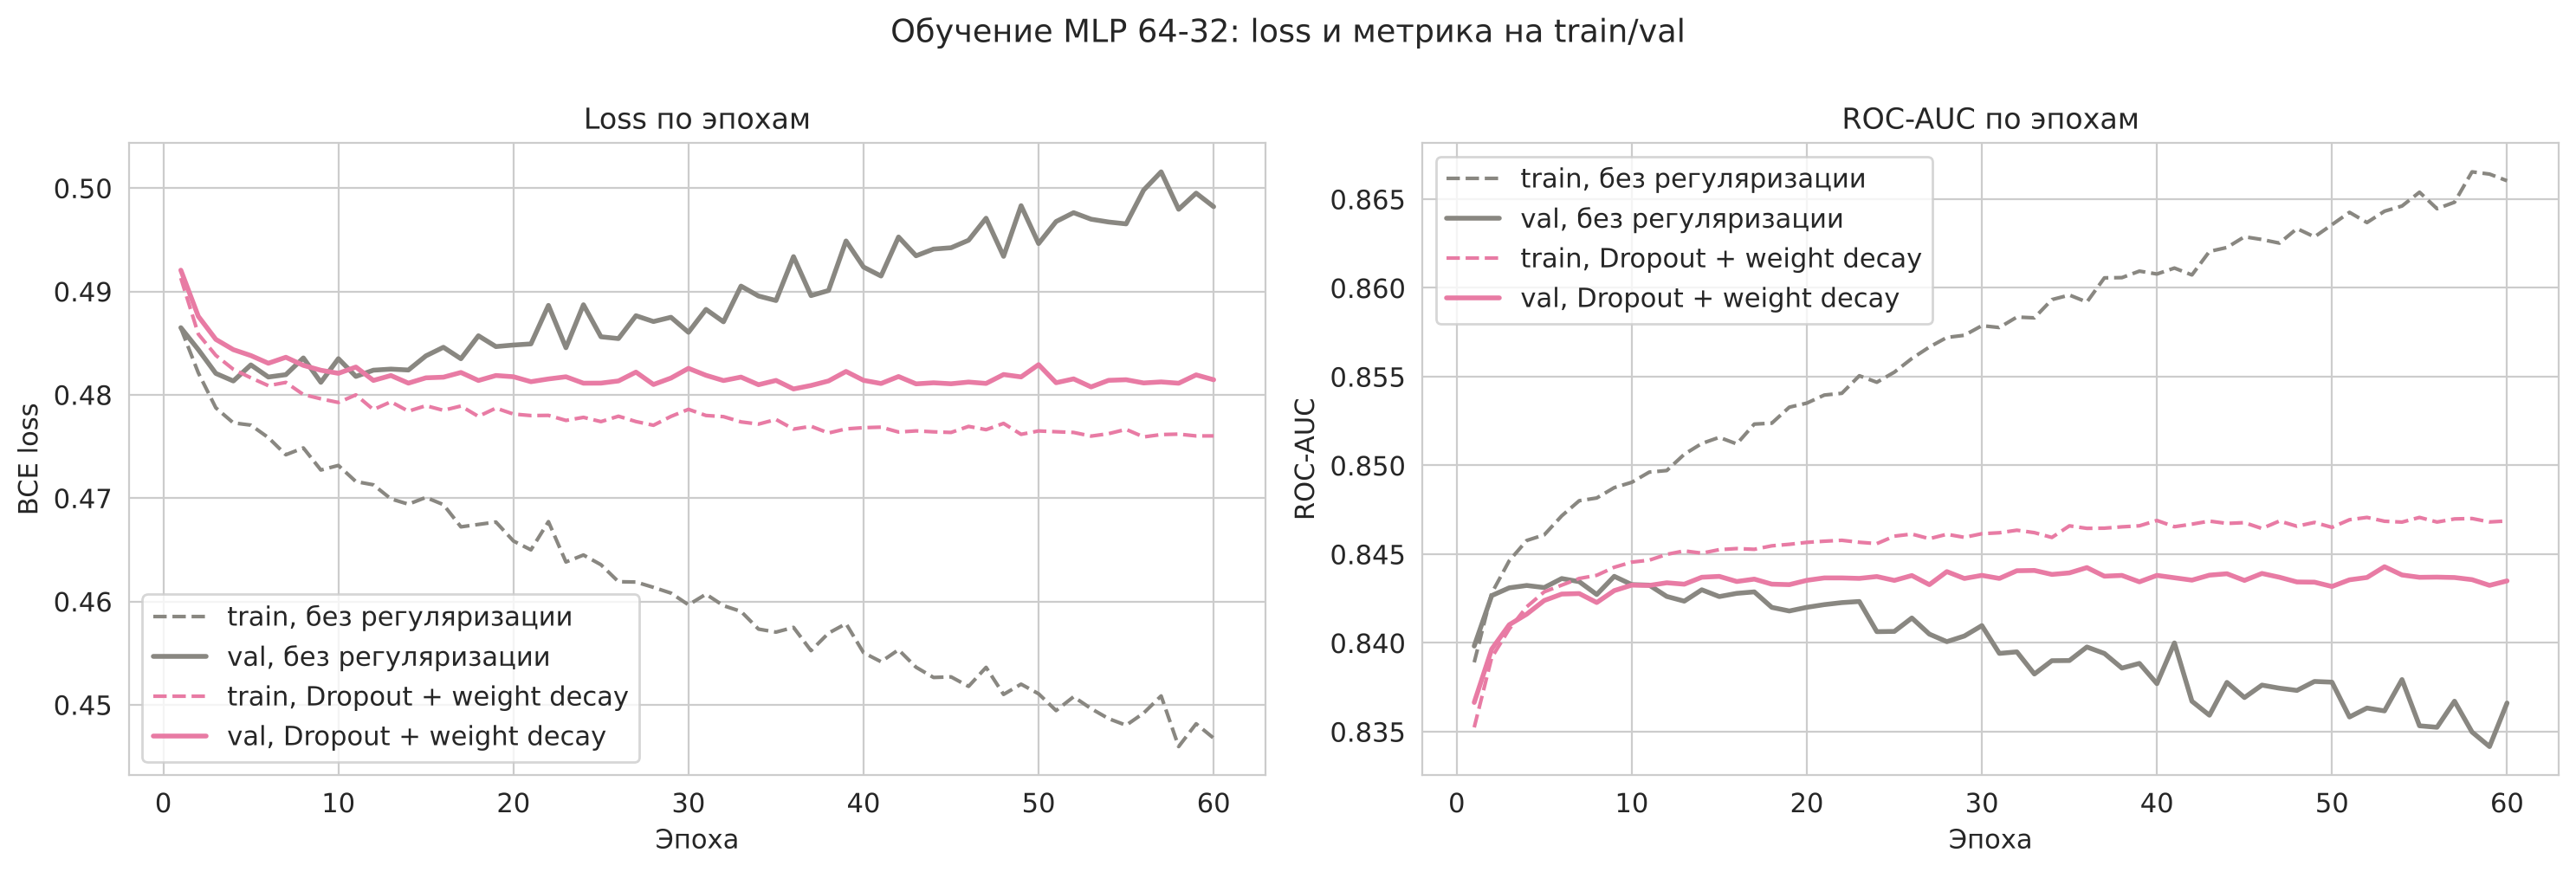

Без регуляризации: лучшая эпоха 9 (val loss 0.4812, val ROC-AUC 0.8438); на последней эпохе train loss 0.4468, val loss 0.4982, val ROC-AUC 0.8366
С регуляризацией: лучшая эпоха 36 (val loss 0.4806, val ROC-AUC 0.8442); на последней эпохе train loss 0.4760, val loss 0.4815, val ROC-AUC 0.8435


In [38]:
MLP_HIDDEN = (64, 32)
MAX_EPOCHS = 60

model_noreg, hist_noreg = train_mlp(X_main_p, y_main, X_val_p, y_val, hidden=MLP_HIDDEN,
                                    dropout=0.0, weight_decay=0.0, epochs=MAX_EPOCHS)
model_reg, hist_reg = train_mlp(X_main_p, y_main, X_val_p, y_val, hidden=MLP_HIDDEN,
                                dropout=MLP_DROPOUT, weight_decay=MLP_WD, epochs=MAX_EPOCHS)

epochs_axis = range(1, MAX_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for hist, color, name in [(hist_noreg, C_GRAY, 'без регуляризации'), (hist_reg, MODEL_COLORS['MLP (PyTorch)'], 'Dropout + weight decay')]:
    axes[0].plot(epochs_axis, hist['train_loss'], color=color, linestyle='--', label=f'train, {name}')
    axes[0].plot(epochs_axis, hist['val_loss'], color=color, linewidth=2, label=f'val, {name}')
    axes[1].plot(epochs_axis, hist['train_auc'], color=color, linestyle='--', label=f'train, {name}')
    axes[1].plot(epochs_axis, hist['val_auc'], color=color, linewidth=2, label=f'val, {name}')
axes[0].set_title('Loss по эпохам')
axes[0].set_ylabel('BCE loss')
axes[1].set_title('ROC-AUC по эпохам')
axes[1].set_ylabel('ROC-AUC')
for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.legend()
plt.suptitle('Обучение MLP 64-32: loss и метрика на train/val', y=1.0)
plt.tight_layout()
plt.savefig('figures/mlp_curves.png', dpi=150, bbox_inches='tight')
plt.show()

for title, hist in [('Без регуляризации', hist_noreg), ('С регуляризацией', hist_reg)]:
    best = int(np.argmin(hist['val_loss']))
    print(f"{title}: лучшая эпоха {best + 1} (val loss {hist['val_loss'][best]:.4f}, val ROC-AUC {hist['val_auc'][best]:.4f}); "
          f"на последней эпохе train loss {hist['train_loss'][-1]:.4f}, val loss {hist['val_loss'][-1]:.4f}, "
          f"val ROC-AUC {hist['val_auc'][-1]:.4f}")

### 6.3 Финальная MLP

Число эпох берём по минимуму val loss для модели с регуляризацией. Затем:

1. считаем 5-fold кросс-валидацию по матчам с этими настройками (те же фолды, что у классических моделей), заодно сохраняем out-of-fold предсказания для стекинга;
2. обучаем сеть на всём train и оцениваем на test.

In [39]:
MLP_EPOCHS = int(np.argmin(hist_reg['val_loss'])) + 1
print('Число эпох для финальной модели:', MLP_EPOCHS)

# 5-fold CV по матчам; предобработка обучается внутри каждого фолда
oof_mlp = np.zeros(len(X_train))
mlp_fold_scores = []
for tr_idx, val_idx in cv_splits:
    prep_fold = make_prep()
    X_tr_p = prep_fold.fit_transform(X_train.iloc[tr_idx])
    X_va_p = prep_fold.transform(X_train.iloc[val_idx])
    model_fold, _ = train_mlp(X_tr_p, y_train.iloc[tr_idx], hidden=MLP_HIDDEN, dropout=MLP_DROPOUT,
                              weight_decay=MLP_WD, epochs=MLP_EPOCHS)
    oof_mlp[val_idx] = mlp_proba(model_fold, X_va_p)
    mlp_fold_scores.append(roc_auc_score(y_train.iloc[val_idx], oof_mlp[val_idx]))
mlp_cv_mean, mlp_cv_std = np.mean(mlp_fold_scores), np.std(mlp_fold_scores)
print(f'MLP: CV ROC-AUC {mlp_cv_mean:.4f} ± {mlp_cv_std:.4f}')

# Финальная модель на всём train
prep_final = make_prep()
X_train_p = prep_final.fit_transform(X_train)
X_test_p = prep_final.transform(X_test)
t0 = time.time()
mlp_final, _ = train_mlp(X_train_p, y_train, hidden=MLP_HIDDEN, dropout=MLP_DROPOUT, weight_decay=MLP_WD, epochs=MLP_EPOCHS)
mlp_fit_time = time.time() - t0
proba_mlp_test = mlp_proba(mlp_final, X_test_p)
print(f'MLP: test ROC-AUC {roc_auc_score(y_test, proba_mlp_test):.4f}, время обучения {mlp_fit_time:.1f} с')

Число эпох для финальной модели: 36


MLP: CV ROC-AUC 0.8421 ± 0.0031


MLP: test ROC-AUC 0.8314, время обучения 7.6 с


**Итоги по MLP.**

- **Без регуляризации сеть переобучается.** Loss на обучении падает все 60 эпох (до 0,447), а на валидации после 9-й эпохи растёт с 0,4812 до 0,4982.
- **С Dropout 0,5 и weight decay 1e-3 переобучения нет:** val loss держится около 0,481 (минимум 0,4806 на 36-й эпохе), кривые train и val идут рядом. Для финальной модели берём 36 эпох.
- **Качество:** CV ROC-AUC 0,8421 ± 0,0031, test ROC-AUC 0,8314. Это уровень логистической регрессии: нейросеть не нашла в данных ничего сверх линейной модели.

## 7. Stacking и Blending

**Stacking.** Базовые модели: логистическая регрессия, Random Forest, градиентный бустинг и MLP. Для каждой считаем out-of-fold предсказания на train (модель предсказывает фолд, на котором не обучалась), и на них обучаем мета-модель — логистическую регрессию. Дерево решений в ансамбль не берём: оно заметно слабее остальных.

**Blending.** Взвешенное среднее вероятностей тех же моделей. Веса подбираем перебором на отложенной части train (те же 20% матчей, что служили валидацией для MLP).

In [40]:
best_pipes = {'Logistic Regression': grid_lr.best_estimator_, 'Decision Tree': grid_dt.best_estimator_,
              'Random Forest': rand_rf.best_estimator_, 'Gradient Boosting': rand_gb.best_estimator_}

# Out-of-fold предсказания базовых моделей (фолды по матчам)
oof = pd.DataFrame({name: cross_val_predict(best_pipes[name], X_train, y_train, cv=cv_splits, method='predict_proba')[:, 1]
                    for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting']})
oof['MLP (PyTorch)'] = oof_mlp

# Предсказания на test: модели обучены на всём train; заодно замеряем время одного обучения
proba_test = {}
fit_times = {}
for name, pipe in best_pipes.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    proba_test[name] = pipe.predict_proba(X_test)[:, 1]
proba_test['MLP (PyTorch)'] = proba_mlp_test
fit_times['MLP (PyTorch)'] = mlp_fit_time

base_names = list(oof.columns)
test_meta = pd.DataFrame({name: proba_test[name] for name in base_names})

print('Корреляция out-of-fold предсказаний базовых моделей:')
oof.corr().round(3)

Корреляция out-of-fold предсказаний базовых моделей:


,Logistic Regression,Random Forest,Gradient Boosting,MLP (PyTorch)
Logistic Regression,1.000,0.989,0.996,0.994
Random Forest,0.989,1.000,0.992,0.988
Gradient Boosting,0.996,0.992,1.000,0.993
MLP (PyTorch),0.994,0.988,0.993,1.000


In [41]:
# --- Stacking: мета-модель на out-of-fold предсказаниях ---
meta_model = LogisticRegression(max_iter=1000)
stack_scores = cross_val_score(meta_model, oof, y_train, cv=cv_splits, scoring='roc_auc')
stack_cv_mean, stack_cv_std = stack_scores.mean(), stack_scores.std()

t0 = time.time()
meta_model.fit(oof, y_train)
proba_test['Stacking'] = meta_model.predict_proba(test_meta)[:, 1]
fit_times['Stacking'] = sum(fit_times[name] for name in base_names) * 6 + (time.time() - t0)   # 5 фолдов + обучение на всём train

print(f'Stacking: CV ROC-AUC {stack_cv_mean:.4f} ± {stack_cv_std:.4f}, test ROC-AUC {roc_auc_score(y_test, proba_test["Stacking"]):.4f}')
print('Коэффициенты мета-модели:')
print(pd.Series(meta_model.coef_[0], index=base_names).round(2).to_string())

Stacking: CV ROC-AUC 0.8426 ± 0.0035, test ROC-AUC 0.8317
Коэффициенты мета-модели:
Logistic Regression    0.66
Random Forest          1.49
Gradient Boosting      0.58
MLP (PyTorch)          2.81


In [42]:
# --- Blending: веса подбираем на отложенной части train ---
blend_val = {}
for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting']:
    model = clone(best_pipes[name]).fit(X_main, y_main)
    blend_val[name] = model.predict_proba(X_val)[:, 1]
mlp_main, _ = train_mlp(X_main_p, y_main, hidden=MLP_HIDDEN, dropout=MLP_DROPOUT, weight_decay=MLP_WD, epochs=MLP_EPOCHS)
blend_val['MLP (PyTorch)'] = mlp_proba(mlp_main, X_val_p)

# Перебор весов с шагом 0.1, сумма весов равна 1
best_weights, best_score = None, -1
steps = np.arange(0, 1.01, 0.1)
for w1 in steps:
    for w2 in steps:
        for w3 in steps:
            w4 = 1 - w1 - w2 - w3
            if w4 < -1e-9:
                continue
            weights = [w1, w2, w3, max(w4, 0)]
            blend = sum(w * blend_val[name] for w, name in zip(weights, base_names))
            score = roc_auc_score(y_val, blend)
            if score > best_score:
                best_weights, best_score = weights, score

print('Лучшие веса:', {name: round(float(w), 1) for name, w in zip(base_names, best_weights)})
print(f'ROC-AUC на отложенной части: blending {best_score:.4f}; по отдельности:',
      {name: round(roc_auc_score(y_val, blend_val[name]), 4) for name in base_names})

proba_test['Blending'] = sum(w * proba_test[name] for w, name in zip(best_weights, base_names))
fit_times['Blending'] = sum(fit_times[name] for name in base_names) * 2
print(f'Blending: test ROC-AUC {roc_auc_score(y_test, proba_test["Blending"]):.4f}')

Лучшие веса: {'Logistic Regression': 0.1, 'Random Forest': 0.1, 'Gradient Boosting': 0.3, 'MLP (PyTorch)': 0.5}
ROC-AUC на отложенной части: blending 0.8448; по отдельности: {'Logistic Regression': 0.844, 'Random Forest': 0.8422, 'Gradient Boosting': 0.8441, 'MLP (PyTorch)': 0.8442}
Blending: test ROC-AUC 0.8317


**Итоги по ансамблям.**

- **Базовые модели ошибаются на одних и тех же объектах:** корреляция их предсказаний от 0,988 до 0,996. Ансамбль выигрывает, когда модели ошибаются по-разному; здесь объединять почти нечего.
- **Stacking:** CV ROC-AUC 0,8426 ± 0,0035, test 0,8317 (у логистической регрессии 0,8421 и 0,8321). Оценка стекинга на кросс-валидации слегка завышена: мета-модель проверяется на тех же out-of-fold предсказаниях, на которых обучается. Log-loss у стекинга хуже (0,5031 против 0,4934).
- **Blending:** лучшие веса — MLP 0,5, бустинг 0,3, логистическая регрессия и лес по 0,1; test 0,8317. Оценки на кросс-валидации у блендинга нет: веса подбирались на одной отложенной части.
- **Вывод:** ансамбли здесь не оправдывают себя.

## 8. Сравнение моделей

Все модели оцениваются на одной и той же тестовой выборке (20% матчей, все минуты) одними и теми же метриками. Порог для accuracy и F1 — 0,5.

In [43]:
# Baseline на test: логистическая регрессия на одном признаке
t0 = time.time()
pipe_gold.fit(X_train, y_train)
fit_times['Baseline: только золото'] = time.time() - t0
proba_test['Baseline: только золото'] = pipe_gold.predict_proba(X_test)[:, 1]

cv_scores = {'Baseline: только золото': (baseline_cv_mean, baseline_cv_std),
             'MLP (PyTorch)': (mlp_cv_mean, mlp_cv_std), 'Stacking': (stack_cv_mean, stack_cv_std),
             'Blending': (np.nan, np.nan)}
for name, search in searches.items():
    cv_scores[name] = (search.cv_results_['mean_test_score'][search.best_index_],
                       search.cv_results_['std_test_score'][search.best_index_])

order = ['Baseline: только золото', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'MLP (PyTorch)',
         'Logistic Regression', 'Stacking', 'Blending']
comp_rows = []
for name in order:
    p = proba_test[name]
    pred = (p >= 0.5).astype(int)
    comp_rows.append({'Модель': name, 'CV ROC-AUC': cv_scores[name][0], 'CV std': cv_scores[name][1],
                      'Test ROC-AUC': roc_auc_score(y_test, p), 'Accuracy': accuracy_score(y_test, pred),
                      'F1': f1_score(y_test, pred), 'Log-loss': log_loss(y_test, p),
                      'Время обучения, с': fit_times[name]})
comparison = pd.DataFrame(comp_rows).set_index('Модель')
comparison.to_csv('results/comparison.csv')

gold_rule_test = (test['gold_diff'] > 0).astype(int)
print(f'Для сравнения, правило «у кого больше золота» на test: accuracy {accuracy_score(y_test, gold_rule_test):.4f}; '
      f'всегда синие: accuracy {y_test.mean():.4f}')
comparison.round(4)

Для сравнения, правило «у кого больше золота» на test: accuracy 0.7364; всегда синие: accuracy 0.5408


,CV ROC-AUC,CV std,Test ROC-AUC,Accuracy,F1,Log-loss,"Время обучения, с"
Модель,,,,,,,
Baseline: только золото,0.8329,0.0044,0.8224,0.7396,0.7598,0.5081,0.0168
Decision Tree,0.8370,0.0031,0.8273,0.7378,0.7564,0.5058,0.1812
Random Forest,0.8411,0.0043,0.8288,0.7404,0.7636,0.4987,3.9574
Gradient Boosting,0.8417,0.0035,0.8307,0.7421,0.7646,0.4954,0.5725
MLP (PyTorch),0.8421,0.0031,0.8314,0.7426,0.7651,0.4949,7.6441
Logistic Regression,0.8421,0.0030,0.8321,0.7425,0.7653,0.4934,0.1747
Stacking,0.8426,0.0035,0.8317,0.7397,0.7606,0.5031,74.1222
Blending,NaN,NaN,0.8317,0.7413,0.7641,0.4939,24.6975


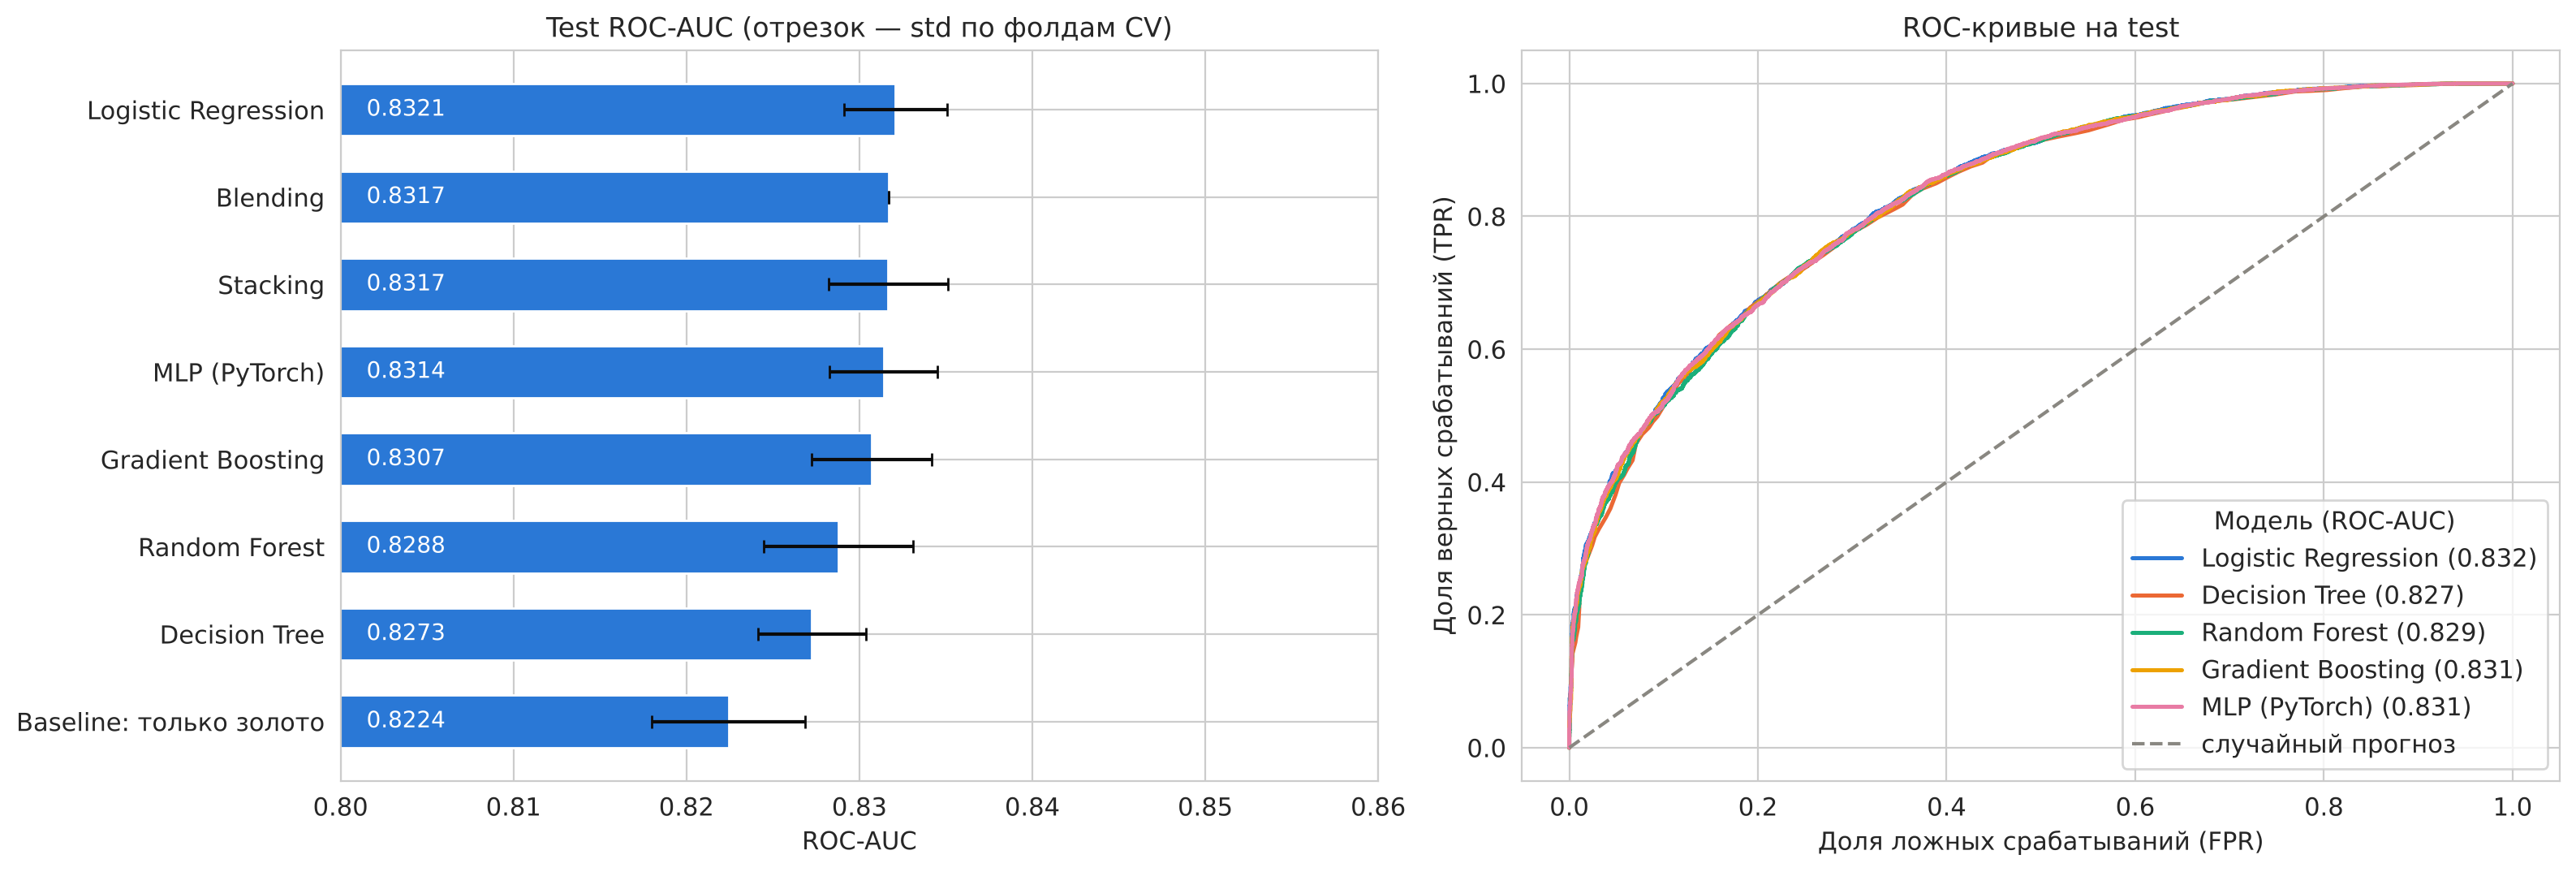

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Слева: test ROC-AUC всех моделей; отрезок — разброс по фолдам кросс-валидации
plot_data = comparison.sort_values('Test ROC-AUC')
axes[0].barh(plot_data.index, plot_data['Test ROC-AUC'], color=C_BLUE, height=0.6)
axes[0].errorbar(plot_data['Test ROC-AUC'], range(len(plot_data)), xerr=plot_data['CV std'].fillna(0),
                 fmt='none', ecolor='#0b0b0b', capsize=3)
for i, value in enumerate(plot_data['Test ROC-AUC']):
    axes[0].text(0.8015, i, f'{value:.4f}', va='center', color='white', fontsize=10)
axes[0].set_xlim(0.80, 0.86)
axes[0].set_title('Test ROC-AUC (отрезок — std по фолдам CV)')
axes[0].set_xlabel('ROC-AUC')

# Справа: ROC-кривые одиночных моделей
for name, color in MODEL_COLORS.items():
    fpr, tpr, _ = roc_curve(y_test, proba_test[name])
    axes[1].plot(fpr, tpr, color=color, linewidth=1.8, label=f'{name} ({roc_auc_score(y_test, proba_test[name]):.3f})')
axes[1].plot([0, 1], [0, 1], color=C_GRAY, linestyle='--', label='случайный прогноз')
axes[1].set_title('ROC-кривые на test')
axes[1].set_xlabel('Доля ложных срабатываний (FPR)')
axes[1].set_ylabel('Доля верных срабатываний (TPR)')
axes[1].legend(title='Модель (ROC-AUC)', loc='lower right')
plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Почему на test все модели ниже, чем на кросс-валидации.** Разница около 0,010 одинакова у всех моделей, включая baseline на одном признаке, которому нечем переобучиться. Значит, дело в самой тестовой выборке. Проверим, насколько ROC-AUC одного признака `gold_diff_rel` меняется между случайными наборами из 20% матчей.

In [45]:
rng = np.random.RandomState(RANDOM_STATE)
all_ids = matches['match_id'].values
subset_auc = []
for _ in range(300):
    ids_part = rng.choice(all_ids, size=len(test_ids), replace=False)
    part = snap[snap['match_id'].isin(ids_part)]
    subset_auc.append(roc_auc_score(part[target], part['gold_diff_rel']))
subset_auc = np.array(subset_auc)
test_gold_auc = roc_auc_score(y_test, test['gold_diff_rel'])

print(f'ROC-AUC признака gold_diff_rel на 300 случайных наборах из {len(test_ids)} матчей: '
      f'среднее {subset_auc.mean():.4f}, std {subset_auc.std():.4f}, '
      f'от {np.quantile(subset_auc, 0.05):.4f} до {np.quantile(subset_auc, 0.95):.4f} (5-й и 95-й перцентили)')
print(f'На нашей тестовой выборке: {test_gold_auc:.4f}; доля случайных наборов с таким же или более низким значением: '
      f'{(subset_auc <= test_gold_auc).mean():.0%}')

ROC-AUC признака gold_diff_rel на 300 случайных наборах из 1524 матчей: среднее 0.8306, std 0.0071, от 0.8197 до 0.8434 (5-й и 95-й перцентили)
На нашей тестовой выборке: 0.8224; доля случайных наборов с таким же или более низким значением: 11%


**Что показывает проверка.** ROC-AUC одного и того же признака на случайных 20% матчей меняется со стандартным отклонением 0,007. Наша тестовая выборка (0,8224) оказалась ниже среднего (0,8306), но в обычных пределах: у 11% случайных наборов значение такое же или ниже. Разрыв между CV и test объясняется тем, какие матчи попали в тест, а не переобучением. Модели между собой сравниваем по кросс-валидации.

**Выводы по сравнению моделей.**

1. **Сильные модели неразличимы.** Логистическая регрессия, MLP, бустинг и стекинг дают CV ROC-AUC 0,8417–0,8426 при std по фолдам 0,003–0,004; на test они и блендинг дают 0,8307–0,8321. Случайный лес чуть ниже (0,8411 на CV), дерево отстаёт заметнее (0,8370).
2. **Почему простая модель не хуже сложных.** Зависимость шанса победы от перевеса монотонная (раздел 3.5), остальные признаки добавляют небольшие поправки. На то, что сложные взаимодействия здесь не нужны, указывают три факта: бустинг выбрал деревья глубины 2, четыре архитектуры MLP дали одинаковый результат, предсказания всех моделей коррелируют на 0,99.
3. **Почему дерево хуже.** Вероятно, потому что оно приближает плавную зависимость ступеньками, а лес усредняет много деревьев и сглаживает их. Отдельно это не проверялось.
4. **Выигрыш у точки отсчёта небольшой.** На кросс-валидации итоговая модель лучше модели на одном золоте на 0,009 (0,8421 против 0,8329), на test — на 0,010. По accuracy 74,3% против 73,6% у правила «у кого больше золота». Почти вся информация о победителе уже есть в перевесе по золоту.
5. **Итоговая модель — логистическая регрессия** (L1, `C = 0,01`). Выбор сделан по кросс-валидации и простоте: её CV ROC-AUC не ниже, чем у остальных одиночных моделей, она обучается за доли секунды, а прогноз раскладывается на вклады признаков. Test в выборе не участвовал и только подтверждает его: ROC-AUC 0,8321 и log-loss 0,4934 — лучшие среди всех моделей.

In [46]:
# Итоговая модель для разделов 9-12
FINAL_NAME = 'Logistic Regression'
final_model = best_pipes[FINAL_NAME]          # уже обучена на всём train
proba_final = proba_test[FINAL_NAME]
best_C = grid_lr.best_params_['model__C']
best_l1 = grid_lr.best_params_['model__l1_ratio']


def new_logreg():
    """Логистическая регрессия с подобранными гиперпараметрами (для экспериментов ниже)."""
    return LogisticRegression(solver='saga', max_iter=5000, C=best_C, l1_ratio=best_l1, random_state=RANDOM_STATE)

print('Итоговая модель:', FINAL_NAME, '| C =', best_C, '| l1_ratio =', best_l1)

Итоговая модель: Logistic Regression | C = 0.01 | l1_ratio = 1


## 9. Разные стадии матча

Модель одна на все минуты, поэтому на каждой стадии её можно оценить отдельно: берём строки теста с нужной минутой. Условно: 10-я минута — ранняя игра, 20-я — середина, 30-я — поздняя.

### 9.1 Качество итоговой модели по минутам

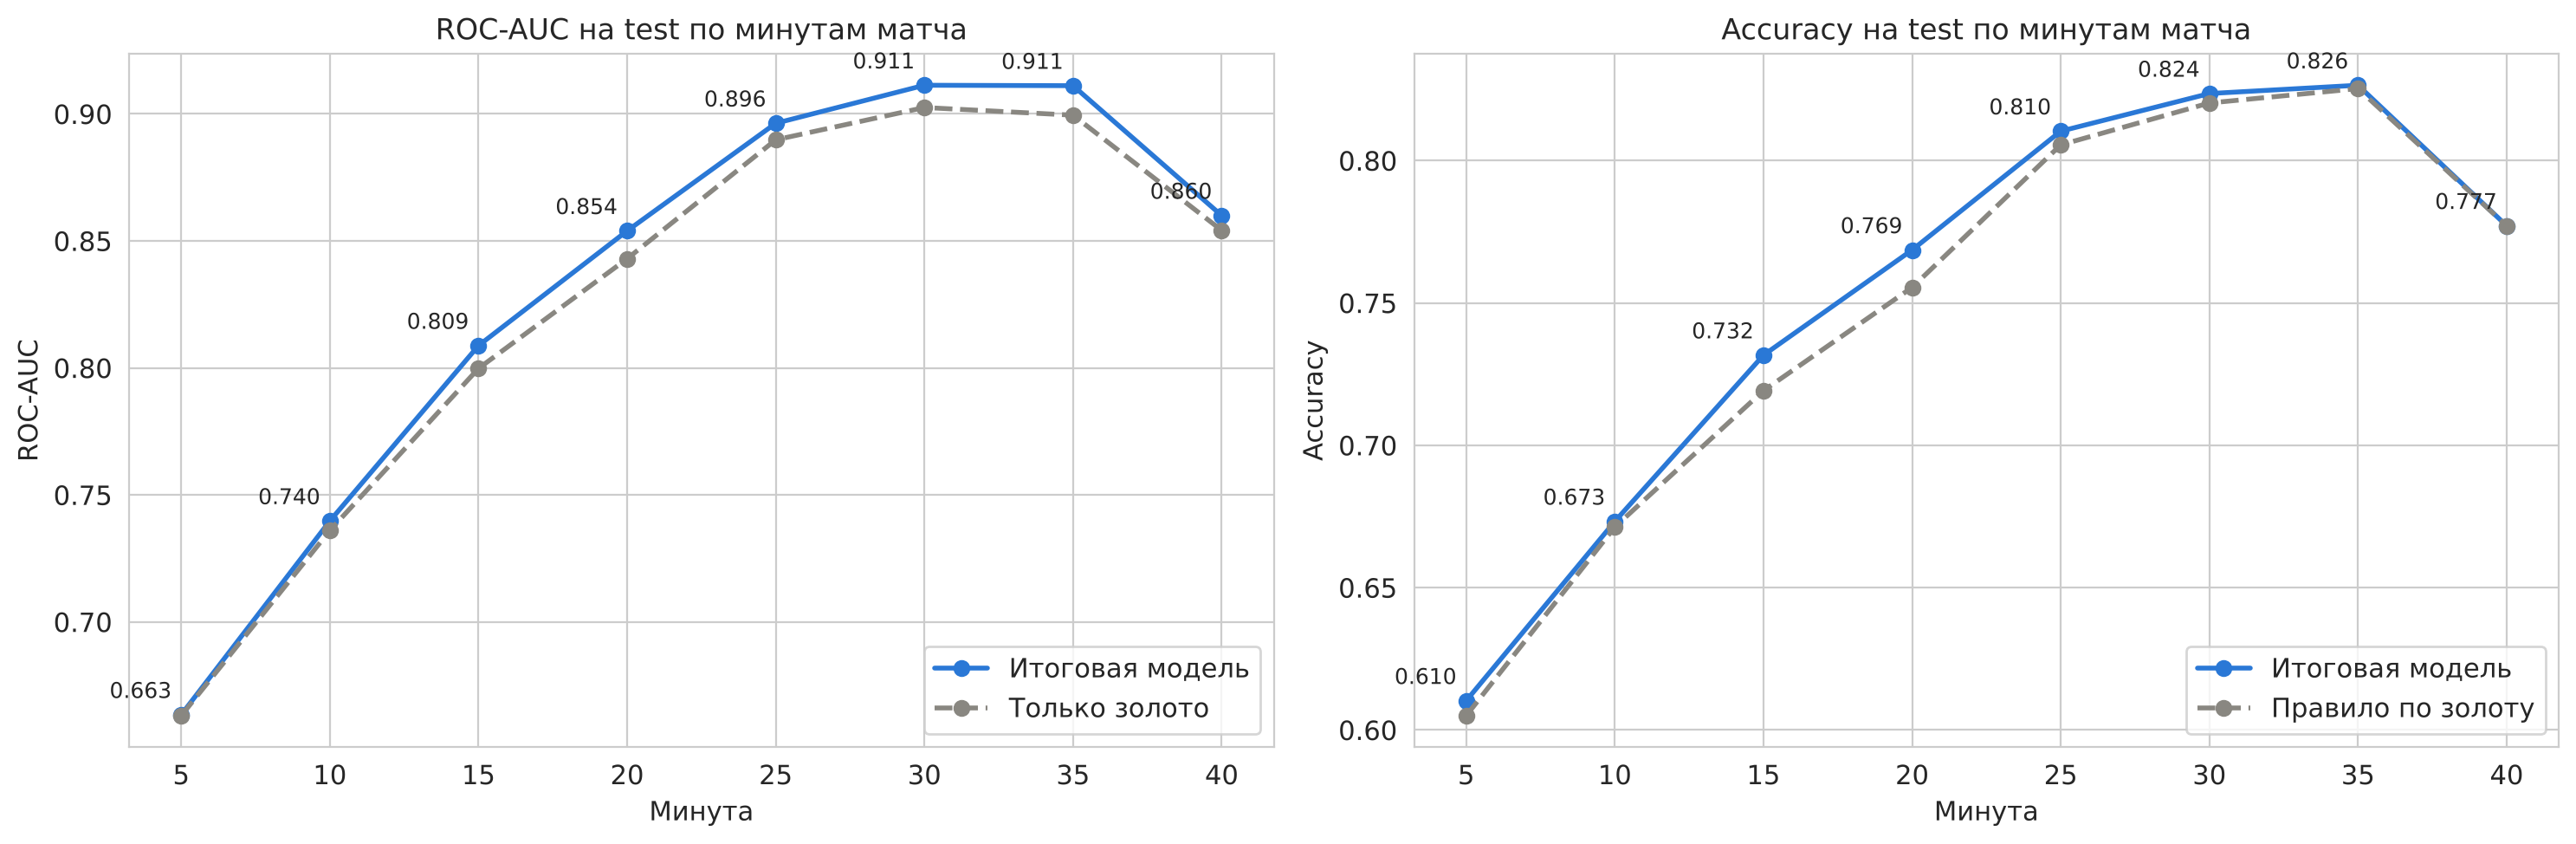

,Матчей в test,ROC-AUC: модель,ROC-AUC: только золото,Accuracy: модель,Accuracy: правило по золоту,Log-loss: модель
Минута,,,,,,
5,1524,0.6634,0.6630,0.6102,0.6050,0.6455
10,1524,0.7397,0.7360,0.6732,0.6713,0.5902
15,1524,0.8088,0.7998,0.7316,0.7192,0.5227
20,1521,0.8539,0.8430,0.7686,0.7554,0.4656
25,1455,0.8963,0.8898,0.8103,0.8055,0.4016
30,1207,0.9113,0.9025,0.8235,0.8202,0.3761
35,847,0.9111,0.8995,0.8264,0.8253,0.3777
40,480,0.8600,0.8541,0.7771,0.7771,0.4758


In [47]:
minute_rows = []
for T in MINUTES:
    mask = (test['minute'] == T).values
    y_T, p_T = y_test[mask], proba_final[mask]
    minute_rows.append({'Минута': T, 'Матчей в test': mask.sum(),
                        'ROC-AUC: модель': roc_auc_score(y_T, p_T),
                        'ROC-AUC: только золото': roc_auc_score(y_T, test.loc[mask, 'gold_diff_rel']),
                        'Accuracy: модель': accuracy_score(y_T, p_T >= 0.5),
                        'Accuracy: правило по золоту': accuracy_score(y_T, test.loc[mask, 'gold_diff'] > 0),
                        'Log-loss: модель': log_loss(y_T, p_T)})
by_minute = pd.DataFrame(minute_rows).set_index('Минута')
by_minute.to_csv('results/quality_by_minute.csv')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['ROC-AUC', 'Accuracy']):
    second = 'только золото' if metric == 'ROC-AUC' else 'правило по золоту'
    ax.plot(by_minute.index, by_minute[f'{metric}: модель'], marker='o', color=C_BLUE, linewidth=2, label='Итоговая модель')
    ax.plot(by_minute.index, by_minute[f'{metric}: {second}'], marker='o', color=C_GRAY, linewidth=2, linestyle='--',
            label=second.capitalize())
    for T, value in by_minute[f'{metric}: модель'].items():
        ax.annotate(f'{value:.3f}', (T, value), xytext=(-4, 7), textcoords='offset points', ha='right', fontsize=9)
    ax.set_title(f'{metric} на test по минутам матча')
    ax.set_xlabel('Минута')
    ax.set_ylabel(metric)
    ax.set_xticks(MINUTES)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/quality_by_minute.png', dpi=150, bbox_inches='tight')
plt.show()

by_minute.round(4)

### 9.2 Все модели на трёх стадиях

In [48]:
stage_rows = {}
for name in order:
    stage_rows[name] = {f'{T}-я минута': roc_auc_score(y_test[(test['minute'] == T).values],
                                                         proba_test[name][(test['minute'] == T).values]) for T in [10, 20, 30]}
stages = pd.DataFrame(stage_rows).T
stages.index.name = 'Модель'
stages.to_csv('results/stages.csv')
print('Test ROC-AUC по стадиям')
stages.round(4)

Test ROC-AUC по стадиям


,10-я минута,20-я минута,30-я минута
Модель,,,
Baseline: только золото,0.7360,0.8430,0.9025
Decision Tree,0.7377,0.8468,0.9039
Random Forest,0.7411,0.8487,0.9067
Gradient Boosting,0.7397,0.8522,0.9094
MLP (PyTorch),0.7422,0.8516,0.9093
Logistic Regression,0.7397,0.8539,0.9113
Stacking,0.7422,0.8519,0.9096
Blending,0.7419,0.8523,0.9099


### 9.3 Одна модель на все минуты или отдельная модель на каждую стадию?

Сравниваем на кросс-валидации (train, фолды по матчам): общая модель, оценённая на строках одной минуты, против модели с теми же гиперпараметрами, обученной только на этой минуте.

In [49]:
stage_num = [c for c in num_features if c != 'minute']
uni_rows = []
for T in [10, 20, 30]:
    # общая модель: out-of-fold предсказания, качество на строках минуты T в каждом фолде
    row = {'Минута': T}
    for name in ['Logistic Regression', 'Gradient Boosting']:
        fold_scores = []
        for _, val_idx in cv_splits:
            val_T = val_idx[train['minute'].values[val_idx] == T]
            fold_scores.append(roc_auc_score(y_train.iloc[val_T], oof[name].values[val_T]))
        row[f'{name}: общая модель'] = np.mean(fold_scores)

    # отдельная модель: обучаем только на строках минуты T
    part = train[train['minute'] == T].reset_index(drop=True)
    splits_T = list(cv.split(part, part[target], groups=part['match_id']))
    X_T, y_T = part[stage_num + cat_features], part[target]
    lr_mean, lr_std = cv_auc(make_pipe(new_logreg(), num=stage_num), X=X_T, y=y_T, splits=splits_T)
    row['Logistic Regression: отдельная модель'] = lr_mean
    gb_T = make_pipe(clone(rand_gb.best_estimator_['model']), num=stage_num)
    row['Gradient Boosting: отдельная модель'] = cv_auc(gb_T, X=X_T, y=y_T, splits=splits_T)[0]
    row['std по фолдам (LogReg, отдельная)'] = lr_std
    uni_rows.append(row)
universal_vs_stage = pd.DataFrame(uni_rows).set_index('Минута')
universal_vs_stage = universal_vs_stage[['Logistic Regression: общая модель', 'Logistic Regression: отдельная модель',
                                         'Gradient Boosting: общая модель', 'Gradient Boosting: отдельная модель',
                                         'std по фолдам (LogReg, отдельная)']]
universal_vs_stage.to_csv('results/universal_vs_stage.csv')
universal_vs_stage.round(4)

,Logistic Regression: общая модель,Logistic Regression: отдельная модель,Gradient Boosting: общая модель,Gradient Boosting: отдельная модель,"std по фолдам (LogReg, отдельная)"
Минута,,,,,
10,0.7456,0.7473,0.7450,0.7467,0.0123
20,0.8689,0.8686,0.8677,0.8665,0.0053
30,0.9267,0.9271,0.9265,0.9258,0.0072


**Выводы по стадиям.**

- **Чем дальше, тем точнее, но только до 30–35-й минуты.** Test ROC-AUC итоговой модели: 0,663 на 5-й минуте, 0,740 на 10-й, 0,854 на 20-й, 0,911 на 30-й и 35-й. Accuracy растёт с 61% до 83%.
- **После 35-й минуты качество падает** (0,860 на 40-й). До 40-й минуты доживает меньше трети матчей, и камбэков в них больше (раздел 12.4).
- **Больше всего модель выигрывает у правила по золоту в середине игры.** На 5–10-й минуте разницы почти нет (0,740 против 0,736 на 10-й), на 15–20-й минуте разрыв 0,009–0,011.
- **На каждой стадии модели близки.** Разброс между всеми моделями: 0,7377–0,7422 на 10-й минуте, 0,8468–0,8539 на 20-й, 0,9039–0,9113 на 30-й. Логистическая регрессия первая на 20-й и 30-й минутах, на 10-й — пятая из семи.
- **По ROC-AUC общая модель не уступает отдельным.** Отдельные модели для 10-й, 20-й и 30-й минуты с теми же гиперпараметрами дают 0,7473, 0,8686 и 0,9271 против 0,7456, 0,8689 и 0,9267 у общей. Если подобрать `C` для каждой стадии заново (раздел 10.2), на 10-й минуте отдельная модель доходит до 0,7529: это +0,007 при std по фолдам 0,012. Одной модели достаточно.

## 10. Важность признаков по стадиям

Смотрим четырьмя способами, потому что каждый отвечает на свой вопрос:

1. **Каждый признак по отдельности:** ROC-AUC одного признака на 10-й, 20-й и 30-й минуте. Отвечает на вопрос «что информативно само по себе».
2. **Коэффициенты логистической регрессии с L1**, обученной отдельно на каждой стадии. Отвечает на вопрос «что добавляет новое к остальным признакам»: L1 обнуляет то, что дублирует другие признаки.
3. **Permutation importance** итоговой модели на тесте: насколько падает ROC-AUC, если перемешать признак.
4. **SHAP** для градиентного бустинга: вклад каждого признака в каждый отдельный прогноз.

### 10.1 Каждый признак по отдельности

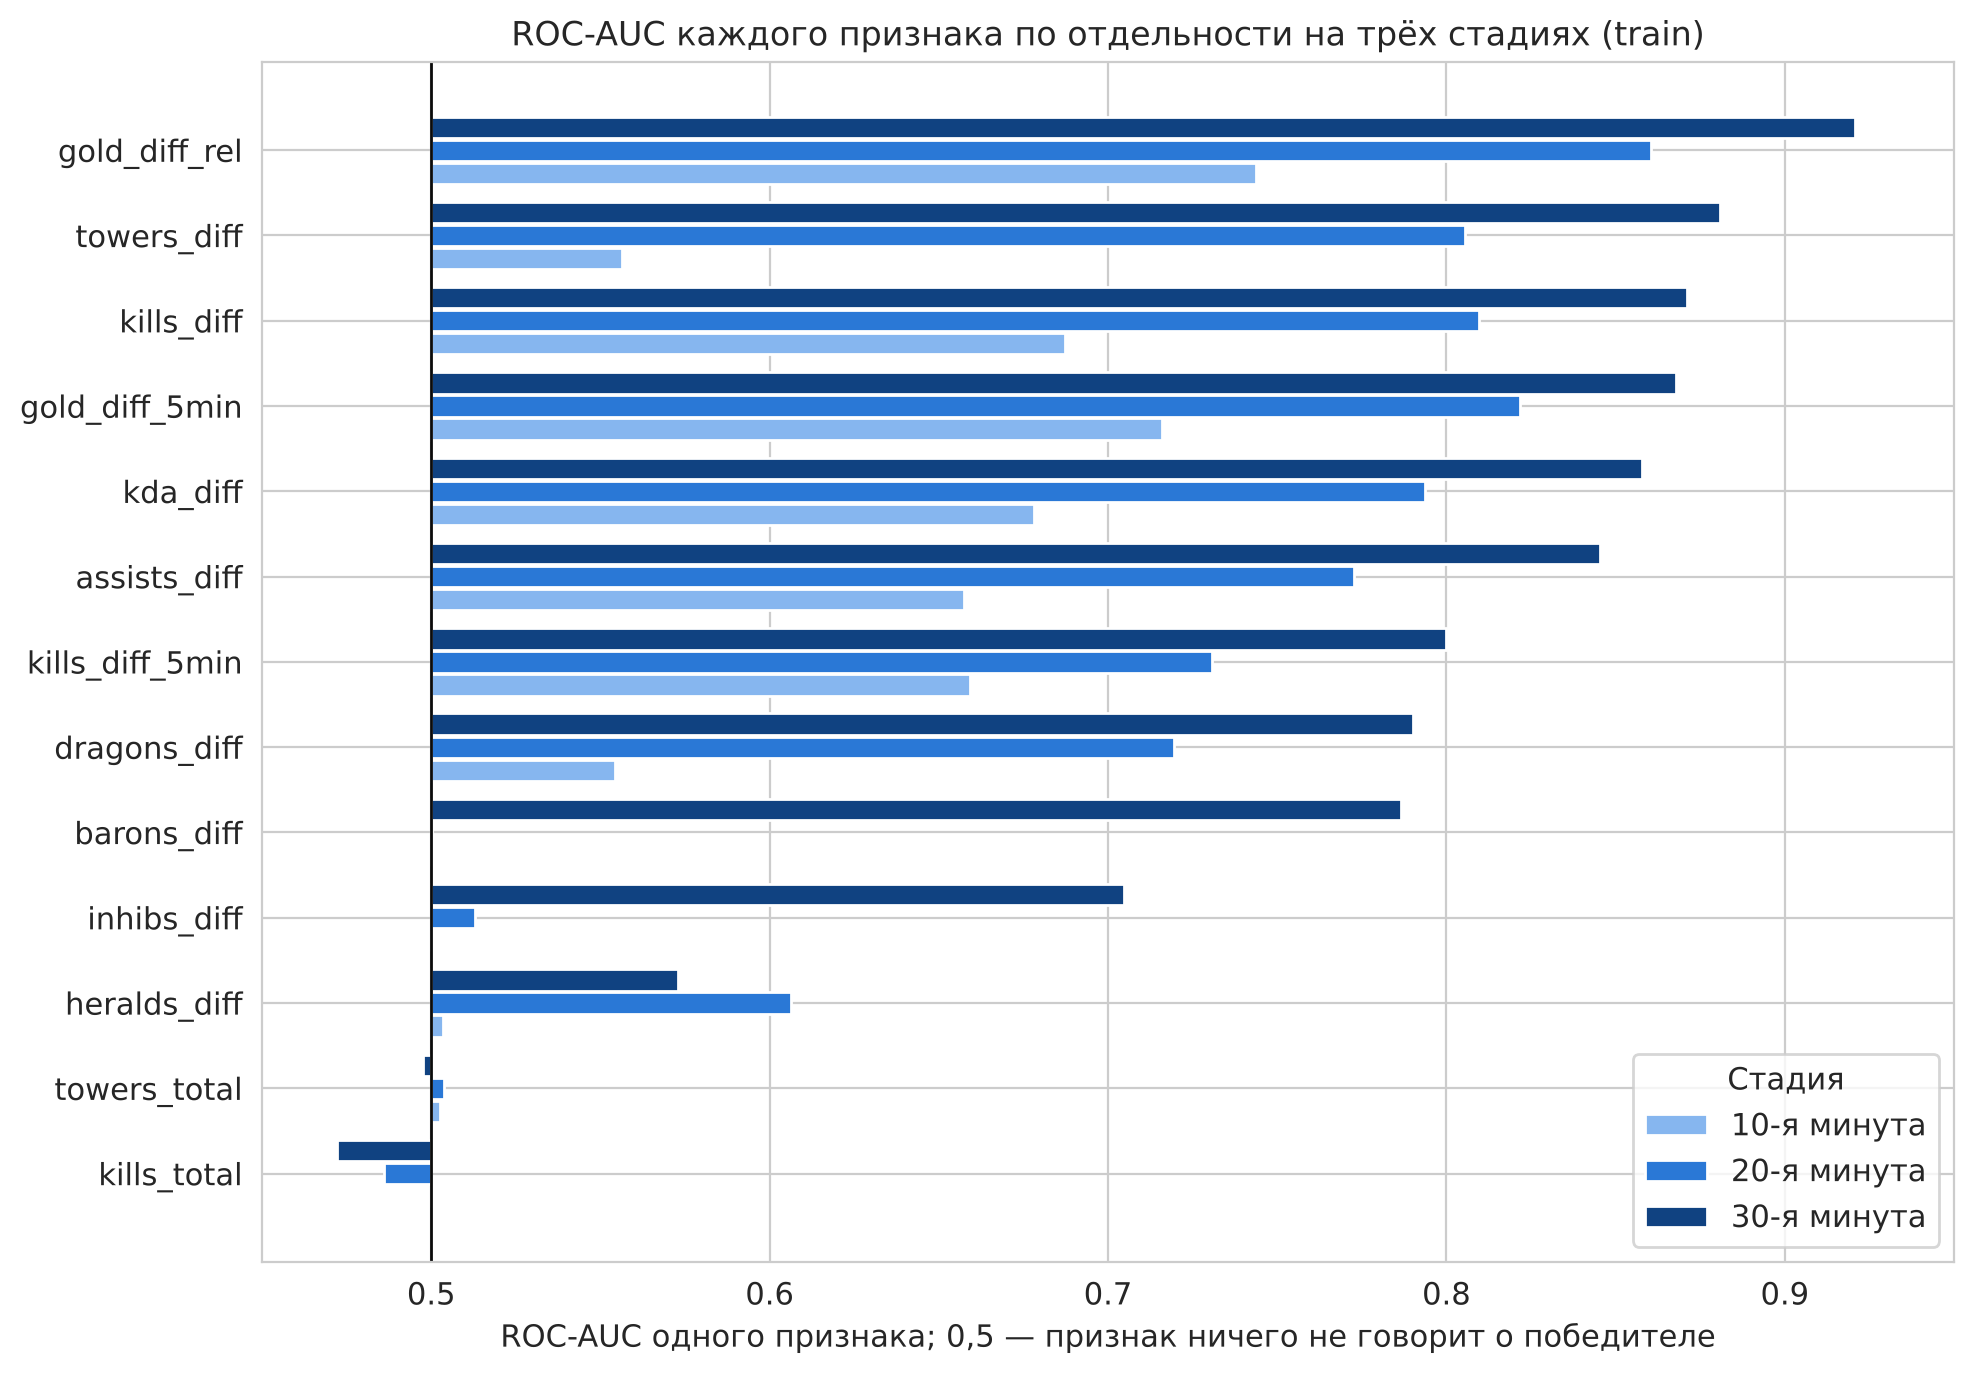

In [50]:
stage_cols = ['10-я минута', '20-я минута', '30-я минута']
single_plot = single_auc.drop(index='gold_diff')[stage_cols]
single_plot = single_plot.loc[single_plot.max(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 7))
positions = np.arange(len(single_plot))
for j, T in enumerate([10, 20, 30]):
    ax.barh(positions + (j - 1) * 0.27, single_plot[f'{T}-я минута'] - 0.5, left=0.5, height=0.25, color=C_MINUTES[T],
            label=f'{T}-я минута')
ax.set_yticks(positions)
ax.set_yticklabels(single_plot.index)
ax.axvline(0.5, color='#0b0b0b', linewidth=1)
ax.set_xlim(0.45, 0.95)
ax.set_title('ROC-AUC каждого признака по отдельности на трёх стадиях (train)')
ax.set_xlabel('ROC-AUC одного признака; 0,5 — признак ничего не говорит о победителе')
ax.legend(title='Стадия', loc='lower right')
plt.tight_layout()
plt.savefig('figures/single_feature_auc.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.2 Коэффициенты логистической регрессии по стадиям

Для моделей по стадиям силу регуляризации выбираем заново: строк на одной минуте в шесть с лишним раз меньше, чем в общей таблице. Сначала смотрим, как качество зависит от `C`.

In [51]:
def clean_names(names):
    return [n.replace('num__', '').replace('cat__', '') for n in names]


def stage_logreg(C):
    return make_pipe(LogisticRegression(solver='saga', max_iter=5000, C=C, l1_ratio=1, random_state=RANDOM_STATE), num=stage_num)


c_rows = []
for T in [10, 20, 30]:
    part = train[train['minute'] == T].reset_index(drop=True)
    splits_T = list(cv.split(part, part[target], groups=part['match_id']))
    for C in [0.003, 0.01, 0.03, 0.1, 1]:
        mean_auc, std_auc = cv_auc(stage_logreg(C), X=part[stage_num + cat_features], y=part[target], splits=splits_T)
        model_T = stage_logreg(C).fit(part[stage_num + cat_features], part[target])
        c_rows.append({'Минута': T, 'C': C, 'CV ROC-AUC': mean_auc, 'std': std_auc,
                       'Ненулевых коэффициентов': int((np.abs(model_T['model'].coef_[0]) > 1e-6).sum())})
c_table = pd.DataFrame(c_rows)
c_table.pivot(index='C', columns='Минута', values=['CV ROC-AUC', 'Ненулевых коэффициентов']).round(4)

CV ROC-AUC                 Ненулевых коэффициентов            
Минута         10      20      30                      10    20    30
C                                                                    
0.003      0.7437  0.8655  0.9223                     1.0   3.0   3.0
0.010      0.7473  0.8686  0.9271                     3.0   4.0   4.0
0.030      0.7505  0.8687  0.9275                     5.0   6.0   9.0
0.100      0.7529  0.8689  0.9276                     9.0  13.0  12.0
1.000      0.7525  0.8692  0.9272                    16.0  19.0  17.0

При `C` от 0,03 до 1 качество меняется не больше чем на 0,003 на любой стадии, а число ненулевых коэффициентов растёт с 5–9 до 16–19. При `C = 0,01` и ниже качество на 10-й минуте уже проседает (0,7473).

Берём **`C = 0,03`**: это самая простая модель из тех, что не теряют в качестве. В ней остаются только признаки с собственным вкладом, а дубли обнуляются.

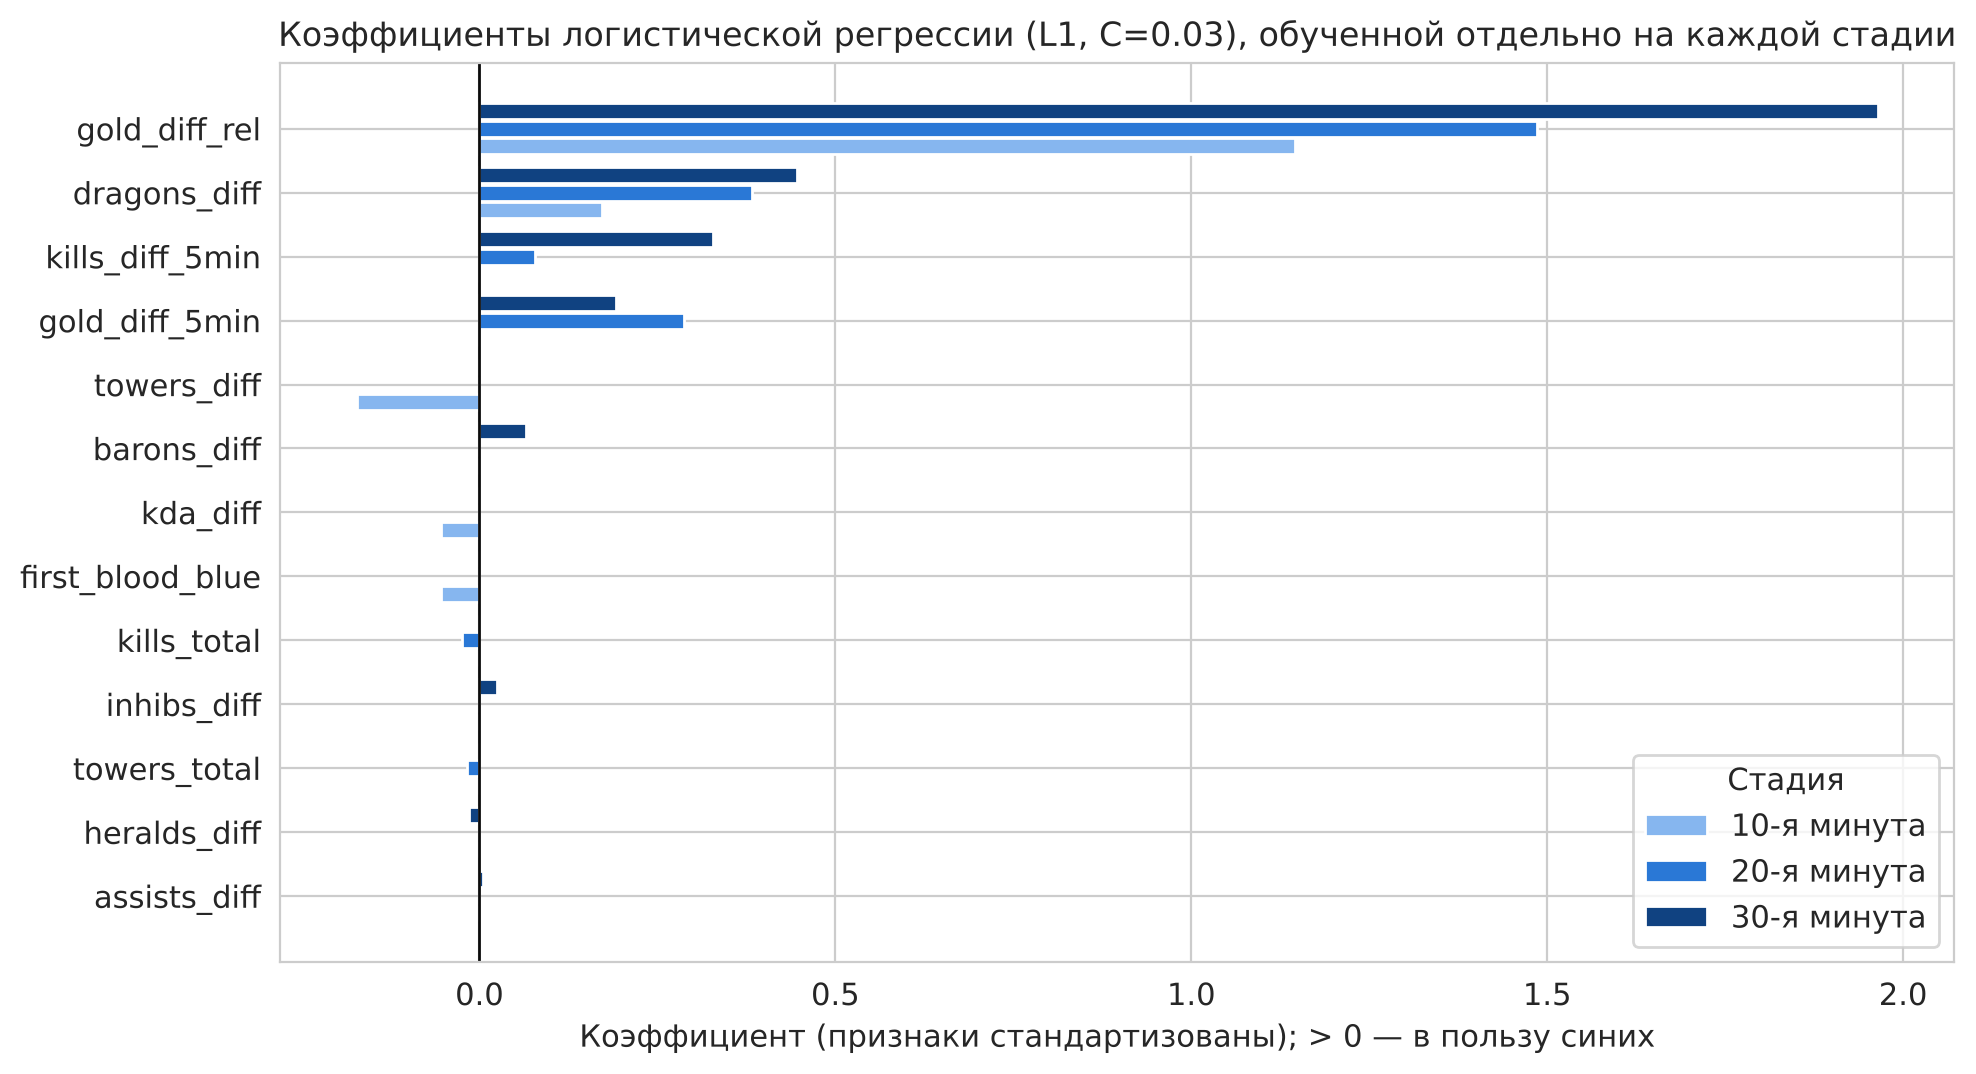

Признаки с ненулевым коэффициентом хотя бы на одной стадии (остальные обнулены):


,10-я минута,20-я минута,30-я минута
gold_diff_rel,1.146,1.485,1.965
dragons_diff,0.172,0.383,0.446
kills_diff_5min,0.000,0.078,0.329
gold_diff_5min,0.000,0.287,0.191
towers_diff,-0.173,0.000,0.000
barons_diff,0.000,0.000,0.066
kda_diff,-0.054,0.000,0.000
first_blood_blue,-0.054,0.000,0.000
kills_total,0.000,-0.024,-0.001
inhibs_diff,0.000,0.000,0.024


In [52]:
STAGE_C = 0.03
coef_by_stage = {}
for T in [10, 20, 30]:
    part = train[train['minute'] == T]
    model_T = stage_logreg(STAGE_C).fit(part[stage_num + cat_features], part[target])
    coef_by_stage[f'{T}-я минута'] = pd.Series(model_T['model'].coef_[0], index=clean_names(model_T['prep'].get_feature_names_out()))
coefs = pd.DataFrame(coef_by_stage).fillna(0)
coefs = coefs[(coefs.abs() > 1e-6).any(axis=1)]                 # оставляем признаки, которые не обнулились хотя бы на одной стадии
coefs = coefs.loc[coefs.abs().max(axis=1).sort_values().index]
coefs.to_csv('results/logreg_coefs_by_stage.csv')

fig, ax = plt.subplots(figsize=(10, 5.5))
positions = np.arange(len(coefs))
for j, T in enumerate([10, 20, 30]):
    ax.barh(positions + (j - 1) * 0.27, coefs[f'{T}-я минута'], height=0.25, color=C_MINUTES[T], label=f'{T}-я минута')
ax.set_yticks(positions)
ax.set_yticklabels(coefs.index)
ax.axvline(0, color='#0b0b0b', linewidth=1)
ax.set_title(f'Коэффициенты логистической регрессии (L1, C={STAGE_C}), обученной отдельно на каждой стадии')
ax.set_xlabel('Коэффициент (признаки стандартизованы); > 0 — в пользу синих')
ax.legend(title='Стадия', loc='lower right')
plt.tight_layout()
plt.savefig('figures/logreg_coefs_by_stage.png', dpi=150, bbox_inches='tight')
plt.show()

print('Признаки с ненулевым коэффициентом хотя бы на одной стадии (остальные обнулены):')
coefs.iloc[::-1].round(3)

### 10.3 Permutation importance итоговой модели по стадиям

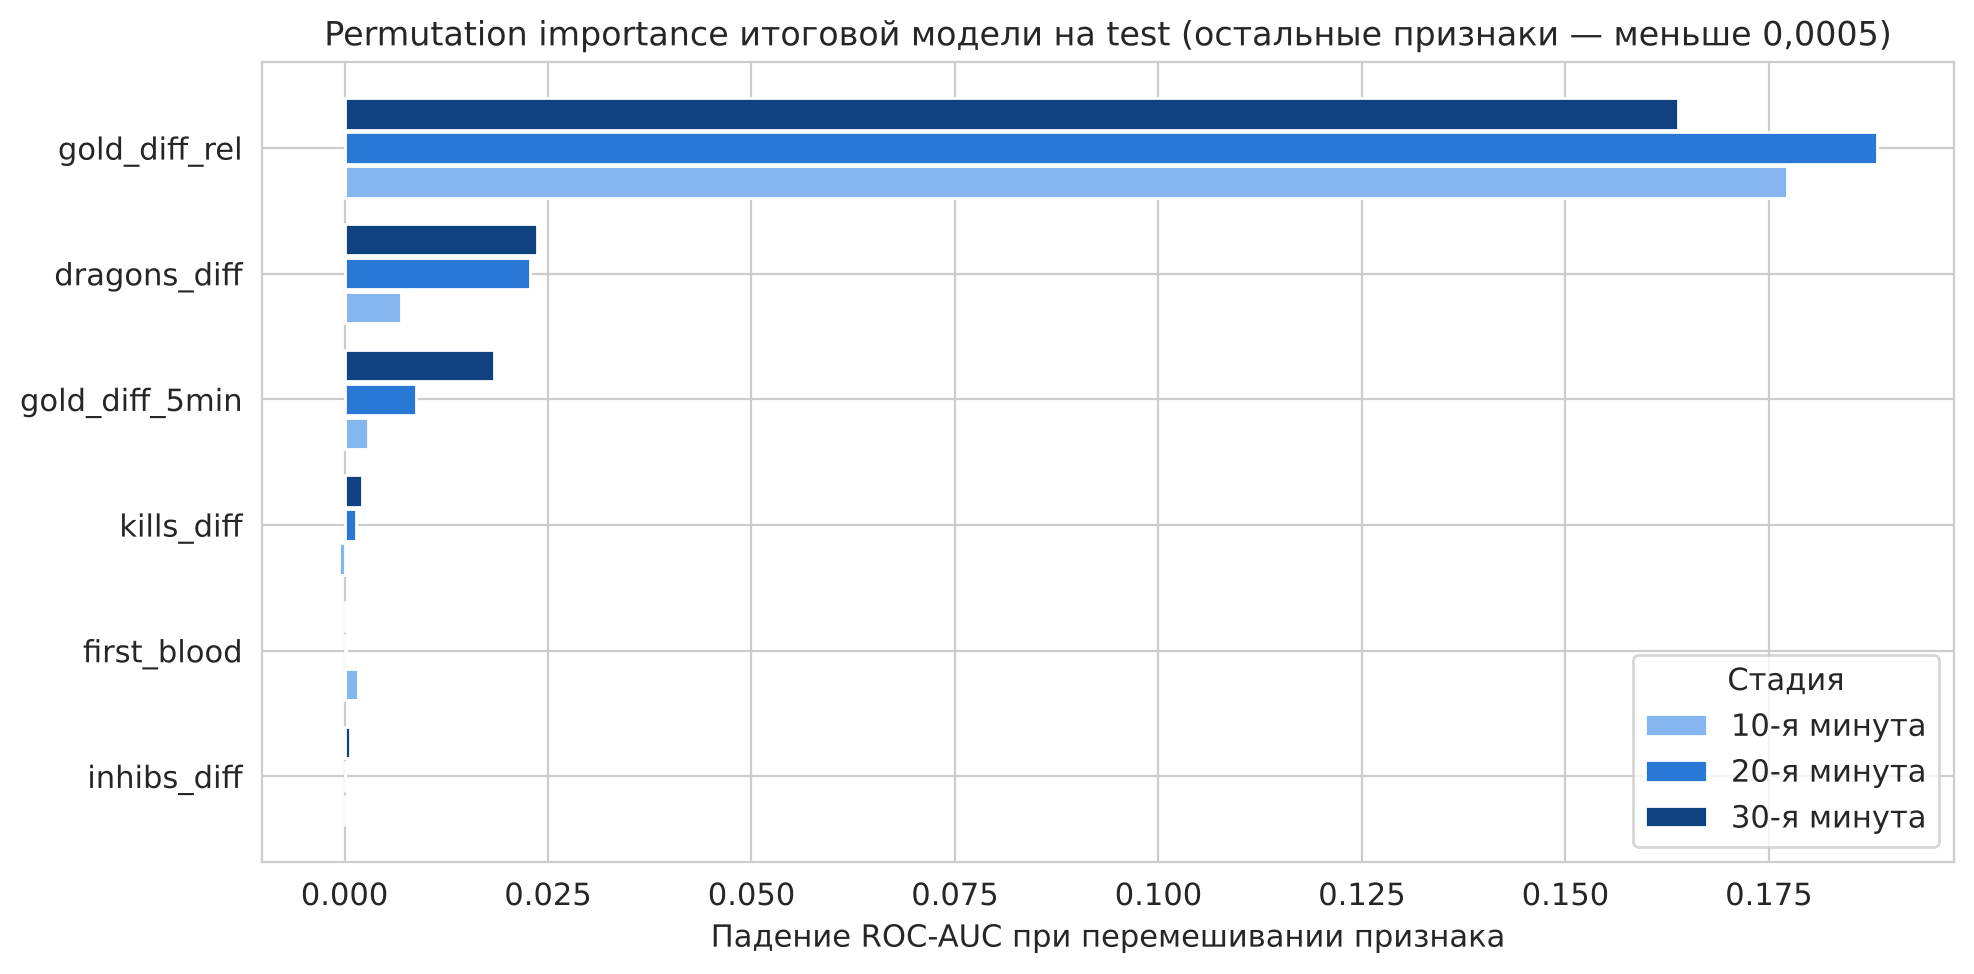

Признаков с важностью меньше 0,0005 на всех стадиях: 10 из 16


,10-я минута,20-я минута,30-я минута
gold_diff_rel,0.1773,0.1883,0.1638
dragons_diff,0.0070,0.0228,0.0237
gold_diff_5min,0.0029,0.0088,0.0184
kills_diff,-0.0007,0.0014,0.0022
first_blood,0.0016,0.0002,0.0001
inhibs_diff,0.0000,0.0001,0.0007
barons_diff,0.0000,-0.0000,0.0003
kills_total,0.0001,-0.0000,0.0000
towers_total,0.0000,0.0000,0.0000
first_dragon,0.0000,0.0000,0.0000


In [53]:
from sklearn.inspection import permutation_importance

perm_features = {}
for T in [10, 20, 30]:
    mask = (test['minute'] == T).values
    result = permutation_importance(final_model, X_test[mask], y_test[mask], n_repeats=10, random_state=RANDOM_STATE,
                                    scoring='roc_auc')
    perm_features[f'{T}-я минута'] = pd.Series(result.importances_mean, index=features)
perm_features = pd.DataFrame(perm_features).drop(index='minute')
perm_features = perm_features.loc[perm_features.max(axis=1).sort_values().index]
perm_features.to_csv('results/importance_features.csv')
perm_plot = perm_features[perm_features.abs().max(axis=1) >= 0.0005]      # на графике только признаки с заметной важностью

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(perm_plot))
for j, T in enumerate([10, 20, 30]):
    ax.barh(positions + (j - 1) * 0.27, perm_plot[f'{T}-я минута'], height=0.25, color=C_MINUTES[T], label=f'{T}-я минута')
ax.set_yticks(positions)
ax.set_yticklabels(perm_plot.index)
ax.set_title('Permutation importance итоговой модели на test (остальные признаки — меньше 0,0005)')
ax.set_xlabel('Падение ROC-AUC при перемешивании признака')
ax.legend(title='Стадия', loc='lower right')
plt.tight_layout()
plt.savefig('figures/permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Признаков с важностью меньше 0,0005 на всех стадиях:', len(perm_features) - len(perm_plot), 'из', len(perm_features))
perm_features.iloc[::-1].round(4)

### 10.4 SHAP для градиентного бустинга

Permutation importance показывает, насколько признак нужен модели в целом. SHAP раскладывает **каждый отдельный прогноз** на вклады признаков. На графике одна точка — один срез матча из теста: по горизонтали вклад признака в прогноз (вправо — в пользу синих), цвет — значение признака.

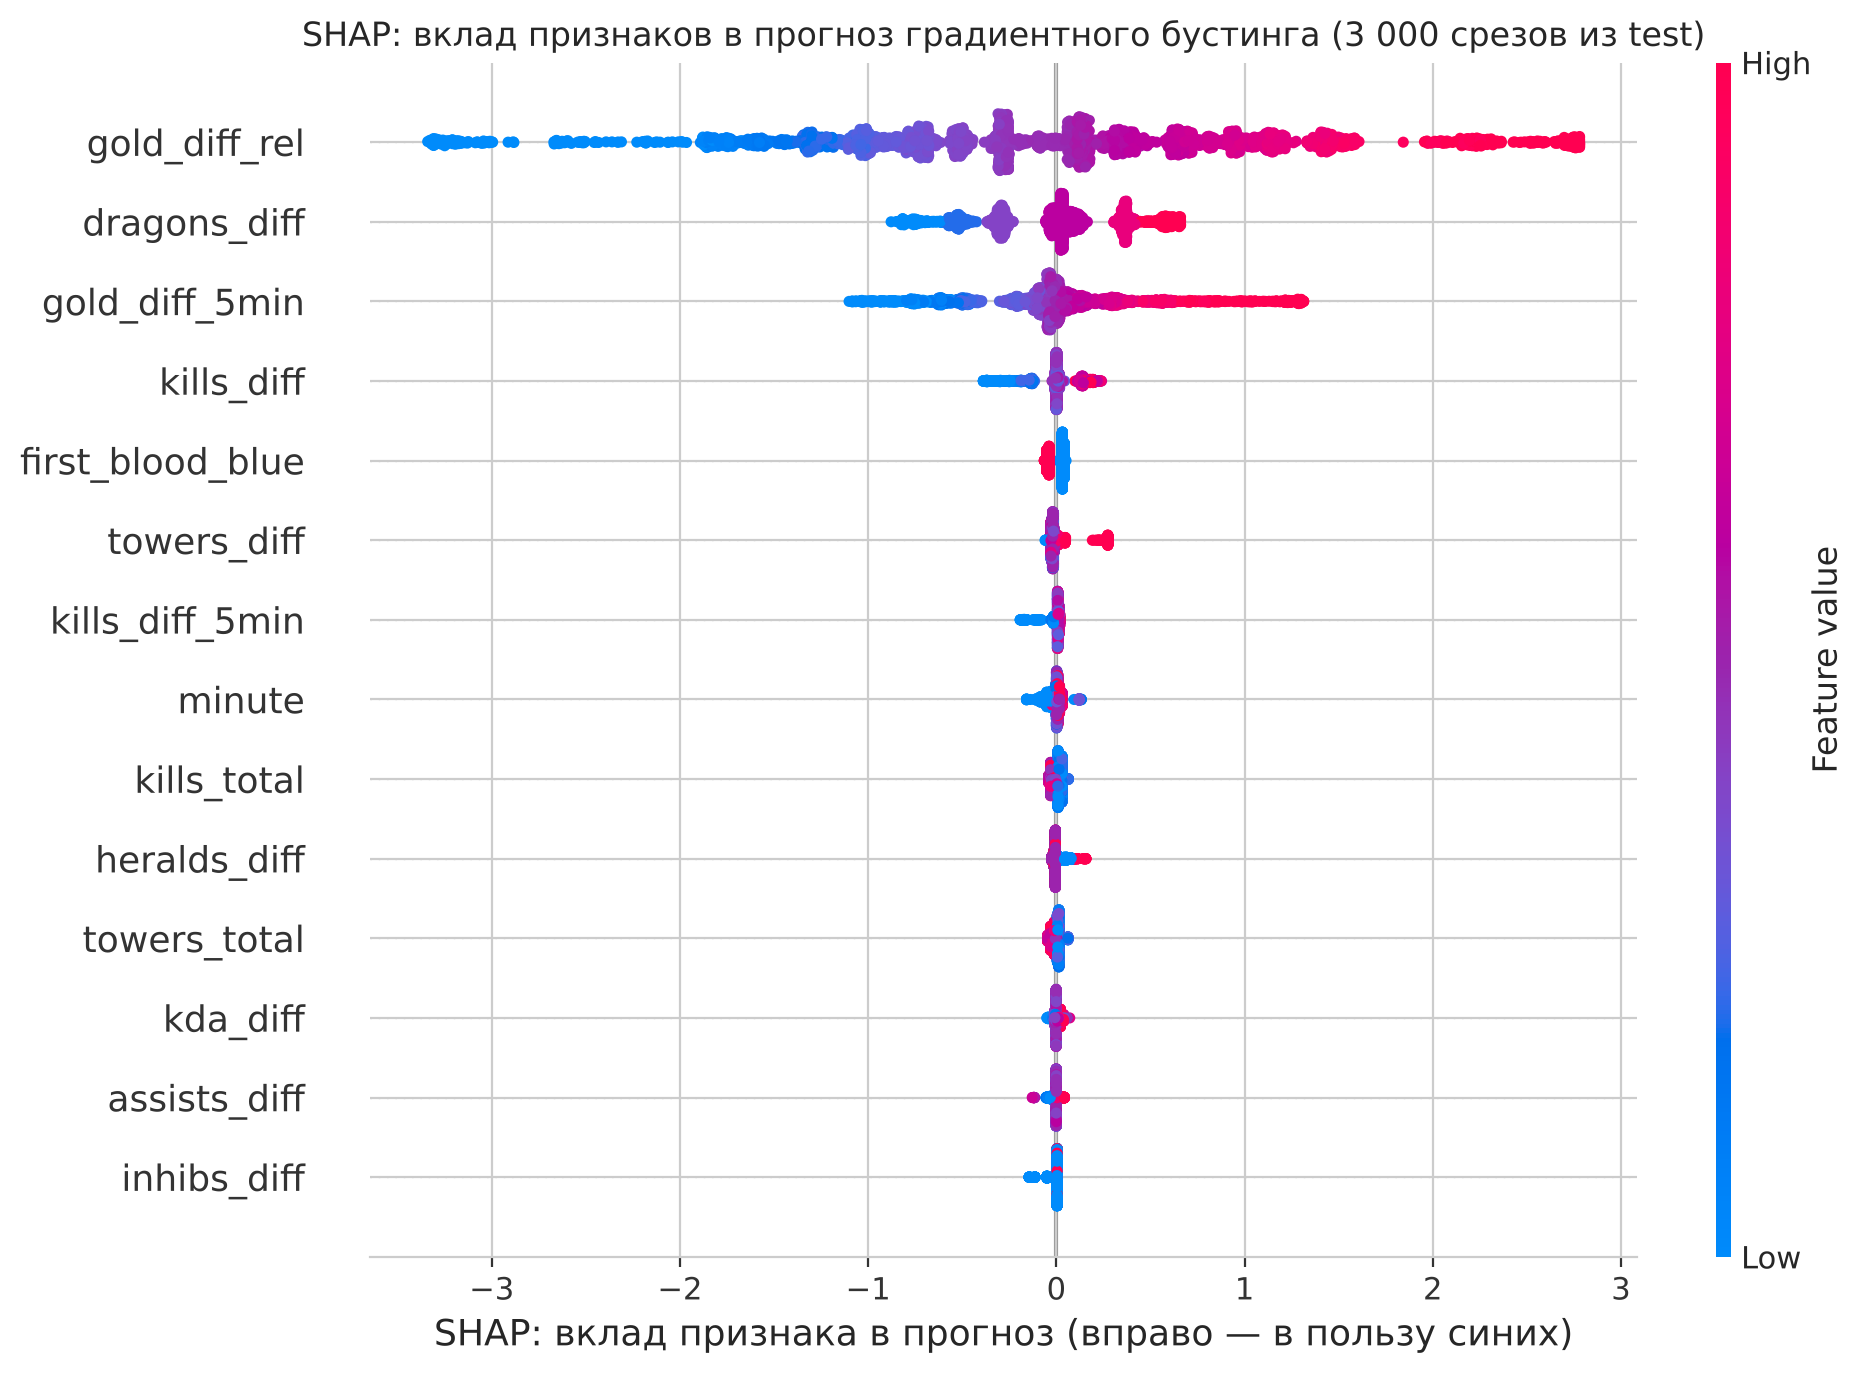

Средний |SHAP| по стадиям, топ-10 признаков:


,10-я минута,20-я минута,30-я минута
gold_diff_rel,0.714,1.086,1.233
dragons_diff,0.130,0.350,0.452
gold_diff_5min,0.092,0.277,0.454
kills_diff,0.037,0.104,0.140
first_blood_blue,0.037,0.038,0.038
towers_diff,0.019,0.027,0.053
kills_diff_5min,0.007,0.018,0.028
heralds_diff,0.006,0.016,0.018
kills_total,0.016,0.014,0.016
towers_total,0.010,0.011,0.017


In [54]:
import shap

gb_pipe = best_pipes['Gradient Boosting']
gb_names = clean_names(gb_pipe['prep'].get_feature_names_out())
explainer = shap.TreeExplainer(gb_pipe['model'])

X_shap = X_test.sample(3000, random_state=RANDOM_STATE)
X_shap_p = np.asarray(gb_pipe['prep'].transform(X_shap))
shap_values = explainer.shap_values(X_shap_p)

shap.summary_plot(shap_values, X_shap_p, feature_names=gb_names, max_display=14, show=False, plot_size=(10, 7))
plt.xlabel('SHAP: вклад признака в прогноз (вправо — в пользу синих)')
plt.title('SHAP: вклад признаков в прогноз градиентного бустинга (3 000 срезов из test)')
plt.tight_layout()
plt.savefig('figures/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# Средний модуль SHAP по стадиям: какие признаки сильнее всего двигают прогноз на 10-й, 20-й и 30-й минуте
shap_by_stage = {}
for T in [10, 20, 30]:
    X_T_p = np.asarray(gb_pipe['prep'].transform(X_test[(test['minute'] == T).values]))
    shap_by_stage[f'{T}-я минута'] = pd.Series(np.abs(explainer.shap_values(X_T_p)).mean(axis=0), index=gb_names)
shap_by_stage = pd.DataFrame(shap_by_stage).sort_values('20-я минута', ascending=False)
shap_by_stage.to_csv('results/shap_by_stage.csv')
print('Средний |SHAP| по стадиям, топ-10 признаков:')
shap_by_stage.head(10).round(3)

**Какие признаки важны на разных стадиях.**

**Сами по себе (10.1).** Перевес по золоту лучший на всех стадиях (0,74 → 0,86 → 0,92). Убийства информативны с самого начала (0,69 → 0,81 → 0,87). Башни на 10-й минуте почти бесполезны (0,56), а к 20-й сравниваются с убийствами. Бароны и ингибиторы начинают работать только к 30-й минуте.

**Что добавляет новое к золоту (10.2–10.4).** Три вывода подтверждаются всеми тремя методами: коэффициентами, permutation importance и SHAP.

- **Золото — основа прогноза на всех стадиях.** Перемешивание `gold_diff_rel` снижает ROC-AUC на 0,16–0,19; его коэффициент растёт по стадиям: 1,15 → 1,49 → 1,97.
- **Драконы — главный признак после золота, и их вес растёт.** Коэффициент 0,17 → 0,38 → 0,45, permutation importance 0,007 → 0,023 → 0,024, средний |SHAP| 0,13 → 0,35 → 0,45. Вероятная причина: дракон даёт команде усиление, а не золото, поэтому в перевесе по золоту он не виден.
- **Темп важен с середины игры.** У `gold_diff_5min` коэффициент 0 → 0,29 → 0,19, permutation importance 0,003 → 0,009 → 0,018. На ранних минутах темп почти дублирует сам перевес: их корреляция 0,91 на 10-й минуте и 0,81 на 30-й (раздел 3.6).
- **Убийства и башни почти ничего не добавляют к золоту:** permutation importance `kills_diff` около 0,002 на 20-й и 30-й минутах, у остальных признаков группы — около нуля. За убийства и башни команда получает золото, и их вклад уже учтён в перевесе.

**Что видно только одним методом — гипотезы.**

- **Недавние убийства и бароны в поздней игре.** В отдельной модели на 30-й минуте у `kills_diff_5min` коэффициент 0,33, у `barons_diff` — 0,07. Но в итоговой модели и в бустинге их вклад около нуля (permutation importance меньше 0,0005, |SHAP| 0,03 и 0). Утверждать, что в поздней игре важны последние драки и бароны, по этим данным нельзя.
- **Отрицательные коэффициенты.** На 10-й минуте у `towers_diff` коэффициент −0,17, в итоговой модели у `first_blood_blue` −0,08, хотя само по себе первое убийство синих даёт им 65% побед. Противоречия нет: коэффициент показывает эффект при одинаковом золоте. Почему он отрицательный, не проверялось.

**Коротко по стадиям.** Ранняя игра (10-я минута): почти всё решает золото. Середина (20-я): золото, драконы и темп. Поздняя игра (30-я): те же три признака, вес драконов и темпа выше.

SHAP посчитан для градиентного бустинга — другой, нелинейной модели. Первые три признака у него те же: `gold_diff_rel`, `dragons_diff`, `gold_diff_5min`. Подписи осей на графике SHAP библиотека выводит на английском: Feature value — значение признака.

## 11. Продуктовая часть: калибровка и график шанса победы

### 11.1 Можно ли верить вероятностям

Для трансляции важна не только правильность «кто победит», но и сама цифра. Проверяем калибровку: делим прогнозы теста на 10 групп по предсказанной вероятности и сравниваем её с реальной долей побед синих в группе.

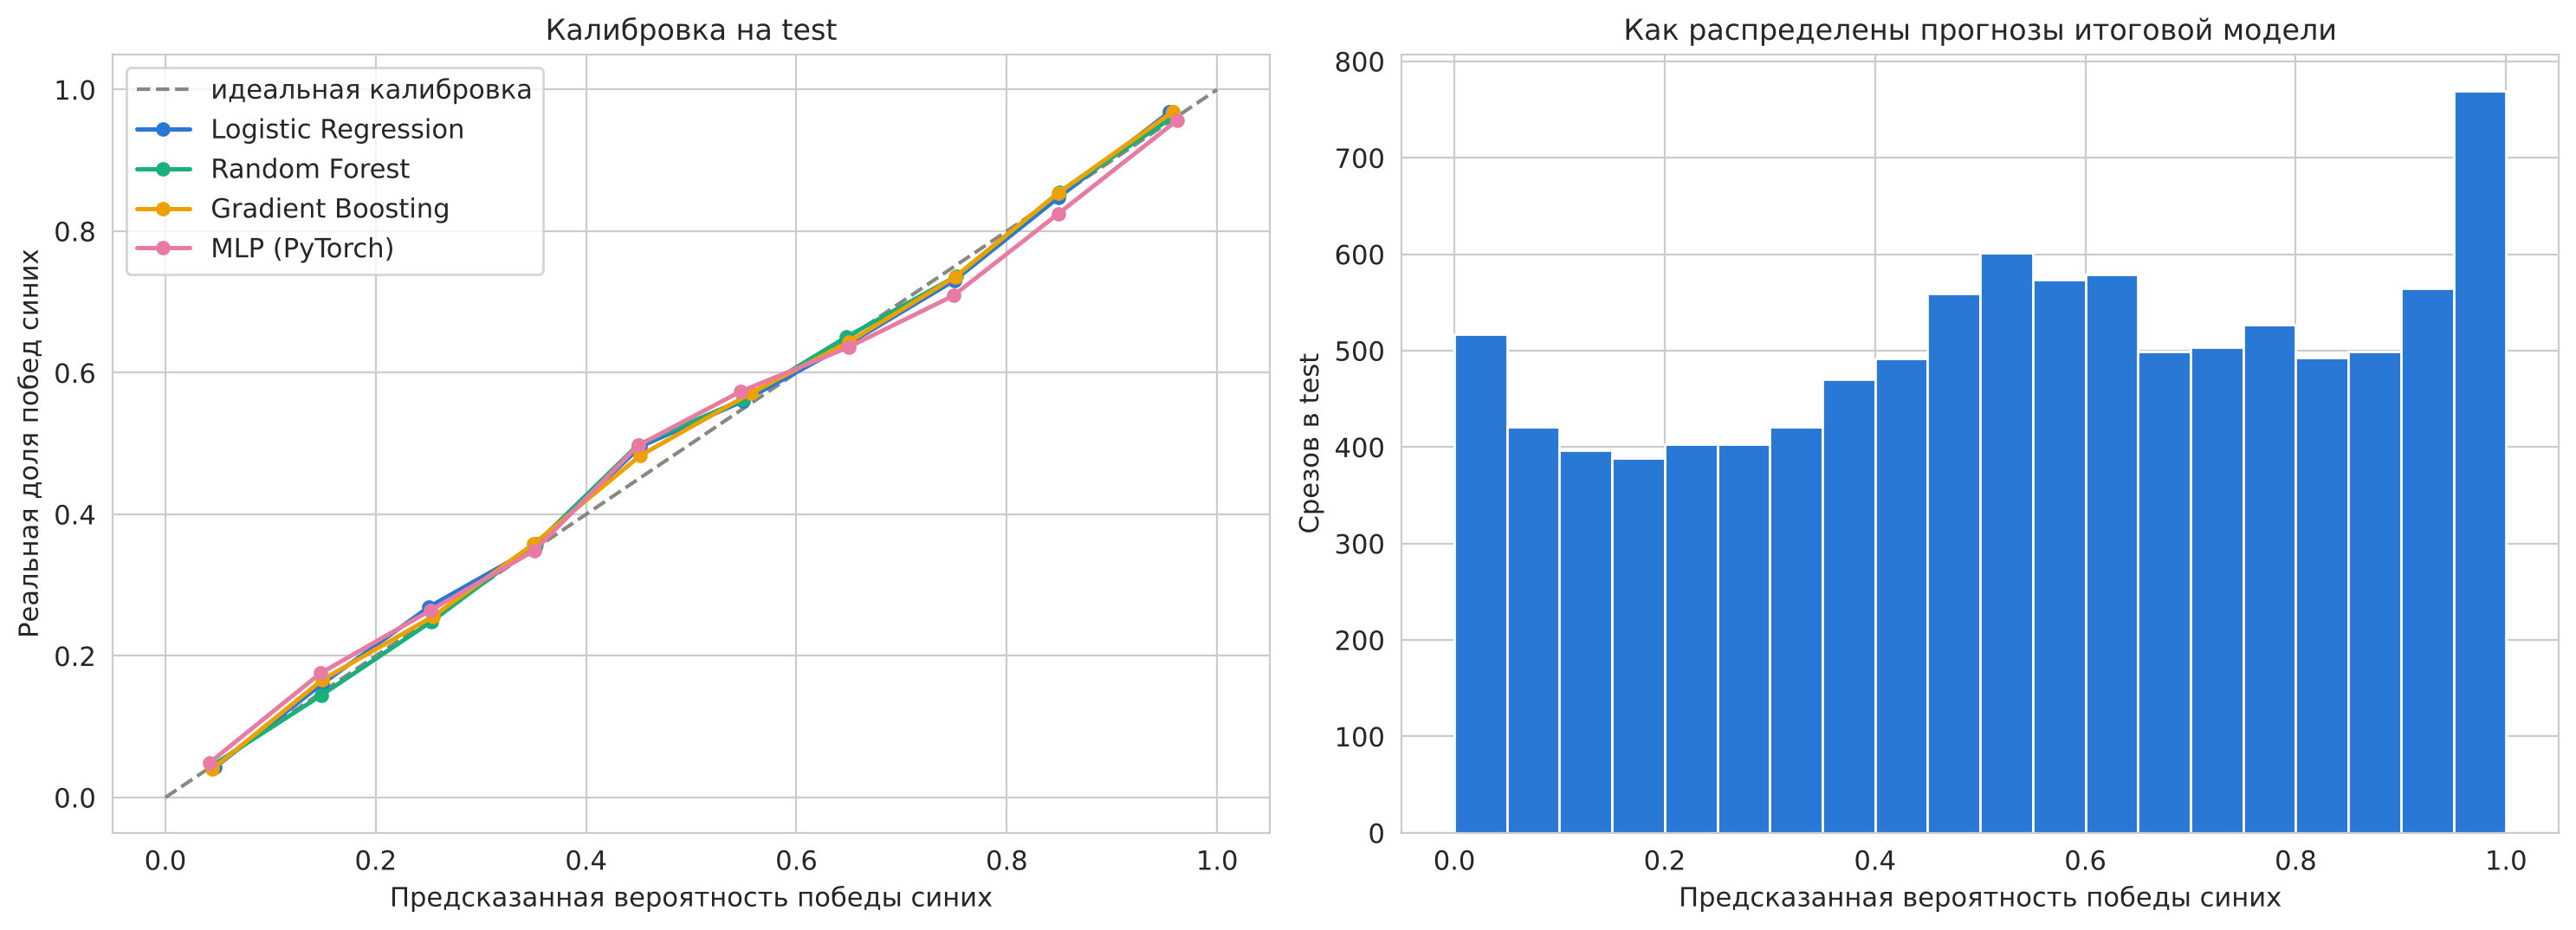

,Log-loss,Brier score,Макс. отклонение от диагонали
Модель,,,
Logistic Regression,0.4934,0.1661,0.0440
Random Forest,0.4987,0.1677,0.0487
Gradient Boosting,0.4954,0.1667,0.0314
MLP (PyTorch),0.4949,0.1666,0.0477


In [55]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot([0, 1], [0, 1], color=C_GRAY, linestyle='--', label='идеальная калибровка')
calib_rows = []
for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'MLP (PyTorch)']:
    frac_pos, mean_pred = calibration_curve(y_test, proba_test[name], n_bins=10)
    axes[0].plot(mean_pred, frac_pos, marker='o', markersize=5, color=MODEL_COLORS[name], linewidth=1.8, label=name)
    calib_rows.append({'Модель': name, 'Log-loss': log_loss(y_test, proba_test[name]),
                       'Brier score': brier_score_loss(y_test, proba_test[name]),
                       'Макс. отклонение от диагонали': np.abs(frac_pos - mean_pred).max()})
axes[0].set_title('Калибровка на test')
axes[0].set_xlabel('Предсказанная вероятность победы синих')
axes[0].set_ylabel('Реальная доля побед синих')
axes[0].legend()

axes[1].hist(proba_final, bins=20, range=(0, 1), color=C_BLUE, edgecolor='white')
axes[1].set_title('Как распределены прогнозы итоговой модели')
axes[1].set_xlabel('Предсказанная вероятность победы синих')
axes[1].set_ylabel('Срезов в test')
plt.tight_layout()
plt.savefig('figures/calibration.png', dpi=150, bbox_inches='tight')
plt.show()

calibration = pd.DataFrame(calib_rows).set_index('Модель')
calibration.to_csv('results/calibration.csv')
calibration.round(4)

In [56]:
# Уверенные прогнозы: как часто модель говорит «80% и больше» и как часто при этом права
conf_rows = []
for T in MINUTES:
    mask = (test['minute'] == T).values
    p_T, y_T = proba_final[mask], y_test[mask].values
    confident = (p_T >= 0.8) | (p_T <= 0.2)
    conf_rows.append({'Минута': T, 'Доля уверенных прогнозов': confident.mean(),
                      'Точность уверенных прогнозов': ((p_T[confident] >= 0.5) == y_T[confident]).mean() if confident.any() else np.nan,
                      'Средняя заявленная уверенность': np.maximum(p_T[confident], 1 - p_T[confident]).mean() if confident.any() else np.nan})
confident_table = pd.DataFrame(conf_rows).set_index('Минута')
confident_table.to_csv('results/confident_predictions.csv')
confident_table.round(3)

,Доля уверенных прогнозов,Точность уверенных прогнозов,Средняя заявленная уверенность
Минута,,,
5,0.117,0.804,0.858
10,0.191,0.880,0.876
15,0.346,0.903,0.893
20,0.454,0.910,0.909
25,0.566,0.923,0.919
30,0.616,0.935,0.922
35,0.625,0.934,0.918
40,0.556,0.888,0.918


### 11.2 График шанса победы по ходу матча

Так результат модели выглядит для зрителя. Берём три матча из теста (модель их не видела) и считаем вероятность на каждой минуте, начиная с 5-й:

- **камбэк:** матч, в котором будущий победитель имел самый низкий шанс после 20-й минуты;
- **односторонняя игра:** самый большой перевес по золоту на 20-й минуте;
- **качели:** матч, где фаворит менялся чаще всего.

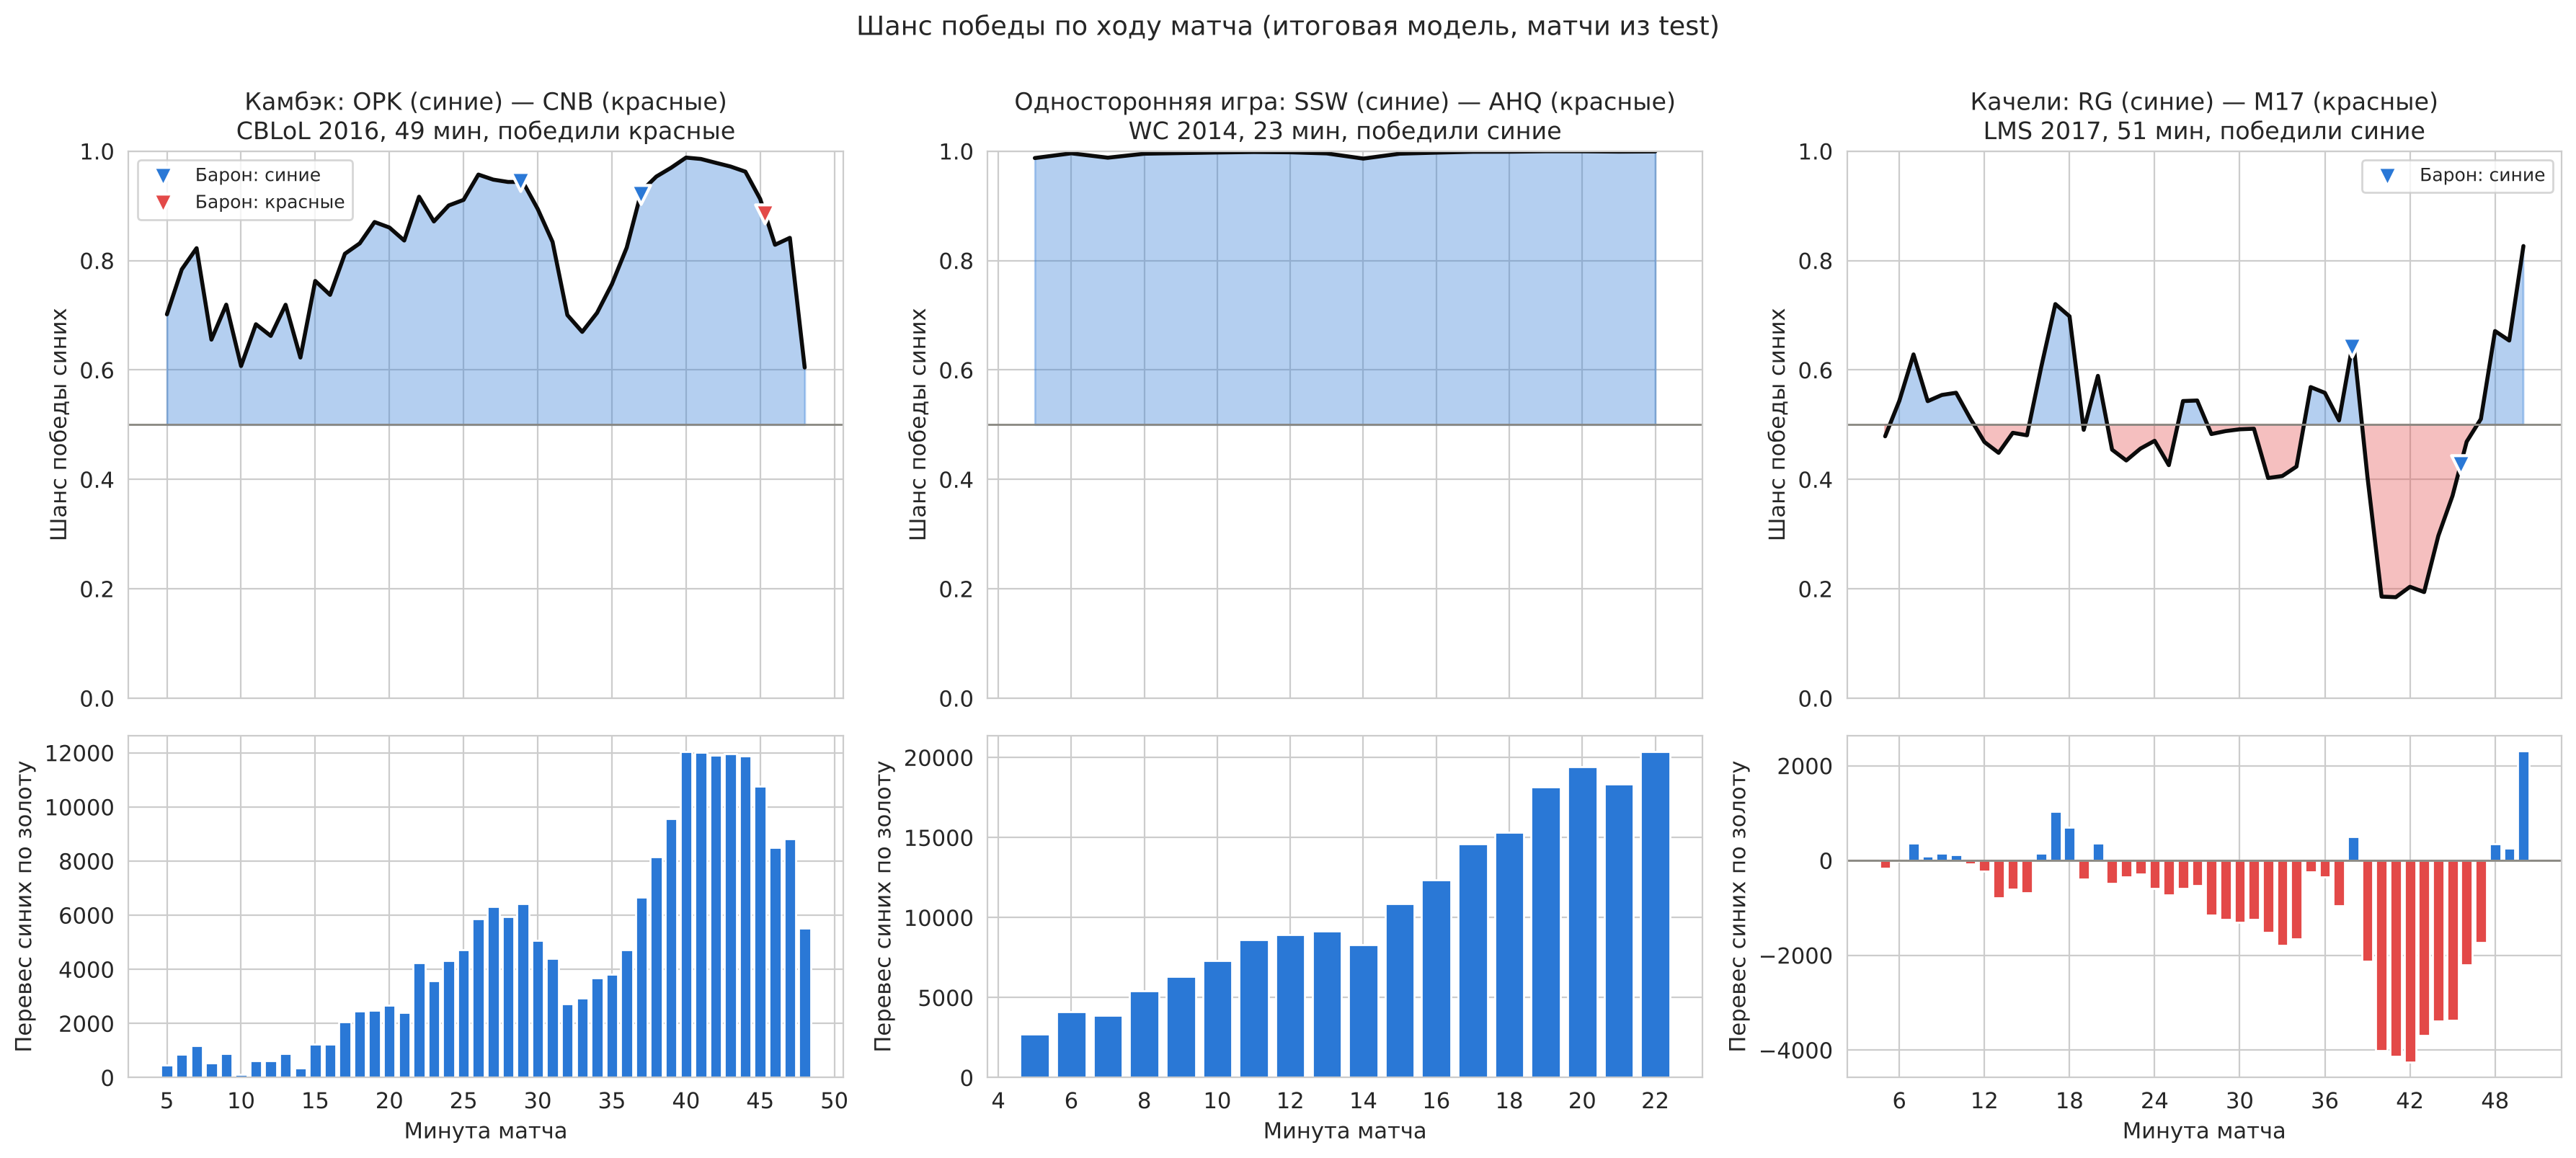

Камбэк: OPK — CNB, CBLoL 2016. Минимальный шанс будущего победителя: 1.2% на 40-й минуте (перевес синих по золоту 12033); на последней минуте шанс победителя 39.6%
Односторонняя игра: SSW — AHQ, WC 2014. Минимальный шанс будущего победителя: 98.6% на 14-й минуте (перевес синих по золоту 8315); на последней минуте шанс победителя 99.9%
Качели: RG — M17, LMS 2017. Минимальный шанс будущего победителя: 18.5% на 41-й минуте (перевес синих по золоту -4137); на последней минуте шанс победителя 82.7%


In [57]:
def win_curve(match_id):
    """Вероятность победы синих на каждой минуте матча, начиная с 5-й."""
    m = all_matches[match_id]
    table = pd.DataFrame([make_snapshot(m, T) for T in range(5, m.gamelength)])
    table['p_blue'] = final_model.predict_proba(table[features])[:, 1]
    return table


# Выбор матчей по прогнозам на тесте
test_view = test[['match_id', 'minute', 'gold_diff_rel', target]].copy()
test_view['p_blue'] = proba_final
test_view['p_winner'] = np.where(test_view[target] == 1, test_view['p_blue'], 1 - test_view['p_blue'])

comeback_id = test_view[test_view['minute'] >= 20].sort_values('p_winner').iloc[0]['match_id']
stomp_id = test_view[test_view['minute'] == 20].assign(lead=lambda t: t['gold_diff_rel'].abs()).sort_values('lead').iloc[-1]['match_id']
flips = test_view.groupby('match_id')['p_blue'].apply(lambda p: (np.diff(np.sign(p.values - 0.5)) != 0).sum())
swing_id = flips.drop(index=[comeback_id, stomp_id]).idxmax()
story_ids = {'Камбэк': int(comeback_id), 'Односторонняя игра': int(stomp_id), 'Качели': int(swing_id)}

fig, axes = plt.subplots(2, 3, figsize=(18, 8), gridspec_kw={'height_ratios': [1.6, 1]}, sharex='col')
for j, (story, mid) in enumerate(story_ids.items()):
    m = all_matches[mid]
    curve = win_curve(mid)
    winner = 'синие' if m.blue_win == 1 else 'красные'

    ax = axes[0, j]
    ax.plot(curve['minute'], curve['p_blue'], color='#0b0b0b', linewidth=2)
    ax.fill_between(curve['minute'], 0.5, curve['p_blue'], where=curve['p_blue'] >= 0.5, color=C_BLUE, alpha=0.35, interpolate=True)
    ax.fill_between(curve['minute'], 0.5, curve['p_blue'], where=curve['p_blue'] < 0.5, color=C_RED, alpha=0.35, interpolate=True)
    ax.axhline(0.5, color=C_GRAY, linewidth=1)
    for events, color, label in [(m.bBarons, C_BLUE, 'Барон: синие'), (m.rBarons, C_RED, 'Барон: красные')]:
        times = [e[0] for e in events if 5 <= e[0] <= curve['minute'].max()]
        if times:
            ax.scatter(times, np.interp(times, curve['minute'], curve['p_blue']), s=90, marker='v', color=color,
                       edgecolor='white', linewidth=1.5, zorder=5, label=label)
    ax.set_ylim(0, 1)
    ax.set_title(f'{story}: {m.blueTeamTag} (синие) — {m.redTeamTag} (красные)\n{m.League} {m.Year}, {m.gamelength} мин, победили {winner}')
    ax.set_ylabel('Шанс победы синих')
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc='best', fontsize=9)

    ax = axes[1, j]
    ax.bar(curve['minute'], curve['gold_diff'], color=np.where(curve['gold_diff'] >= 0, C_BLUE, C_RED), width=0.8)
    ax.axhline(0, color=C_GRAY, linewidth=1)
    ax.set_ylabel('Перевес синих по золоту')
    ax.set_xlabel('Минута матча')
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.suptitle('Шанс победы по ходу матча (итоговая модель, матчи из test)', y=1.0)
plt.tight_layout()
plt.savefig('figures/win_probability.png', dpi=150, bbox_inches='tight')
plt.show()

for story, mid in story_ids.items():
    curve = win_curve(mid)
    m = all_matches[mid]
    p_winner = curve['p_blue'] if m.blue_win == 1 else 1 - curve['p_blue']
    low = p_winner.idxmin()
    print(f"{story}: {m.blueTeamTag} — {m.redTeamTag}, {m.League} {m.Year}. Минимальный шанс будущего победителя: "
          f"{p_winner[low]:.1%} на {curve['minute'][low]}-й минуте (перевес синих по золоту {curve['gold_diff'][low]}); "
          f"на последней минуте шанс победителя {p_winner.iloc[-1]:.1%}")

### 11.3 Из чего складывается прогноз

Итоговая модель линейная, поэтому любой прогноз раскладывается на слагаемые: вклад признака = коэффициент × стандартизованное значение. Разберём момент из матча-камбэка, когда шанс будущего победителя был минимальным.

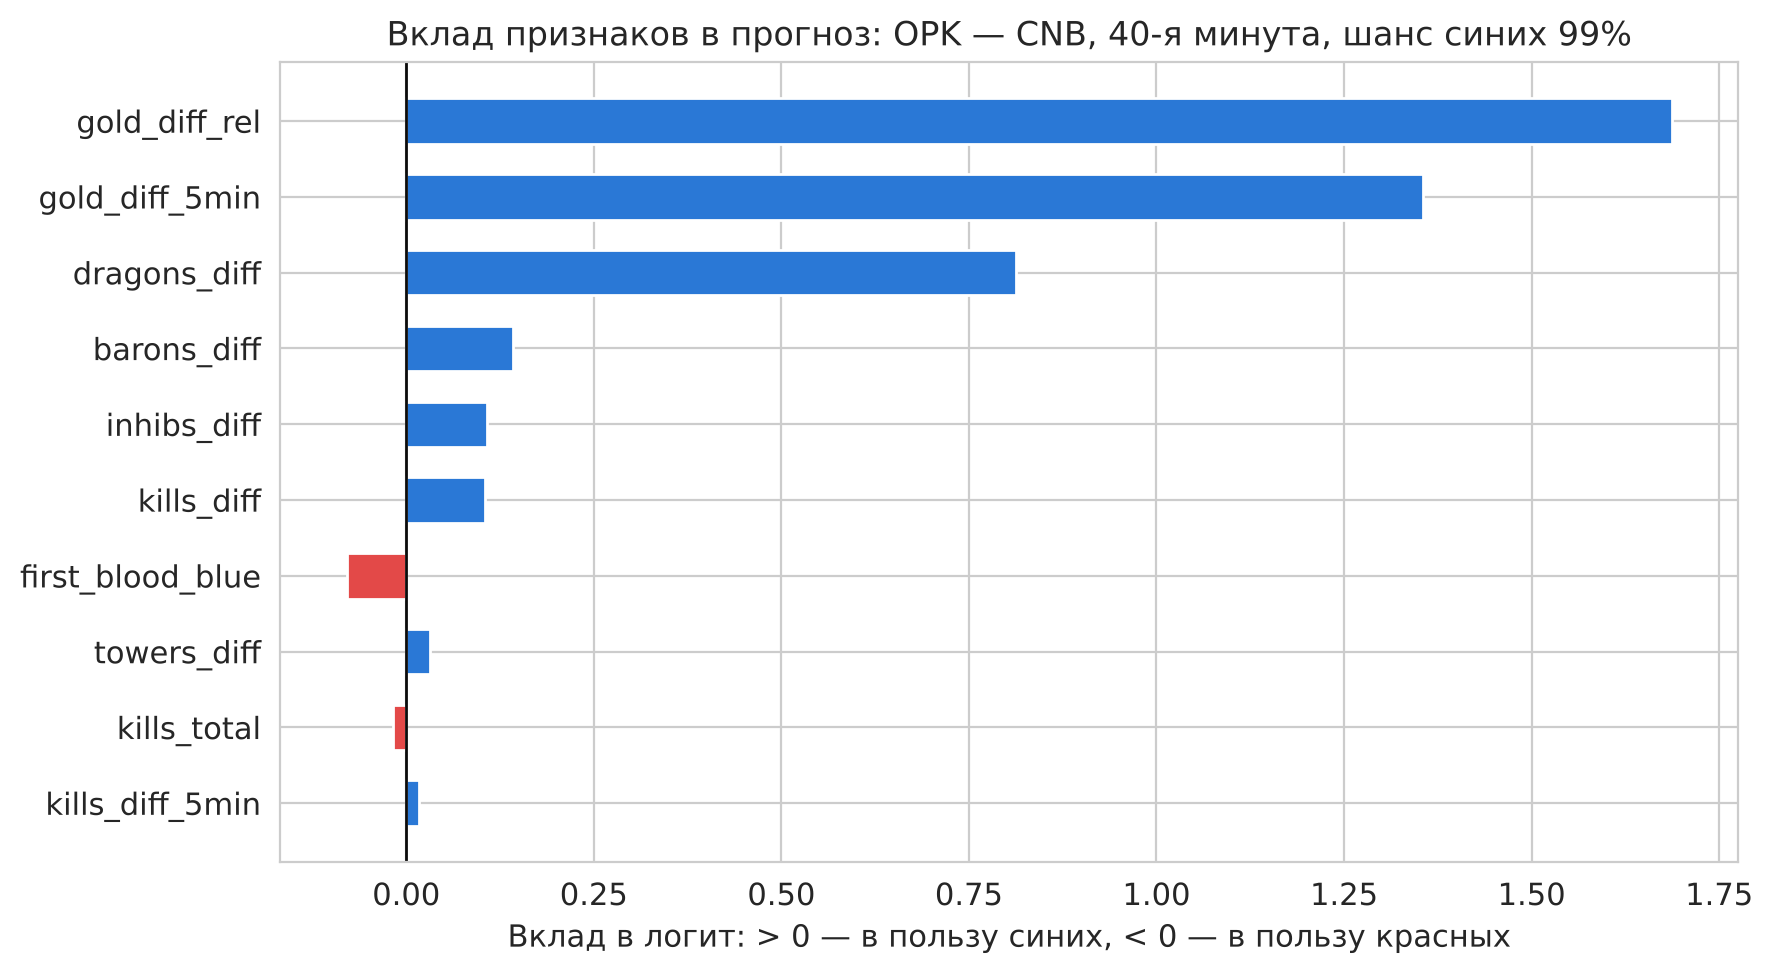

Значения признаков в этот момент:
 minute  gold_diff  gold_diff_rel  gold_diff_5min  kills_diff  towers_diff  inhibs_diff  dragons_diff  barons_diff
     40      12033       8.778662            8210           3            4            1             3            2
Свободный член модели: 0.264


In [58]:
curve = win_curve(story_ids['Камбэк'])
m = all_matches[story_ids['Камбэк']]
p_winner = curve['p_blue'] if m.blue_win == 1 else 1 - curve['p_blue']
moment = curve.loc[[p_winner.idxmin()]]

x_scaled = np.asarray(final_model['prep'].transform(moment[features]))[0]
final_names = clean_names(final_model['prep'].get_feature_names_out())
contrib = pd.Series(final_model['model'].coef_[0] * x_scaled, index=final_names)
contrib = contrib[contrib.abs() > 1e-6]
contrib = contrib.loc[contrib.abs().sort_values().index].tail(10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(contrib.index, contrib.values, color=np.where(contrib.values >= 0, C_BLUE, C_RED), height=0.6)
ax.axvline(0, color='#0b0b0b', linewidth=1)
ax.set_title(f"Вклад признаков в прогноз: {m.blueTeamTag} — {m.redTeamTag}, {int(moment['minute'].iloc[0])}-я минута, "
             f"шанс синих {moment['p_blue'].iloc[0]:.0%}")
ax.set_xlabel('Вклад в логит: > 0 — в пользу синих, < 0 — в пользу красных')
plt.tight_layout()
plt.savefig('figures/explain_one.png', dpi=150, bbox_inches='tight')
plt.show()

print('Значения признаков в этот момент:')
print(moment[['minute', 'gold_diff', 'gold_diff_rel', 'gold_diff_5min', 'kills_diff', 'towers_diff', 'inhibs_diff',
              'dragons_diff', 'barons_diff']].to_string(index=False))
print(f"Свободный член модели: {final_model['model'].intercept_[0]:.3f}")

**Выводы по продуктовой части.**

- **Вероятностям можно верить.** Калибровочная кривая итоговой модели идёт вдоль диагонали, максимальное отклонение — 0,044. Log-loss и Brier score у неё лучшие среди моделей: 0,4934 и 0,1661.
- **Уверенных прогнозов мало в начале и много в конце.** «80% и больше» модель говорит в 19% случаев на 10-й минуте, в 45% на 20-й и в 62% на 30-й. Такие прогнозы сбываются в 88%, 91% и 93,5% случаев. На 5-й и 40-й минутах модель немного самоувереннее, чем следует (80% при заявленных 86% и 89% при заявленных 92%).
- **График шанса читается без пояснений.** В односторонней игре (SSW — AHQ, чемпионат мира 2014) шанс синих с 5-й минуты не опускается ниже 98,6%. В «качелях» (RG — M17, LMS 2017) линия несколько раз пересекает 50%.
- **Камбэки модель не предсказывает.** В матче OPK — CNB (CBLoL 2016) синие на 40-й минуте вели на 12 тыс. золота, модель давала красным 1,2%, а красные победили на 49-й минуте. Модель с честными вероятностями и должна изредка ошибаться при уверенности 99%.
- **Прогноз объясним.** В тот же момент шанс синих складывался в основном из относительного перевеса по золоту, его роста за последние пять минут (+8 210) и перевеса по драконам.

## 12. Дополнительные исследования

### 12.1 Ablation study: что дают группы признаков

Обучаем итоговую модель без одной группы признаков и только на одной группе (плюс минута). Качество — 5-fold CV по матчам.

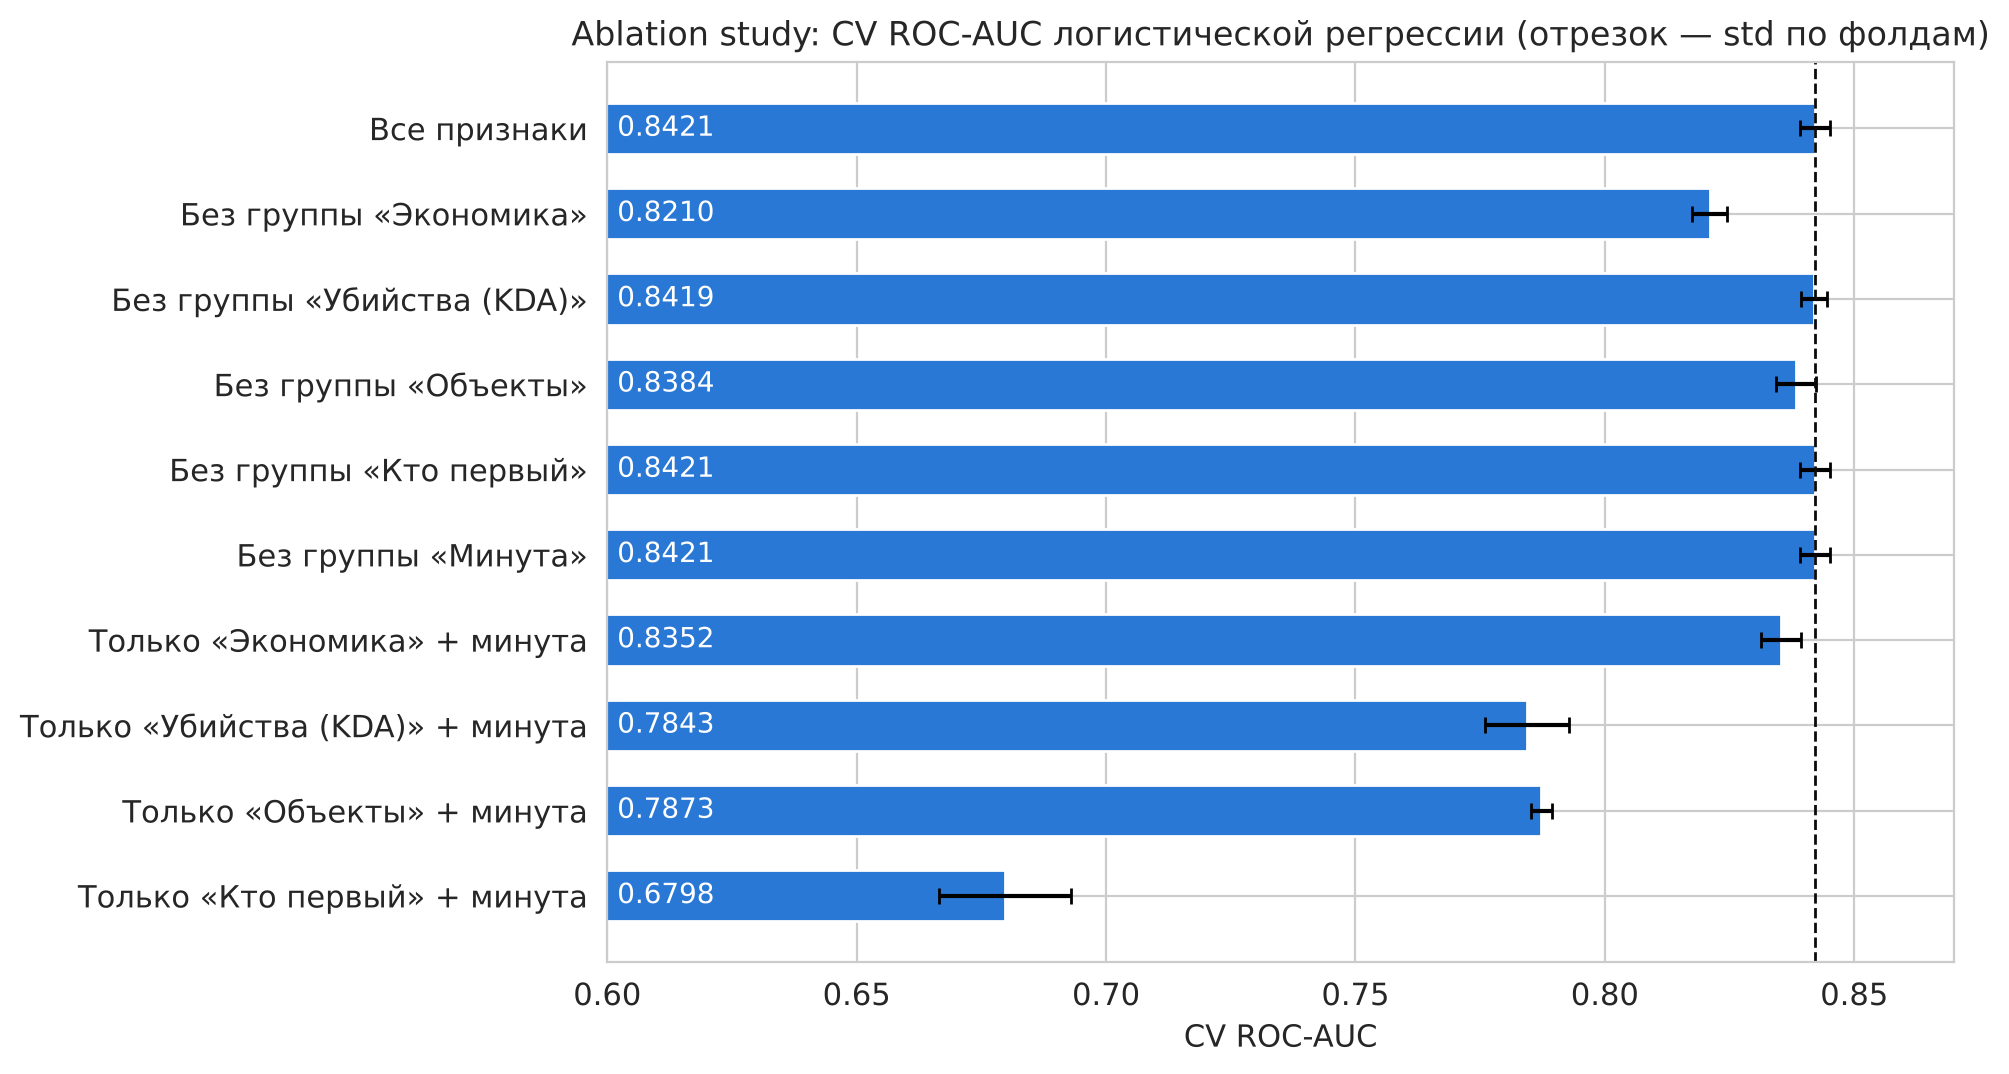

,CV ROC-AUC,std,Изменение к полному набору
Набор признаков,,,
Все признаки,0.8421,0.0030,0.0000
Без группы «Экономика»,0.8210,0.0036,-0.0211
Без группы «Убийства (KDA)»,0.8419,0.0026,-0.0003
Без группы «Объекты»,0.8384,0.0040,-0.0038
Без группы «Кто первый»,0.8421,0.0031,-0.0000
Без группы «Минута»,0.8421,0.0030,0.0000
Только «Экономика» + минута,0.8352,0.0040,-0.0069
Только «Убийства (KDA)» + минута,0.7843,0.0084,-0.0578
Только «Объекты» + минута,0.7873,0.0022,-0.0548


In [59]:
def cv_for(feature_list):
    num = [c for c in feature_list if c in num_all + ['minute']]
    cat = [c for c in feature_list if c in cat_features]
    return cv_auc(make_pipe(new_logreg(), num=num, cat=cat))


full_auc, full_std = cv_for(features)          # полный набор: считаем один раз, дальше используем как точку сравнения
abl_rows = [{'Набор признаков': 'Все признаки', 'CV ROC-AUC': full_auc, 'std': full_std}]
for group, cols in feature_groups.items():
    mean_auc, std_auc = cv_for([c for c in features if c not in cols])
    abl_rows.append({'Набор признаков': f'Без группы «{group}»', 'CV ROC-AUC': mean_auc, 'std': std_auc})
for group, cols in feature_groups.items():
    if group == 'Минута':
        continue
    mean_auc, std_auc = cv_for(cols + ['minute'])
    abl_rows.append({'Набор признаков': f'Только «{group}» + минута', 'CV ROC-AUC': mean_auc, 'std': std_auc})
ablation = pd.DataFrame(abl_rows).set_index('Набор признаков')
ablation['Изменение к полному набору'] = ablation['CV ROC-AUC'] - ablation.loc['Все признаки', 'CV ROC-AUC']
ablation.to_csv('results/ablation.csv')

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_data = ablation.iloc[::-1]
ax.barh(plot_data.index, plot_data['CV ROC-AUC'], xerr=plot_data['std'], color=C_BLUE, height=0.6, capsize=3)
for i, value in enumerate(plot_data['CV ROC-AUC']):
    ax.text(0.602, i, f'{value:.4f}', va='center', color='white', fontsize=10)
ax.axvline(ablation.loc['Все признаки', 'CV ROC-AUC'], color='#0b0b0b', linestyle='--', linewidth=1)
ax.set_xlim(0.6, 0.87)
ax.set_title('Ablation study: CV ROC-AUC логистической регрессии (отрезок — std по фолдам)')
ax.set_xlabel('CV ROC-AUC')
plt.tight_layout()
plt.savefig('figures/ablation.png', dpi=150, bbox_inches='tight')
plt.show()

ablation.round(4)

### 12.2 Золото каких ролей важнее

В данных есть золото каждой из пяти ролей. Заменим общий перевес `gold_diff_rel` на пять перевесов по ролям и посмотрим на коэффициенты: сколько «стоит» 1 000 золота преимущества на каждой роли.

Основной набор:                         CV ROC-AUC 0.8421 ± 0.0030
Роли вместо gold_diff_rel:              CV ROC-AUC 0.8413 ± 0.0044
Основной набор + роли:                  CV ROC-AUC 0.8440 ± 0.0040


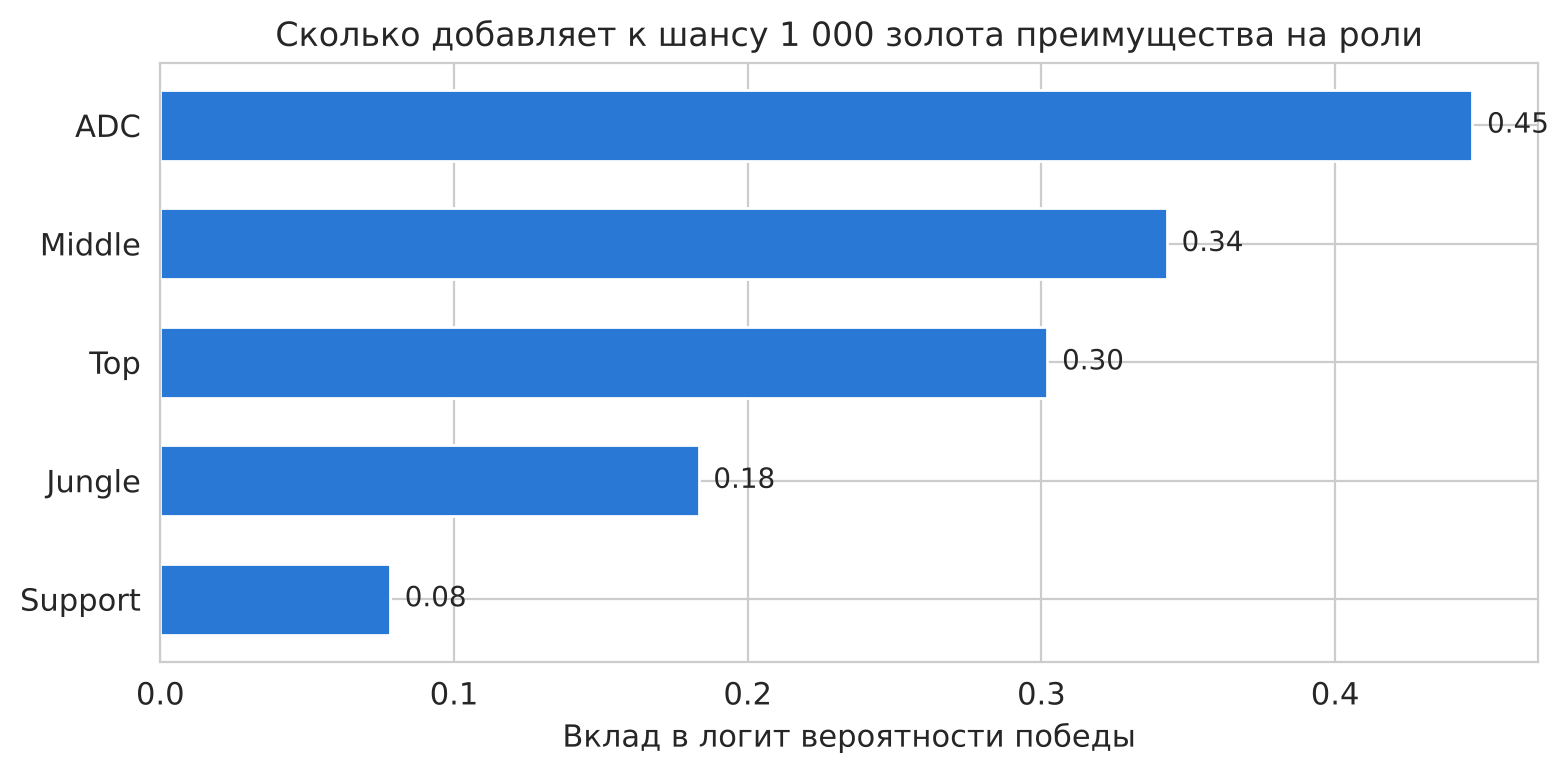

,Коэффициент (стандартизованный),"Std признака, золото",Вклад 1 000 золота в логит
Top,0.386,1277.225,0.302
Jungle,0.219,1196.846,0.183
Middle,0.438,1277.777,0.343
ADC,0.586,1311.453,0.447
Support,0.067,856.464,0.078


In [60]:
role_features = ['gold_diff_' + role.lower() for role in ROLES]

num_roles = [c for c in num_features if c != 'gold_diff_rel'] + role_features
pipe_roles = make_pipe(new_logreg(), num=num_roles)
auc_roles = cv_auc(pipe_roles, X=train[num_roles + cat_features])
auc_both = cv_auc(make_pipe(new_logreg(), num=num_features + role_features), X=train[num_features + role_features + cat_features])
print(f'Основной набор:                         CV ROC-AUC {full_auc:.4f} ± {full_std:.4f}')
print(f'Роли вместо gold_diff_rel:              CV ROC-AUC {auc_roles[0]:.4f} ± {auc_roles[1]:.4f}')
print(f'Основной набор + роли:                  CV ROC-AUC {auc_both[0]:.4f} ± {auc_both[1]:.4f}')

pipe_roles.fit(train[num_roles + cat_features], y_train)
role_coefs = pd.Series(pipe_roles['model'].coef_[0][:len(num_roles)], index=num_roles)[role_features]
role_std = train[role_features].std()

role_table = pd.DataFrame({'Коэффициент (стандартизованный)': role_coefs, 'Std признака, золото': role_std,
                           'Вклад 1 000 золота в логит': role_coefs / role_std * 1000})
role_table.index = ROLES
role_table.to_csv('results/roles.csv')

fig, ax = plt.subplots(figsize=(8, 4))
plot_data = role_table['Вклад 1 000 золота в логит'].sort_values()
ax.barh(plot_data.index, plot_data.values, color=C_BLUE, height=0.6)
for i, value in enumerate(plot_data.values):
    ax.text(value + 0.005, i, f'{value:.2f}', va='center', fontsize=10)
ax.set_title('Сколько добавляет к шансу 1 000 золота преимущества на роли')
ax.set_xlabel('Вклад в логит вероятности победы')
plt.tight_layout()
plt.savefig('figures/roles.png', dpi=150, bbox_inches='tight')
plt.show()

role_table.round(3)

### 12.3 Что даёт драфт

До начала игры известны только выбранные чемпионы. Проверим две вещи: насколько исход предсказуем по одному драфту и добавляет ли драфт что-то к состоянию игры. Чемпионы кодируются one-hot отдельно для синей и красной команды.

In [61]:
champ_blue = ['blue' + role + 'Champ' for role in ROLES]
champ_red = ['red' + role + 'Champ' for role in ROLES]
all_champs = sorted(pd.unique(df[champ_blue + champ_red].values.ravel()))

draft_blue = sum(pd.get_dummies(df[col]).reindex(columns=all_champs, fill_value=False).astype(int) for col in champ_blue)
draft_red = sum(pd.get_dummies(df[col]).reindex(columns=all_champs, fill_value=False).astype(int) for col in champ_red)
draft = pd.concat([draft_blue.add_prefix('blue_'), draft_red.add_prefix('red_')], axis=1)
draft_features = draft.columns.tolist()
print('Чемпионов:', len(all_champs), '| столбцов драфта:', len(draft_features))

# 1. Прогноз до начала игры: одна строка на матч, только драфт
draft_train, y_draft = draft.loc[train_ids], df.loc[train_ids, 'blue_win']
match_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for C in [0.01, 0.1, 1]:
    scores = cross_val_score(LogisticRegression(C=C, max_iter=3000), draft_train, y_draft, cv=match_cv, scoring='roc_auc')
    print(f'Только драфт, C={C}: CV ROC-AUC {scores.mean():.4f} ± {scores.std():.4f}')

# 2. Драфт + состояние игры: сравниваем на одних и тех же фолдах и с одной и той же регуляризацией (L2, C=0.01)
def state_model(with_draft):
    steps = [('num', StandardScaler(), num_features), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)]
    if with_draft:
        steps.append(('draft', 'passthrough', draft_features))
    return Pipeline([('prep', ColumnTransformer(steps)),
                     ('model', LogisticRegression(solver='saga', max_iter=5000, C=0.01, l1_ratio=0, random_state=RANDOM_STATE))])


train_draft = pd.concat([train[features], draft.loc[train['match_id']].reset_index(drop=True)], axis=1)
scores_state = cross_val_score(state_model(False), train_draft, y_train, cv=cv_splits, scoring='roc_auc')
scores_draft = cross_val_score(state_model(True), train_draft, y_train, cv=cv_splits, scoring='roc_auc')
print(f'Состояние игры:          CV ROC-AUC {scores_state.mean():.4f} ± {scores_state.std():.4f}')
print(f'Состояние игры + драфт:  CV ROC-AUC {scores_draft.mean():.4f} ± {scores_draft.std():.4f}')
print('Прирост от драфта по фолдам:', np.round(scores_draft - scores_state, 4))

Чемпионов: 140 | столбцов драфта: 280


Только драфт, C=0.01: CV ROC-AUC 0.5413 ± 0.0058


Только драфт, C=0.1: CV ROC-AUC 0.5417 ± 0.0083


Только драфт, C=1: CV ROC-AUC 0.5417 ± 0.0083


Состояние игры:          CV ROC-AUC 0.8418 ± 0.0030
Состояние игры + драфт:  CV ROC-AUC 0.8461 ± 0.0043
Прирост от драфта по фолдам: [0.0042 0.0013 0.003  0.009  0.004 ]


### 12.4 Анализ ошибок

Ошибок на test: 2596 из 10082 (25.7%)
Уверенных ошибок (модель давала 80% и больше проигравшему): 359 (13.8% всех ошибок), матчей с такими ошибками: 192 из 1524


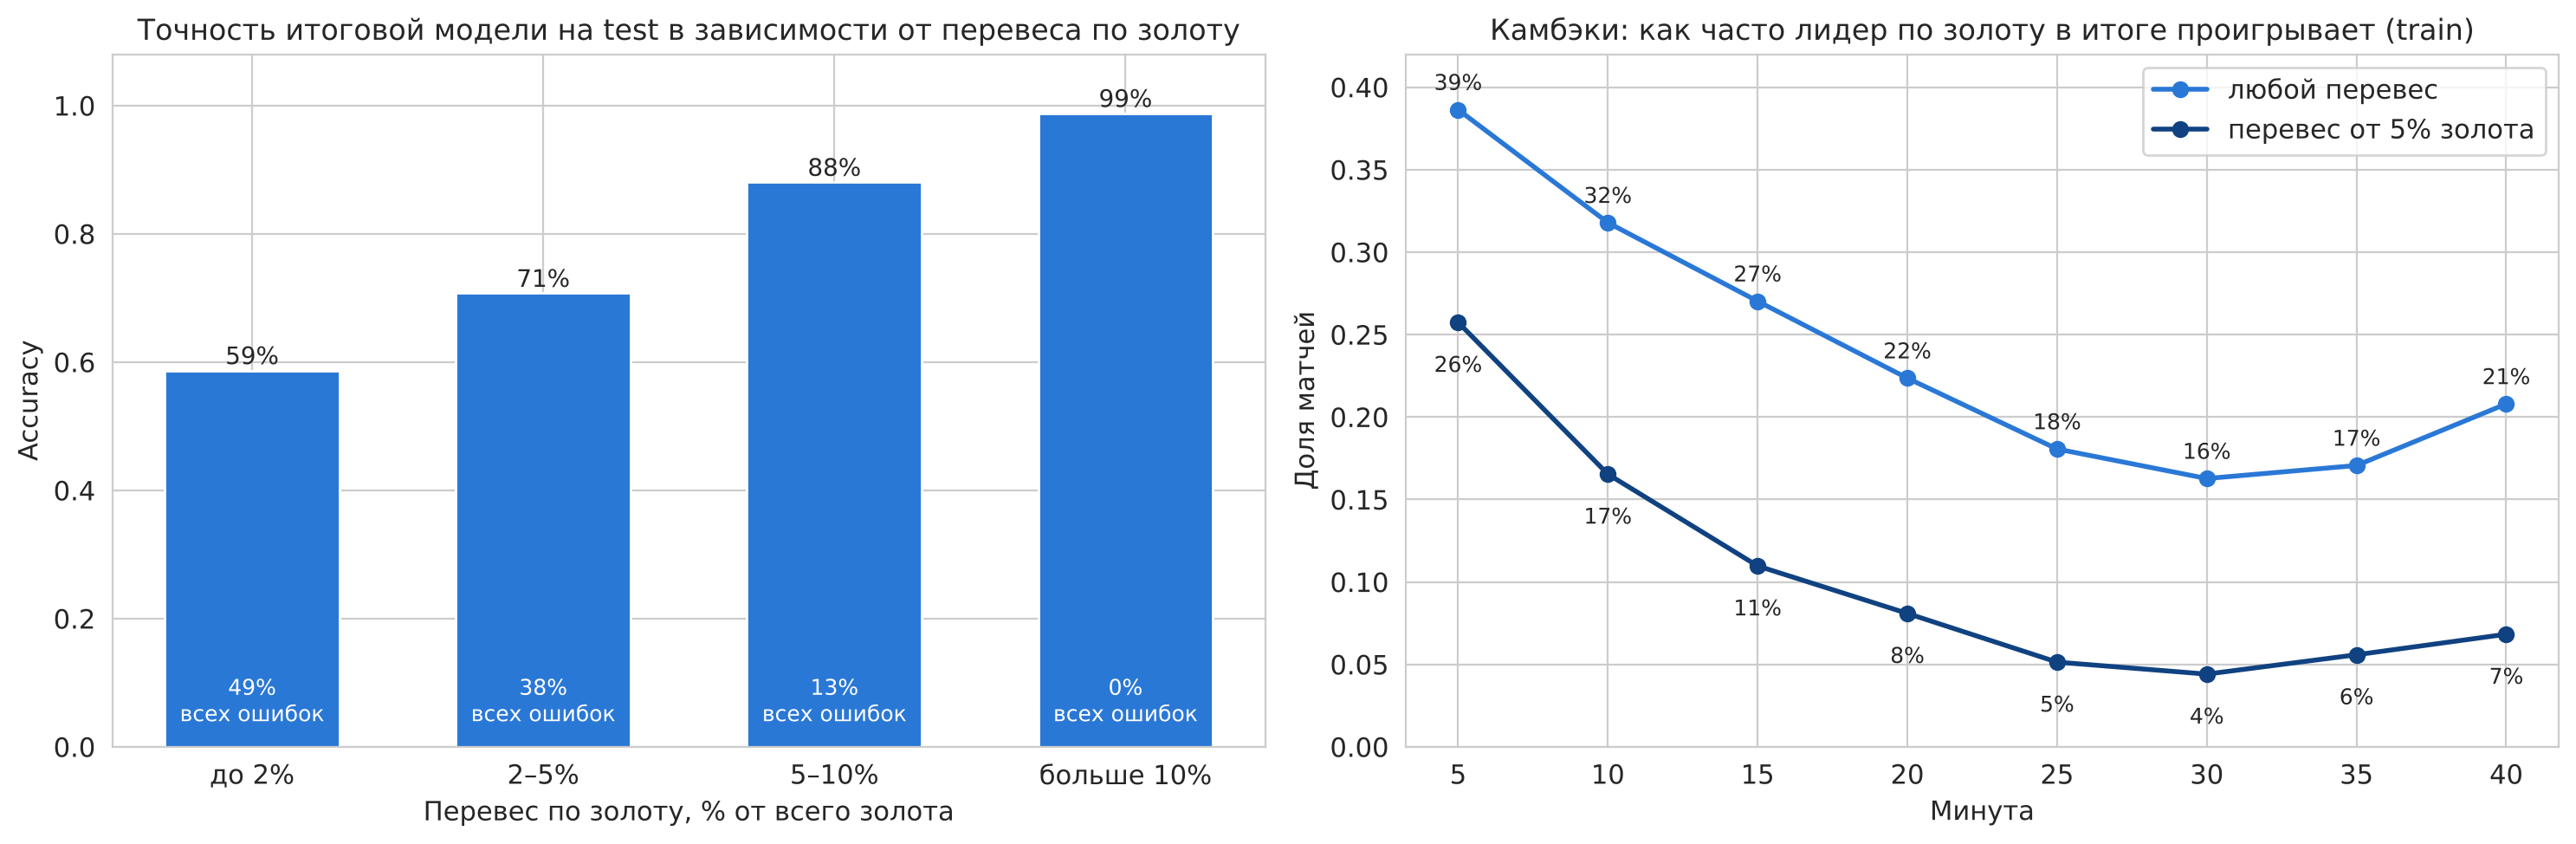

,Срезов,Ошибок,Точность,Доля срезов,Доля всех ошибок
lead,,,,,
до 2%,3071,1269,0.587,0.305,0.489
2–5%,3382,990,0.707,0.335,0.381
5–10%,2726,326,0.880,0.270,0.126
больше 10%,903,11,0.988,0.090,0.004


In [62]:
errors = test[['match_id', 'minute', 'gold_diff', 'gold_diff_rel', target]].copy()
errors['p_blue'] = proba_final
errors['error'] = ((errors['p_blue'] >= 0.5).astype(int) != errors[target])
errors['lead'] = pd.cut(errors['gold_diff_rel'].abs(), [-0.01, 2, 5, 10, 100], labels=['до 2%', '2–5%', '5–10%', 'больше 10%'])
errors['confident_error'] = errors['error'] & ((errors['p_blue'] >= 0.8) | (errors['p_blue'] <= 0.2))

print(f"Ошибок на test: {errors['error'].sum()} из {len(errors)} ({errors['error'].mean():.1%})")
print(f"Уверенных ошибок (модель давала 80% и больше проигравшему): {errors['confident_error'].sum()} "
      f"({errors['confident_error'].sum() / errors['error'].sum():.1%} всех ошибок), "
      f"матчей с такими ошибками: {errors.loc[errors['confident_error'], 'match_id'].nunique()} из {errors['match_id'].nunique()}")

by_lead = errors.groupby('lead', observed=True).agg(Срезов=('error', 'size'), Ошибок=('error', 'sum'), Точность=('error', lambda e: 1 - e.mean()))
by_lead['Доля срезов'] = by_lead['Срезов'] / len(errors)
by_lead['Доля всех ошибок'] = by_lead['Ошибок'] / errors['error'].sum()
by_lead.to_csv('results/error_by_lead.csv')

# Камбэки в данных (train): как часто команда, которая ведёт по золоту на минуте T, в итоге проигрывает
comebacks = train[train['gold_diff'] != 0].groupby('minute').apply(lambda g: ((g['gold_diff'] > 0) != (g[target] == 1)).mean())
big_lead = train[train['gold_diff_rel'].abs() >= 5]
comebacks_big = big_lead.groupby('minute').apply(lambda g: ((g['gold_diff'] > 0) != (g[target] == 1)).mean())
comeback_table = pd.DataFrame({'Лидер по золоту проигрывает': comebacks, 'Лидер с перевесом от 5% проигрывает': comebacks_big,
                               'Срезов с перевесом от 5%': big_lead.groupby('minute').size()})
comeback_table.to_csv('results/comebacks.csv')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(by_lead.index.astype(str), by_lead['Точность'], color=C_BLUE, width=0.6)
for i, (acc, share) in enumerate(zip(by_lead['Точность'], by_lead['Доля всех ошибок'])):
    axes[0].text(i, acc + 0.01, f'{acc:.0%}', ha='center', fontsize=10)
    axes[0].text(i, 0.04, f'{share:.0%}\nвсех ошибок', ha='center', fontsize=9, color='white')
axes[0].set_ylim(0, 1.08)
axes[0].set_title('Точность итоговой модели на test в зависимости от перевеса по золоту')
axes[0].set_xlabel('Перевес по золоту, % от всего золота')
axes[0].set_ylabel('Accuracy')

axes[1].plot(comeback_table.index, comeback_table['Лидер по золоту проигрывает'], marker='o', color=C_BLUE, linewidth=2,
             label='любой перевес')
axes[1].plot(comeback_table.index, comeback_table['Лидер с перевесом от 5% проигрывает'], marker='o', color='#104281',
             linewidth=2, label='перевес от 5% золота')
for T, value in comeback_table['Лидер по золоту проигрывает'].items():
    axes[1].text(T, value + 0.012, f'{value:.0%}', ha='center', fontsize=9)
for T, value in comeback_table['Лидер с перевесом от 5% проигрывает'].items():
    axes[1].text(T, value - 0.03, f'{value:.0%}', ha='center', fontsize=9)
axes[1].set_ylim(0, 0.42)
axes[1].set_xticks(MINUTES)
axes[1].set_title('Камбэки: как часто лидер по золоту в итоге проигрывает (train)')
axes[1].set_xlabel('Минута')
axes[1].set_ylabel('Доля матчей')
axes[1].legend()
plt.tight_layout()
plt.savefig('figures/error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

by_lead.round(3)

In [63]:
comeback_table.round(3)

,Лидер по золоту проигрывает,Лидер с перевесом от 5% проигрывает,Срезов с перевесом от 5%
minute,,,
5,0.386,0.257,1053
10,0.318,0.165,1373
15,0.270,0.110,2088
20,0.224,0.081,2621
25,0.181,0.051,2980
30,0.163,0.044,2564
35,0.171,0.056,1559
40,0.208,0.068,674


### 12.5 Проверка на будущем: обучение на 2014–2016, тест на 2017–2018

Игра меняется от сезона к сезону, а в эфире модель всегда работает на матчах, которых ещё не было. Проверим, сколько качества теряется, если модель не видела нового сезона. Обе модели оцениваются на одних и тех же строках: матчи 2017–2018 годов из тестовой выборки.

In [64]:
snap_year = df['Year'].values[snap['match_id'].values]
old_part = snap[snap_year <= 2016]
model_old = make_pipe(new_logreg()).fit(old_part[features], old_part[target])

new_test = test[df['Year'].values[test['match_id'].values] >= 2017]
p_old = model_old.predict_proba(new_test[features])[:, 1]
p_all = final_model.predict_proba(new_test[features])[:, 1]

time_rows = []
for label, mask in [('Все минуты', np.ones(len(new_test), dtype=bool))] + [(f'{T}-я минута', (new_test['minute'] == T).values) for T in [10, 20, 30]]:
    time_rows.append({'Срез': label, 'Строк': mask.sum(),
                      'ROC-AUC: обучение на 2014–2016': roc_auc_score(new_test[target][mask], p_old[mask]),
                      'ROC-AUC: обучение на всех годах': roc_auc_score(new_test[target][mask], p_all[mask]),
                      'Log-loss: обучение на 2014–2016': log_loss(new_test[target][mask], p_old[mask]),
                      'Log-loss: обучение на всех годах': log_loss(new_test[target][mask], p_all[mask])})
time_check = pd.DataFrame(time_rows).set_index('Срез')
time_check.to_csv('results/time_check.csv')
print(f'Модель «прошлого» обучена на {old_part["match_id"].nunique()} матчах 2014–2016 годов; '
      f'проверка на {new_test["match_id"].nunique()} матчах 2017–2018 годов из test')
time_check.round(4)

Модель «прошлого» обучена на 4068 матчах 2014–2016 годов; проверка на 705 матчах 2017–2018 годов из test


,Строк,ROC-AUC: обучение на 2014–2016,ROC-AUC: обучение на всех годах,Log-loss: обучение на 2014–2016,Log-loss: обучение на всех годах
Срез,,,,,
Все минуты,4593,0.8153,0.8158,0.5126,0.5115
10-я минута,705,0.7271,0.7278,0.5977,0.5955
20-я минута,704,0.8439,0.8439,0.4737,0.4737
30-я минута,540,0.8935,0.8931,0.4070,0.4080


### 12.6 Демонстрация утечки: что будет, если взять итоговую статистику матча

В исходных данных лежат все события матча, включая те, что произошли после минуты прогноза. Если по ошибке посчитать признаки по всему матчу, качество станет почти идеальным. Такая модель в эфире бесполезна: в момент прогноза этих чисел ещё нет.

In [65]:
leak = train[['minute']].copy()
leak['final_kills_diff'] = (df['bKills'].apply(len) - df['rKills'].apply(len)).values[train['match_id'].values]
leak['final_towers_diff'] = (df['bTowers'].apply(len) - df['rTowers'].apply(len)).values[train['match_id'].values]
leak['final_inhibs_diff'] = (df['bInhibs'].apply(len) - df['rInhibs'].apply(len)).values[train['match_id'].values]

leak_cols = ['final_kills_diff', 'final_towers_diff', 'final_inhibs_diff']
leak_model = make_pipe(LogisticRegression(max_iter=2000), num=leak_cols, cat=[])
leak_auc = cross_val_score(leak_model, leak, y_train, cv=cv_splits, scoring='roc_auc').mean()
leak_acc = cross_val_score(leak_model, leak, y_train, cv=cv_splits, scoring='accuracy').mean()
print(f'Три признака из итоговой статистики: CV ROC-AUC {leak_auc:.4f}, accuracy {leak_acc:.4f}')
print(f'Честная модель на 17 признаках:      CV ROC-AUC {full_auc:.4f}')

Три признака из итоговой статистики: CV ROC-AUC 0.9989, accuracy 0.9816
Честная модель на 17 признаках:      CV ROC-AUC 0.8421


### 12.7 Помогут ли дополнительные данные

Кривая обучения: обучаем итоговую модель на части матчей и смотрим качество на отложенной части train (те же 20% матчей, что в разделе 6).

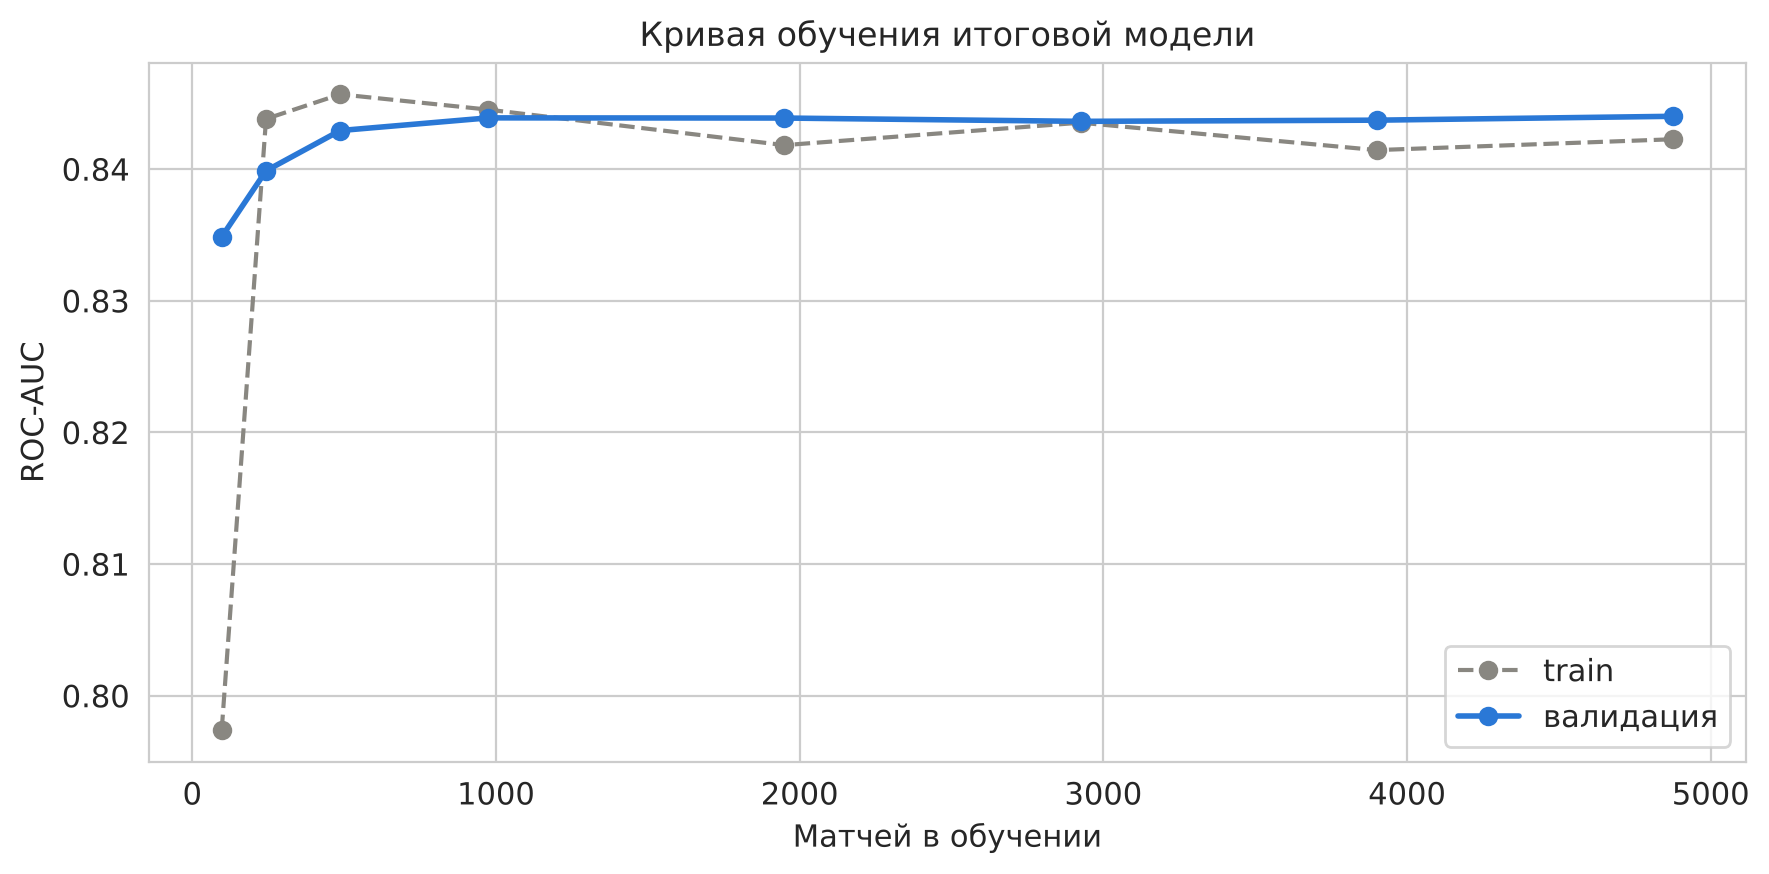

,train ROC-AUC,val ROC-AUC
Матчей в обучении,,
97,0.7974,0.8349
243,0.8438,0.8399
487,0.8457,0.8429
975,0.8445,0.8439
1950,0.8418,0.8439
2925,0.8435,0.8436
3900,0.8414,0.8437
4876,0.8423,0.8440


In [66]:
main_match_ids = np.array(main_ids)
rng = np.random.RandomState(RANDOM_STATE)
rng.shuffle(main_match_ids)

lc_rows = []
for share in [0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
    ids_part = main_match_ids[:int(len(main_match_ids) * share)]
    part = train[train['match_id'].isin(ids_part)]
    model = make_pipe(new_logreg()).fit(part[features], part[target])
    lc_rows.append({'Матчей в обучении': len(ids_part),
                    'train ROC-AUC': roc_auc_score(part[target], model.predict_proba(part[features])[:, 1]),
                    'val ROC-AUC': roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])})
learning = pd.DataFrame(lc_rows).set_index('Матчей в обучении')
learning.to_csv('results/learning_curve.csv')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(learning.index, learning['train ROC-AUC'], marker='o', color=C_GRAY, linestyle='--', label='train')
ax.plot(learning.index, learning['val ROC-AUC'], marker='o', color=C_BLUE, linewidth=2, label='валидация')
ax.set_title('Кривая обучения итоговой модели')
ax.set_xlabel('Матчей в обучении')
ax.set_ylabel('ROC-AUC')
ax.legend()
plt.tight_layout()
plt.savefig('figures/learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

learning.round(4)

**Выводы из дополнительных исследований.**

**Ablation (12.1).** Без экономики CV ROC-AUC падает с 0,8421 до 0,8210 — это самая большая потеря. Без объектов — 0,8384 (−0,004), в основном за счёт драконов. Без убийств, без «кто первый» и без минуты качество не меняется (0,8419–0,8421). При этом сами по себе убийства дают 0,784, объекты — 0,787: это сильные признаки, но их информация уже есть в золоте.

**Золото по ролям (12.2).** 1 000 золота преимущества на ADC добавляет к логиту 0,45, на миде — 0,34, на топе — 0,30, в лесу — 0,18, на саппорте — 0,08. Это коэффициенты одной модели, а золото ролей связано между собой, поэтому значения ориентировочные. Качество от добавления ролей растёт с 0,8421 до 0,8440, в пределах одного std (0,004), поэтому в итоговую модель они не включены.

**Драфт (12.3).** Сам по себе драфт почти ничего не говорит о победителе: CV ROC-AUC 0,54. Вместе с состоянием игры он добавляет 0,004 (0,8461 против 0,8418; прирост есть во всех пяти фолдах, от 0,001 до 0,009). Это около одного std по фолдам, а столбцов становится на 280 больше, поэтому в итоговую модель драфт не включён.

**Анализ ошибок (12.4).** Модель ошибается в 25,7% срезов теста. 49% всех ошибок приходится на срезы с перевесом до 2% золота, ещё 38% — на перевес 2–5%; при перевесе больше 10% точность 99%. Камбэки — свойство игры: команда, которая ведёт по золоту, в итоге проигрывает в 32% матчей на 10-й минуте, в 22% на 20-й и в 16% на 30-й. После 30-й минуты доля камбэков снова растёт (21% на 40-й), и это объясняет падение качества на поздних срезах.

**Проверка на будущем (12.5).** Модель, обученная только на матчах 2014–2016 годов, на матчах 2017–2018 годов работает так же, как модель, видевшая все годы: ROC-AUC 0,8153 против 0,8158. Сами матчи 2017–2018 годов предсказываются хуже, чем тест в целом (0,816 против 0,832); причина не исследовалась.

**Утечка (12.6).** Три признака из итоговой статистики матча дают ROC-AUC 0,9989. Так выглядела бы ошибка, от которой защищает правило «только события до минуты `T`».

**Кривая обучения (12.7).** Качество на валидации выходит на плато уже на тысяче матчей (0,8439) и дальше не растёт. Ещё матчи того же вида модель не улучшат: ей нужна новая информация.

## 13. Выводы

**1. Модель оценивает шанс победы на любой минуте матча, и её вероятностям можно верить.** Итоговая модель — логистическая регрессия с L1-регуляризацией: на входе 17 признаков, ненулевых коэффициентов 11 из 23. Test ROC-AUC 0,832 по всем минутам; 0,740 на 10-й минуте, 0,854 на 20-й, 0,911 на 30-й. Когда на 10–35-й минутах модель говорит «80% и больше», она права в 88–94% случаев.

**2. Почти вся информация о победителе содержится в перевесе по золоту.** Правило «у кого больше золота» даёт accuracy 73,6%, модель — 74,3%. Убийства и башни сильны сами по себе, но к золоту ничего не добавляют. Модель полезнее правила тем, что выдаёт вероятность, а не просто «кто впереди».

**3. Важность признаков меняется по ходу матча.** В ранней игре всё решает золото. С середины игры отдельный вклад дают драконы и темп набора преимущества, и к поздней игре их вес растёт. Это подтверждают коэффициенты, permutation importance и SHAP.

**4. Сложные модели не лучше простой.** Логистическая регрессия, бустинг, MLP, стекинг и блендинг дают test ROC-AUC 0,831–0,832, а на кросс-валидации различаются меньше чем на одно стандартное отклонение. Выбрана самая простая и объяснимая модель.

**5. Потолок качества задаёт сама игра.** Команда, ведущая по золоту на 20-й минуте, проигрывает 22% матчей. 87% ошибок модели приходится на срезы с перевесом меньше 5% золота. Кривая обучения вышла на плато: дополнительные матчи качество не поднимут.

**Что это даёт для задачи.** Для трансляции получается готовый показатель «шанс победы» с объяснением, из чего он складывается. Для тренерского разбора — количественные ответы: дракон важен сверх золота, которое за него дают; преимущество на 20-й минуте не гарантирует победу.

**Ограничения.**

- Данные — профессиональные матчи 2014–2018 годов; для текущей версии игры модель нужно обучить на свежих матчах.
- В данных нет опыта, добитых миньонов, предметов и силы команд. Вероятно, этого не хватает для ранних минут, где модель слаба.
- Модель обучена на срезах раз в 5 минут, а график шанса строится на каждой минуте; качество на промежуточных минутах отдельно не проверялось.
- Оценка на test (0,832) ниже оценки на кросс-валидации (0,842) из-за состава тестовой выборки; качество на новых матчах известно с точностью около ±0,007.
- Часть объяснений — предположения, а не результаты расчёта (почему драконы важны сверх золота, почему дерево хуже). В тексте они помечены.

**Что улучшить.** Добавить силу команд и драфт (он даёт +0,004 на кросс-валидации; сохранится ли прирост на новых сезонах, не проверялось), опыт и предметы из другого источника.

In [67]:
print(f'Ноутбук выполнен за {(time.time() - NOTEBOOK_START) / 60:.1f} мин')

Ноутбук выполнен за 10.1 мин
